In [1]:
# Block 1: Load and inspect the APR18 LAOS records

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

DATA_PATH = Path("./APR18.xlsx")
SHEET_NAME = "LAOS"

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"File not found: {DATA_PATH.resolve()}"
    )

excel_file = pd.ExcelFile(DATA_PATH)

print("Available sheets:")
print(excel_file.sheet_names)

laos_raw = pd.read_excel(
    excel_file,
    sheet_name=SHEET_NAME,
    header=None,
)

apr18_records = {}
inspection_rows = []
empty_conditions = []

header_pattern = re.compile(
    r"omega\s*=\s*([0-9.]+).*Gamma\s*=\s*([0-9.]+)",
    flags=re.IGNORECASE,
)

for column_start in range(laos_raw.shape[1]):
    header_value = laos_raw.iloc[0, column_start]

    if not isinstance(header_value, str):
        continue

    match = header_pattern.search(header_value)

    if match is None:
        continue

    omega_rad_s = float(match.group(1))
    gamma_nominal = float(match.group(2))

    case_name = (
        f"omega_{omega_rad_s:g}_gamma_{gamma_nominal:g}"
    )

    block = laos_raw.iloc[
        4:, column_start:column_start + 3
    ]

    if block.isna().all().all():
        empty_conditions.append(case_name)
        continue

    if block.shape[1] != 3:
        raise ValueError(
            f"Incomplete data columns for {case_name}"
        )

    column_labels = (
        laos_raw.iloc[
            2, column_start:column_start + 3
        ]
        .astype(str)
        .str.strip()
        .tolist()
    )

    unit_labels = (
        laos_raw.iloc[
            3, column_start:column_start + 3
        ]
        .astype(str)
        .str.strip()
        .tolist()
    )

    if column_labels != ["Step time", "Stress", "Strain"]:
        raise ValueError(
            f"Unexpected column labels: {column_labels}"
        )

    if unit_labels != ["s", "Pa", "%"]:
        raise ValueError(
            f"Unexpected units: {unit_labels}"
        )

    populated_rows = block.notna().any(axis=1)
    numeric_block = block.loc[populated_rows].apply(
        pd.to_numeric,
        errors="coerce",
    )

    if not np.isfinite(
        numeric_block.to_numpy(dtype=float)
    ).all():
        raise ValueError(
            f"Missing or nonnumeric values in {case_name}"
        )

    data = numeric_block.copy()
    data.columns = [
        "time_s",
        "stress_Pa",
        "strain_percent",
    ]
    data = data.reset_index(drop=True)

    data["strain"] = data["strain_percent"] / 100.0

    times_s = data["time_s"].to_numpy()
    time_steps_s = np.diff(times_s)

    if len(data) < 4 or np.any(time_steps_s <= 0):
        raise ValueError(
            f"Invalid timestamps in {case_name}"
        )

    median_dt_s = float(np.median(time_steps_s))
    span_s = float(times_s[-1] - times_s[0])

    fundamental_hz = omega_rad_s / (2.0 * np.pi)
    period_s = 1.0 / fundamental_hz

    relative_dt_deviation = float(
        np.max(np.abs(time_steps_s - median_dt_s))
        / median_dt_s
    )

    apr18_records[case_name] = {
        "data": data,
        "omega_rad_s": omega_rad_s,
        "gamma_nominal": gamma_nominal,
        "fundamental_hz": fundamental_hz,
        "period_s": period_s,
        "median_sampling_hz": 1.0 / median_dt_s,
    }

    inspection_rows.append(
        {
            "case": case_name,
            "n_samples": len(data),
            "first_time_s": times_s[0],
            "last_time_s": times_s[-1],
            "record_span_s": span_s,
            "median_sampling_hz": 1.0 / median_dt_s,
            "max_dt_deviation_percent": (
                100.0 * relative_dt_deviation
            ),
            "fundamental_hz": fundamental_hz,
            "period_s": period_s,
            "cycles_in_record_span": span_s / period_s,
        }
    )

apr18_data_summary = pd.DataFrame(inspection_rows)

if apr18_data_summary.empty:
    raise ValueError("No populated LAOS records were found.")

print("\nPopulated LAOS records:")
display(apr18_data_summary.round(4))

print("\nConditions without numerical data:")
print(empty_conditions)

first_case = next(iter(apr18_records))

print(f"\nFirst rows of {first_case}:")
display(apr18_records[first_case]["data"].head())

print("\nOriginal timestamps and initial samples are retained.")
print("No resampling, baseline selection, or detection is applied.")
print("Each LAOS condition is stored as a separate record.")

/Users/g.y/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/g.y/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Available sheets:
['SS SAOS', 'steps', 'Cessation', 'UDLAOS', 'LAOS']

Populated LAOS records:


,case,n_samples,first_time_s,last_time_s,record_span_s,median_sampling_hz,max_dt_deviation_percent,fundamental_hz,period_s,cycles_in_record_span
0,omega_1_gamma_0.5,1996,0.0202,39.9953,39.9751,50.0,1.5,0.1592,6.2832,6.3622
1,omega_1_gamma_1,1996,0.0201,39.9953,39.9752,50.0,1.5,0.1592,6.2832,6.3622
2,omega_1_gamma_5,1996,0.0202,39.9953,39.9751,50.0,1.5,0.1592,6.2832,6.3622
3,omega_1_gamma_10,1996,0.0203,39.9953,39.9750,50.0,1.5,0.1592,6.2832,6.3622
4,omega_1_gamma_50,1996,0.0202,39.9953,39.9751,50.0,1.5,0.1592,6.2832,6.3622
5,omega_1_gamma_100,1996,0.0201,39.9952,39.9751,50.0,1.5,0.1592,6.2832,6.3622



Conditions without numerical data:
['omega_5_gamma_0.5', 'omega_5_gamma_1', 'omega_5_gamma_5', 'omega_5_gamma_10', 'omega_5_gamma_50', 'omega_5_gamma_100']

First rows of omega_1_gamma_0.5:


,time_s,stress_Pa,strain_percent,strain
0,0.020210,0.762682,98.898200,0.988982
1,0.040352,-0.037002,-0.186446,-0.001864
2,0.060371,0.037183,2.513020,0.025130
3,0.080391,0.026102,3.450230,0.034502
4,0.100288,0.012113,4.450510,0.044505



Original timestamps and initial samples are retained.
No resampling, baseline selection, or detection is applied.
Each LAOS condition is stored as a separate record.


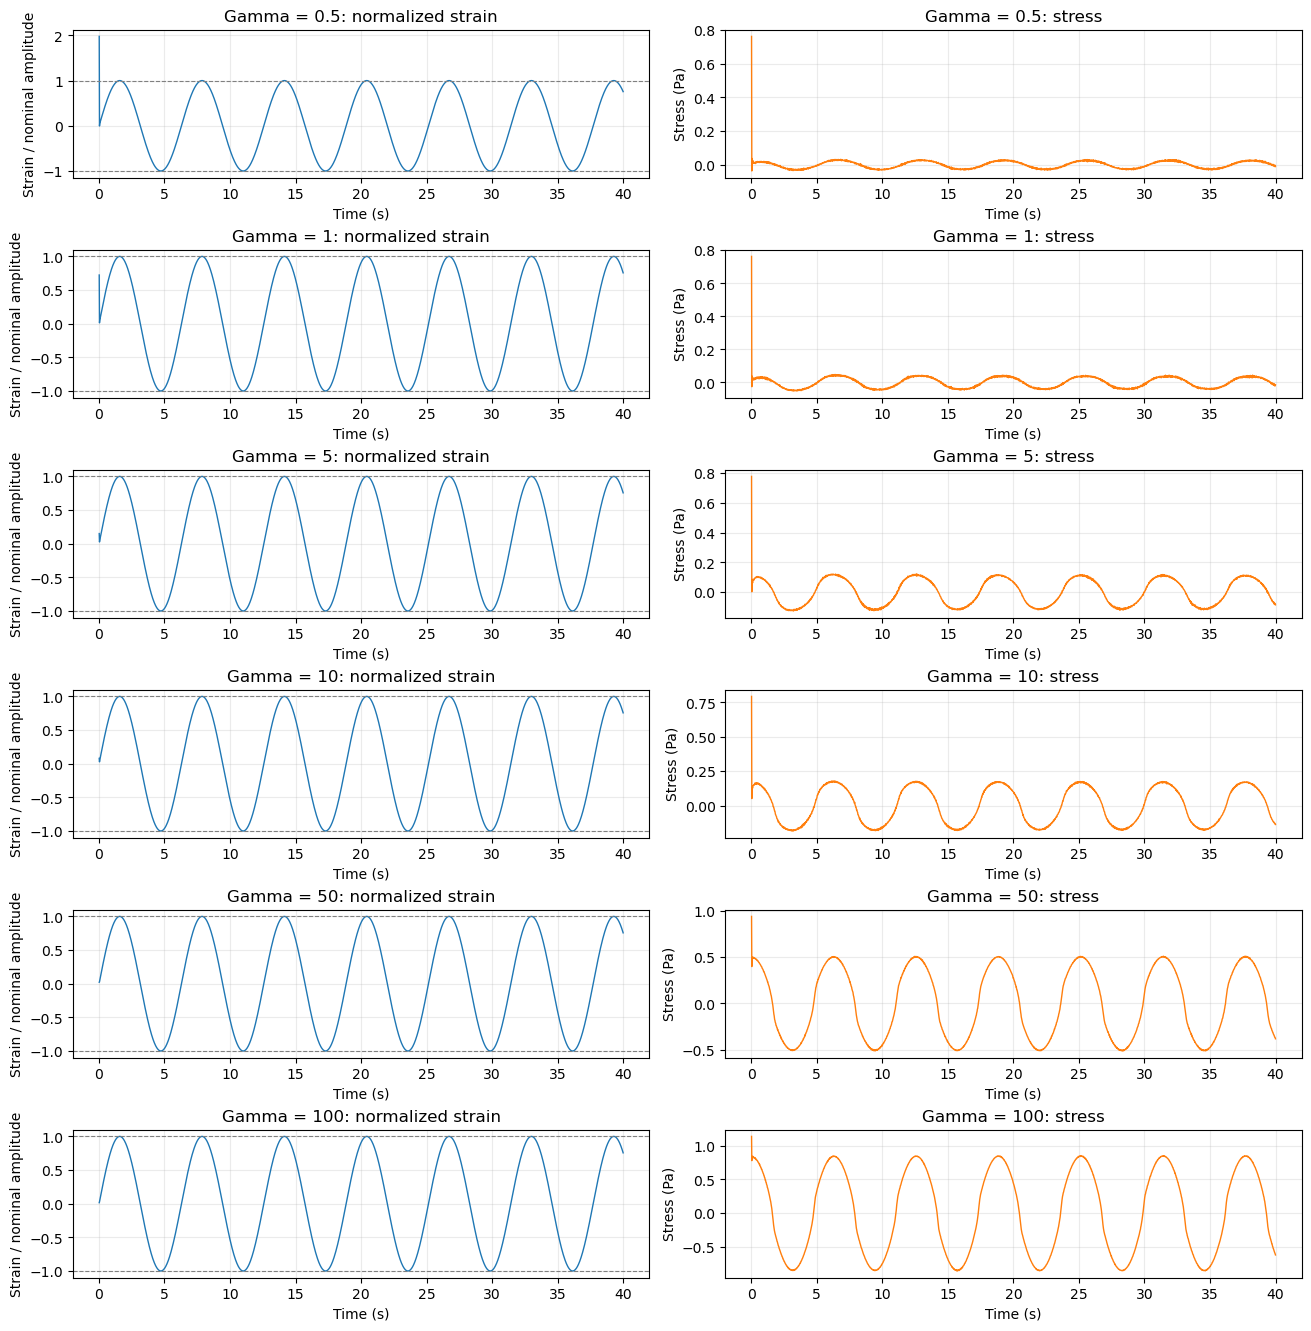

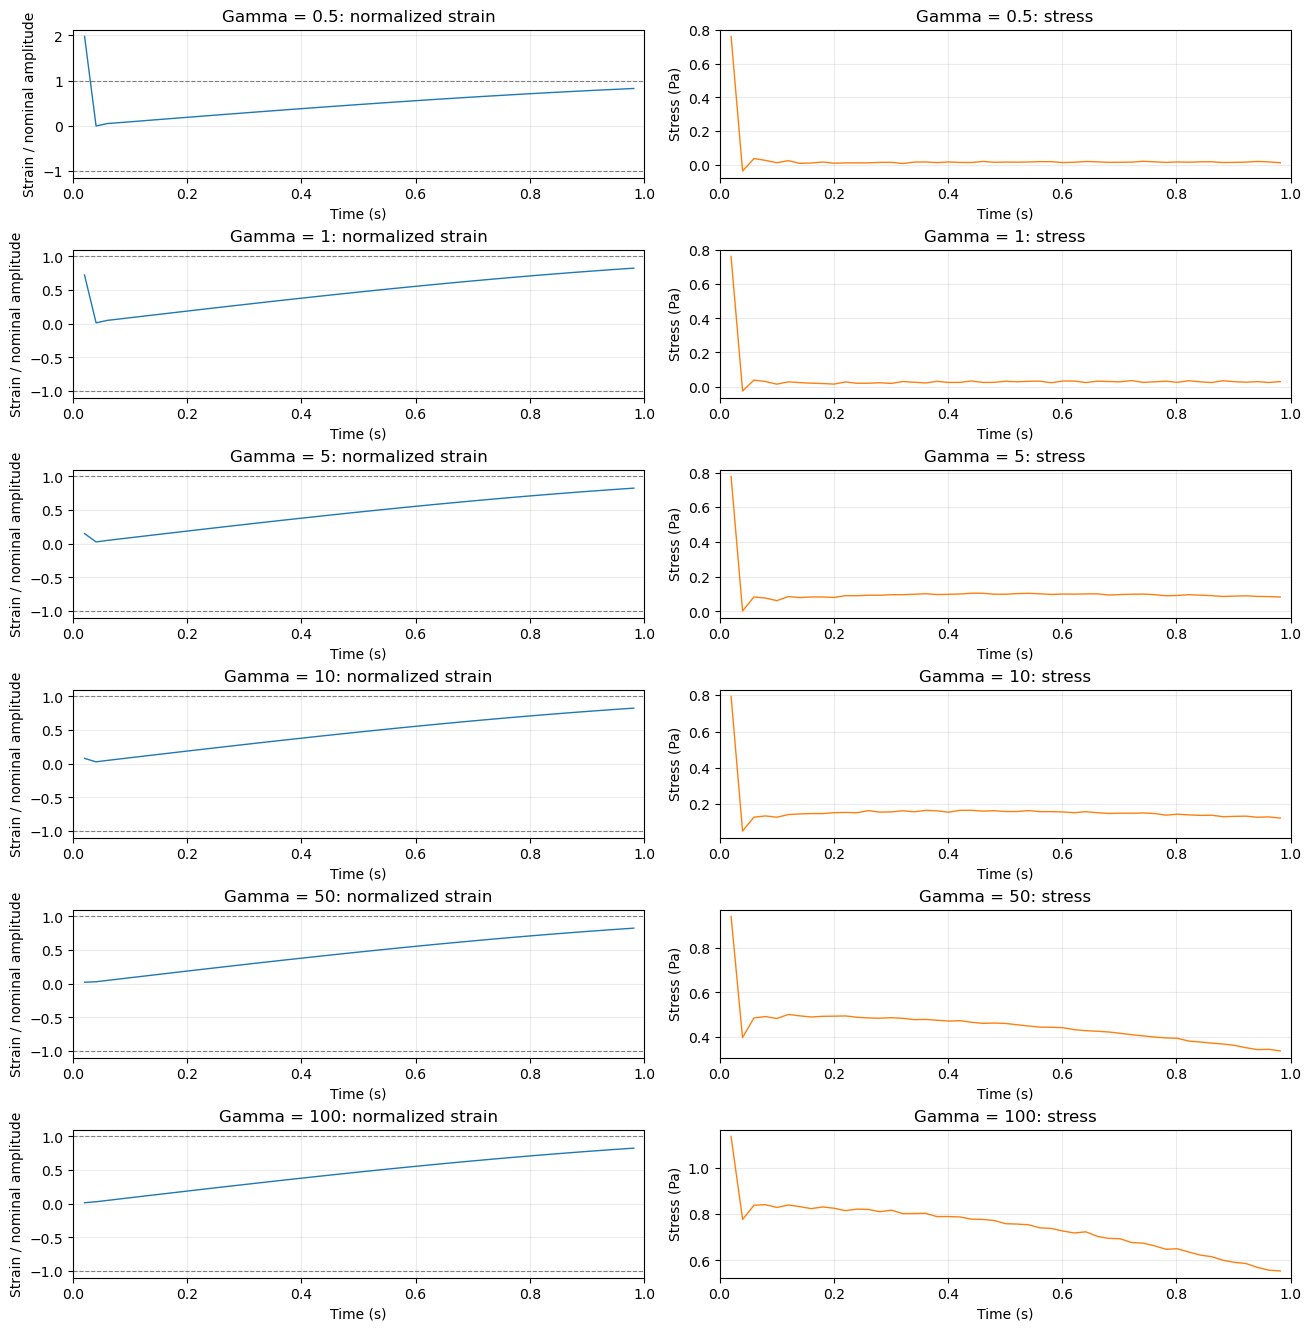

Initial sample inspection:


,case,first_time_s,first_stress_Pa,first_normalized_strain,samples_in_first_second
0,omega_1_gamma_0.5,0.02021,0.76268,1.97796,49
1,omega_1_gamma_1,0.02011,0.76308,0.72330,49
2,omega_1_gamma_5,0.02018,0.77798,0.15067,49
3,omega_1_gamma_10,0.02025,0.79401,0.07905,49
4,omega_1_gamma_50,0.02023,0.93959,0.02178,49
5,omega_1_gamma_100,0.02013,1.13766,0.01486,49


Dashed lines mark the nominal normalized strain limits.
No samples have been removed or modified.
These plots do not establish a stable baseline or ground truth.


In [2]:
# Block 2: Inspect the full records and initial transients

INITIAL_VIEW_S = 1.0

def plot_apr18_raw_records(records, time_interval_s=None):
    n_records = len(records)

    figure, axes = plt.subplots(
        n_records,
        2,
        figsize=(13, 2.2 * n_records),
        squeeze=False,
        constrained_layout=True,
    )

    for row_index, (case_name, record) in enumerate(records.items()):
        data = record["data"]

        times_s = data["time_s"].to_numpy()
        stress_pa = data["stress_Pa"].to_numpy()
        normalized_strain = (
            data["strain"].to_numpy()
            / record["gamma_nominal"]
        )

        if time_interval_s is None:
            selection = np.ones(len(data), dtype=bool)
        else:
            start_s, end_s = time_interval_s
            selection = (
                (times_s >= start_s)
                & (times_s <= end_s)
            )

        strain_axis = axes[row_index, 0]
        stress_axis = axes[row_index, 1]

        strain_axis.plot(
            times_s[selection],
            normalized_strain[selection],
            color="tab:blue",
            linewidth=1.0,
        )

        strain_axis.axhline(
            1.0,
            color="gray",
            linestyle="--",
            linewidth=0.8,
        )
        strain_axis.axhline(
            -1.0,
            color="gray",
            linestyle="--",
            linewidth=0.8,
        )

        stress_axis.plot(
            times_s[selection],
            stress_pa[selection],
            color="tab:orange",
            linewidth=1.0,
        )

        gamma_label = f"{record['gamma_nominal']:g}"

        strain_axis.set_title(
            f"Gamma = {gamma_label}: normalized strain"
        )
        stress_axis.set_title(
            f"Gamma = {gamma_label}: stress"
        )

        strain_axis.set_ylabel("Strain / nominal amplitude")
        stress_axis.set_ylabel("Stress (Pa)")

        for axis in (strain_axis, stress_axis):
            axis.set_xlabel("Time (s)")
            axis.grid(alpha=0.25)

            if time_interval_s is not None:
                axis.set_xlim(time_interval_s)

    return figure


apr18_full_waveform_figure = plot_apr18_raw_records(
    apr18_records
)
plt.show()

apr18_initial_waveform_figure = plot_apr18_raw_records(
    apr18_records,
    time_interval_s=(0.0, INITIAL_VIEW_S),
)
plt.show()


initial_sample_rows = []

for case_name, record in apr18_records.items():
    data = record["data"]
    first_sample = data.iloc[0]

    initial_sample_rows.append(
        {
            "case": case_name,
            "first_time_s": first_sample["time_s"],
            "first_stress_Pa": first_sample["stress_Pa"],
            "first_normalized_strain": (
                first_sample["strain"]
                / record["gamma_nominal"]
            ),
            "samples_in_first_second": int(
                (data["time_s"] <= INITIAL_VIEW_S).sum()
            ),
        }
    )

apr18_initial_sample_summary = pd.DataFrame(
    initial_sample_rows
)

print("Initial sample inspection:")
display(apr18_initial_sample_summary.round(5))

print("Dashed lines mark the nominal normalized strain limits.")
print("No samples have been removed or modified.")
print("These plots do not establish a stable baseline or ground truth.")

Preparation summary:


,case,original_samples,excluded_initial_samples,retained_original_samples,uniform_samples,prepared_first_time_s,prepared_last_time_s,sampling_hz,retained_cycles
0,omega_1_gamma_0.5,1996,4,1992,1994,0.12,39.98,50.0,6.3439
1,omega_1_gamma_1,1996,4,1992,1994,0.12,39.98,50.0,6.3439
2,omega_1_gamma_5,1996,4,1992,1994,0.12,39.98,50.0,6.3439
3,omega_1_gamma_10,1996,4,1992,1994,0.12,39.98,50.0,6.3439
4,omega_1_gamma_50,1996,4,1992,1994,0.12,39.98,50.0,6.3439
5,omega_1_gamma_100,1996,4,1992,1994,0.12,39.98,50.0,6.3439


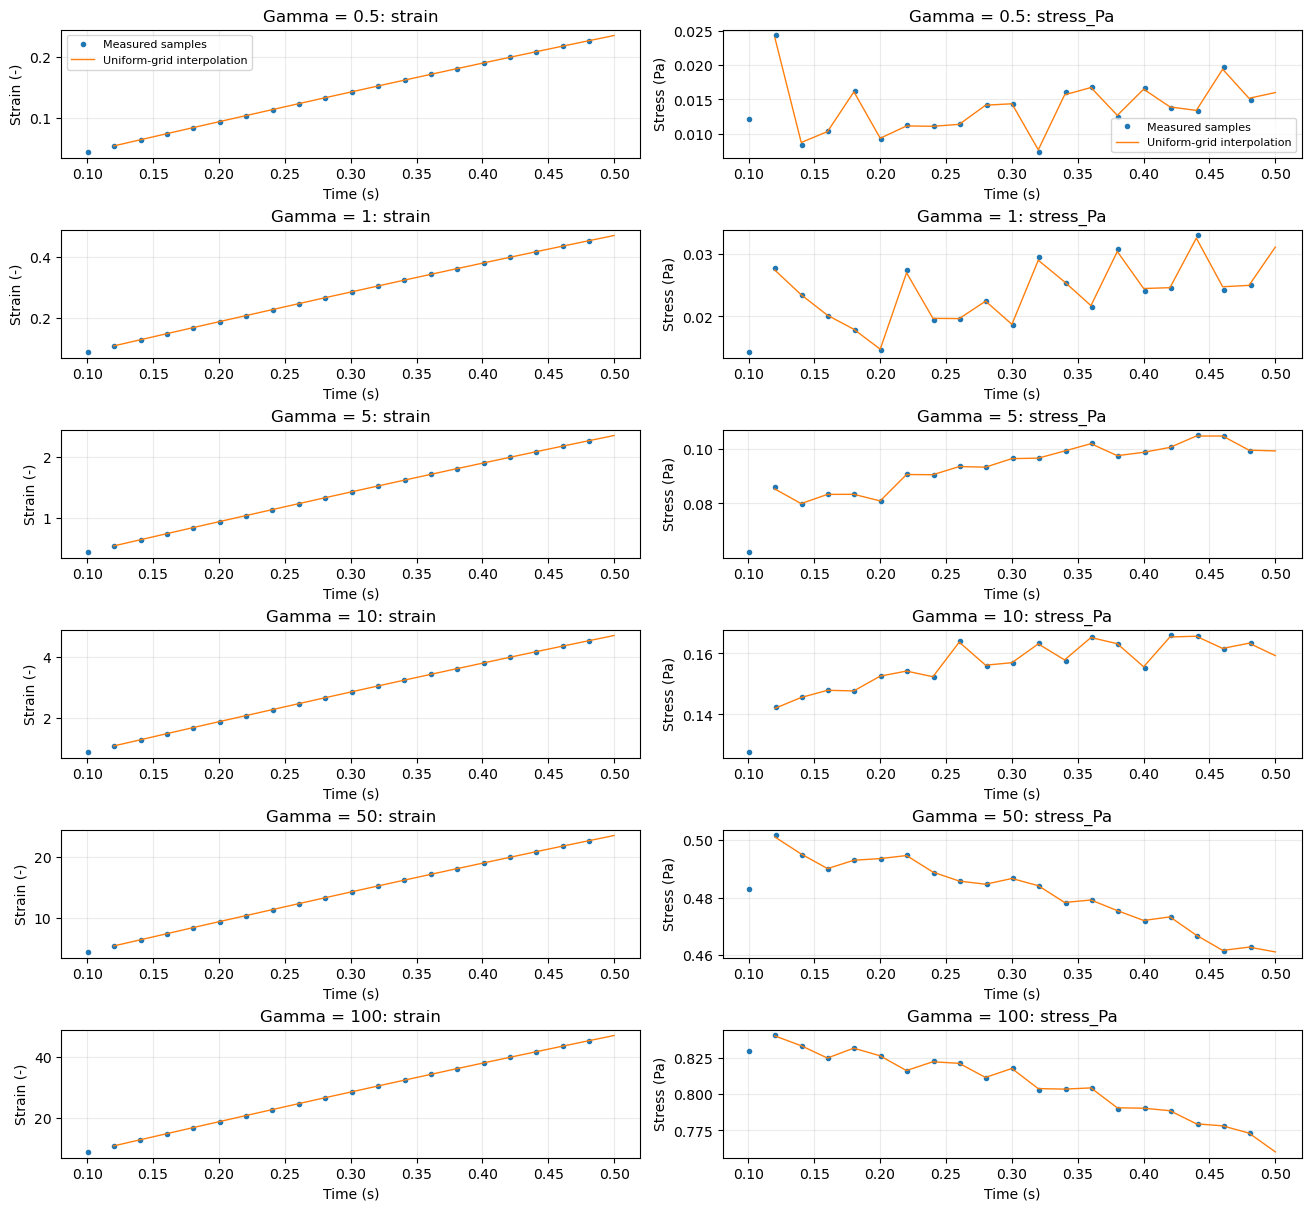

Original records remain unchanged in apr18_records.
Interpolation is linear and stays within measured time bounds.
The startup guard is exploratory, not a verified settling time.
No baseline or alarm rule has been applied.


In [3]:
# Block 3: Prepare uniformly sampled records for spectral analysis

STARTUP_GUARD_S = 0.1
TARGET_FS_HZ = 50.0

apr18_prepared_records = {}
preparation_rows = []

for case_name, record in apr18_records.items():
    original_data = record["data"]

    retained_data = original_data.loc[
        original_data["time_s"] >= STARTUP_GUARD_S
    ].copy()

    if len(retained_data) < 4:
        raise ValueError(
            f"Insufficient retained samples in {case_name}"
        )

    original_times = retained_data["time_s"].to_numpy()

    # Keep the uniform grid inside the retained time range.
    first_grid_index = int(
        np.ceil(original_times[0] * TARGET_FS_HZ)
    )
    last_grid_index = int(
        np.floor(original_times[-1] * TARGET_FS_HZ)
    )

    uniform_times = (
        np.arange(first_grid_index, last_grid_index + 1)
        / TARGET_FS_HZ
    )

    uniform_stress = np.interp(
        uniform_times,
        original_times,
        retained_data["stress_Pa"].to_numpy(),
    )

    uniform_strain = np.interp(
        uniform_times,
        original_times,
        retained_data["strain"].to_numpy(),
    )

    prepared_data = pd.DataFrame(
        {
            "time_s": uniform_times,
            "stress_Pa": uniform_stress,
            "strain": uniform_strain,
            "strain_percent": 100.0 * uniform_strain,
        }
    )

    if not np.isfinite(
        prepared_data.to_numpy(dtype=float)
    ).all():
        raise ValueError(
            f"Nonfinite prepared values in {case_name}"
        )

    if not np.allclose(
        np.diff(uniform_times),
        1.0 / TARGET_FS_HZ,
        rtol=0.0,
        atol=1e-10,
    ):
        raise ValueError(
            f"Nonuniform prepared timestamps in {case_name}"
        )

    prepared_record = dict(record)
    prepared_record["data"] = prepared_data
    prepared_record["sampling_hz"] = TARGET_FS_HZ
    prepared_record["startup_guard_s"] = STARTUP_GUARD_S

    apr18_prepared_records[case_name] = prepared_record

    preparation_rows.append(
        {
            "case": case_name,
            "original_samples": len(original_data),
            "excluded_initial_samples": (
                len(original_data) - len(retained_data)
            ),
            "retained_original_samples": len(retained_data),
            "uniform_samples": len(prepared_data),
            "prepared_first_time_s": uniform_times[0],
            "prepared_last_time_s": uniform_times[-1],
            "sampling_hz": TARGET_FS_HZ,
            "retained_cycles": (
                (uniform_times[-1] - uniform_times[0])
                / record["period_s"]
            ),
        }
    )

apr18_preparation_summary = pd.DataFrame(
    preparation_rows
)

print("Preparation summary:")
display(apr18_preparation_summary.round(4))


# Compare measured samples and interpolated samples near the start.
preparation_figure, axes = plt.subplots(
    len(apr18_records),
    2,
    figsize=(13, 2.0 * len(apr18_records)),
    squeeze=False,
    constrained_layout=True,
)

COMPARISON_INTERVAL_S = (0.1, 0.5)

for row_index, (case_name, record) in enumerate(
    apr18_records.items()
):
    original = record["data"]
    prepared = apr18_prepared_records[case_name]["data"]

    original_mask = original["time_s"].between(
        *COMPARISON_INTERVAL_S
    )
    prepared_mask = prepared["time_s"].between(
        *COMPARISON_INTERVAL_S
    )

    for column_index, signal_name in enumerate(
        ["strain", "stress_Pa"]
    ):
        axis = axes[row_index, column_index]

        axis.plot(
            original.loc[original_mask, "time_s"],
            original.loc[original_mask, signal_name],
            "o",
            markersize=3,
            label="Measured samples",
        )

        axis.plot(
            prepared.loc[prepared_mask, "time_s"],
            prepared.loc[prepared_mask, signal_name],
            "-",
            linewidth=1.0,
            label="Uniform-grid interpolation",
        )

        axis.set_title(
            f"Gamma = {record['gamma_nominal']:g}: {signal_name}"
        )
        axis.set_xlabel("Time (s)")
        axis.set_ylabel(
            "Strain (-)"
            if signal_name == "strain"
            else "Stress (Pa)"
        )
        axis.grid(alpha=0.25)

        if row_index == 0:
            axis.legend(fontsize=8)

plt.show()

print("Original records remain unchanged in apr18_records.")
print("Interpolation is linear and stays within measured time bounds.")
print("The startup guard is exploratory, not a verified settling time.")
print("No baseline or alarm rule has been applied.")

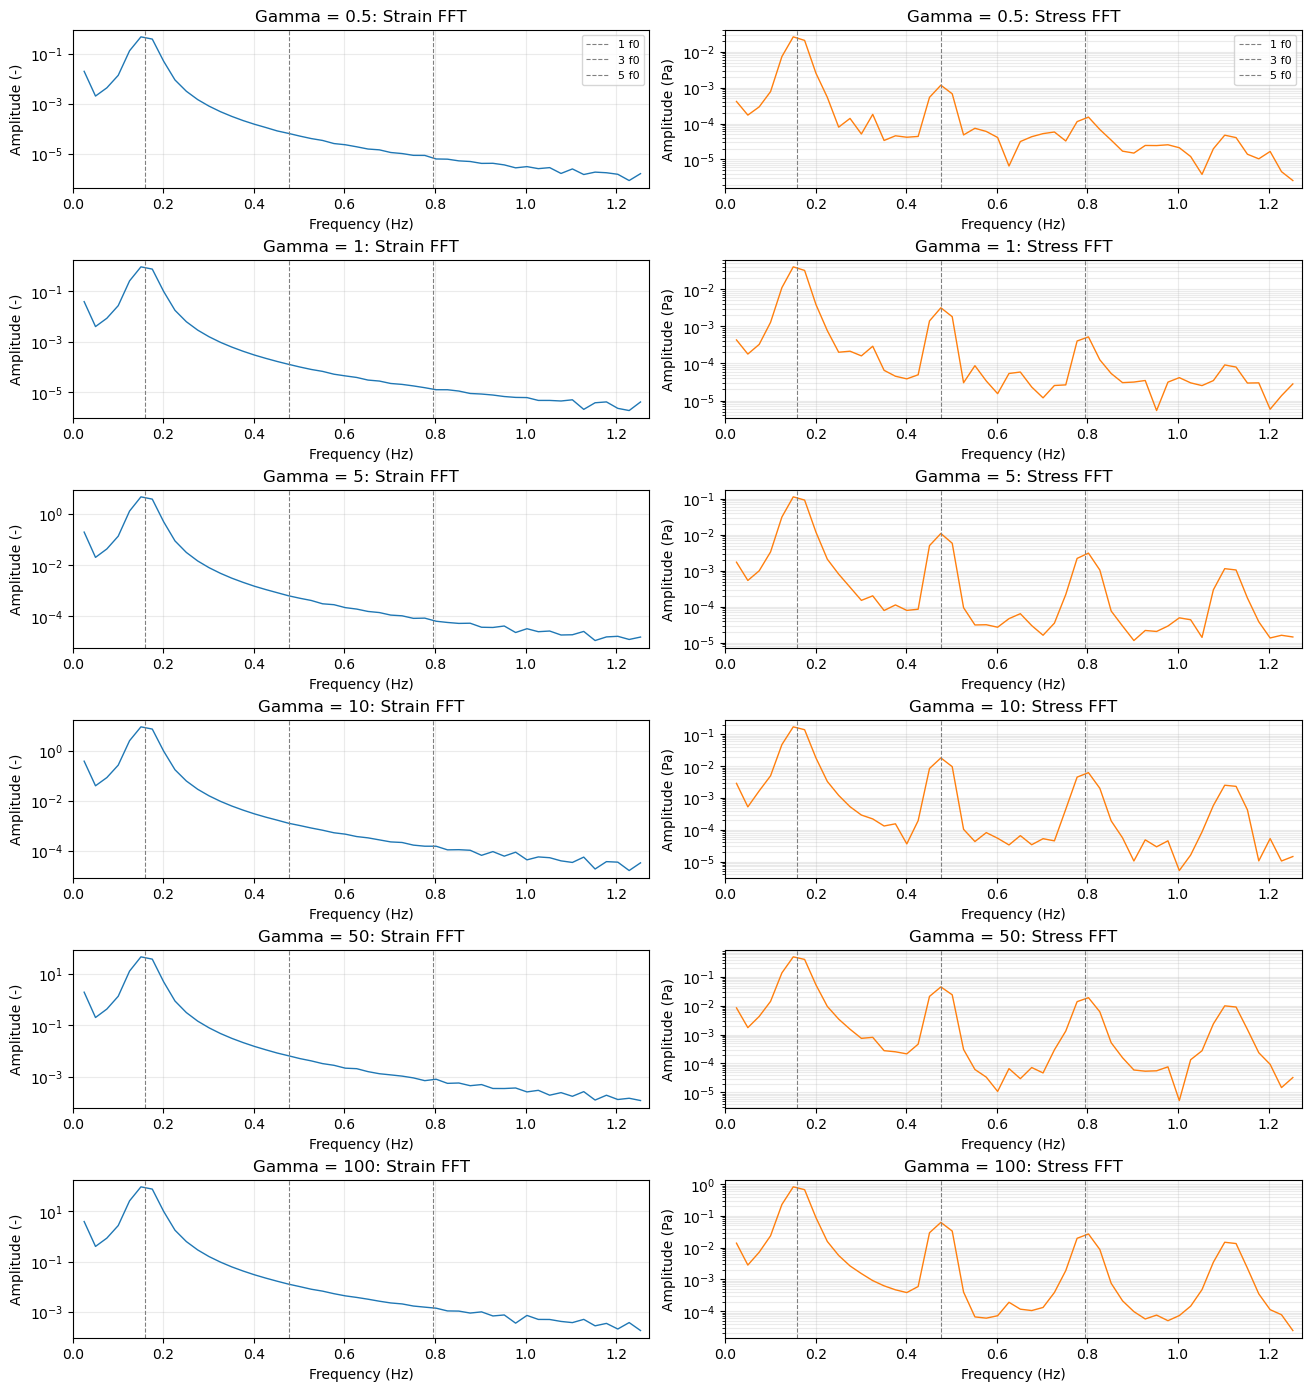

FFT frequency inspection:


,case,nominal_fundamental_Hz,dominant_strain_fft_bin_Hz,nearest_fundamental_fft_bin_Hz,frequency_bin_spacing_Hz,third_harmonic_target_Hz,fifth_harmonic_target_Hz
0,omega_1_gamma_0.5,0.159155,0.150451,0.150451,0.025075,0.477465,0.795775
1,omega_1_gamma_1,0.159155,0.150451,0.150451,0.025075,0.477465,0.795775
2,omega_1_gamma_5,0.159155,0.150451,0.150451,0.025075,0.477465,0.795775
3,omega_1_gamma_10,0.159155,0.150451,0.150451,0.025075,0.477465,0.795775
4,omega_1_gamma_50,0.159155,0.150451,0.150451,0.025075,0.477465,0.795775
5,omega_1_gamma_100,0.159155,0.150451,0.150451,0.025075,0.477465,0.795775


A periodic Hann window and mean removal are applied.
The spectra use the complete prepared records.
FFT bin amplitudes are not exact harmonic amplitudes.
No change time is estimated in this block.


In [4]:
# Block 4: Inspect the full-record FFT spectra

HARMONIC_ORDERS = [1, 3, 5]
DISPLAY_MAX_HARMONIC = 8.0

def compute_apr18_fft(signal_values, sampling_hz):
    values = np.asarray(signal_values, dtype=float)

    if values.ndim != 1 or len(values) < 4:
        raise ValueError("A one-dimensional signal is required.")

    if not np.isfinite(values).all():
        raise ValueError("The signal contains nonfinite values.")

    n_samples = len(values)

    centered_values = values - np.mean(values)

    sample_indices = np.arange(n_samples)
    weights = (
        0.5
        - 0.5 * np.cos(
            2.0 * np.pi * sample_indices / n_samples
        )
    )

    coefficients = np.fft.rfft(
        centered_values * weights
    )

    frequencies_hz = np.fft.rfftfreq(
        n_samples,
        d=1.0 / sampling_hz,
    )

    amplitudes = (
        np.abs(coefficients) / np.sum(weights)
    )

    if n_samples % 2 == 0:
        amplitudes[1:-1] *= 2.0
    else:
        amplitudes[1:] *= 2.0

    return {
        "frequencies_Hz": frequencies_hz,
        "bin_amplitude": amplitudes,
        "frequency_bin_spacing_Hz": (
            sampling_hz / n_samples
        ),
    }


apr18_fft_results = {}
fft_inspection_rows = []

fft_figure, axes = plt.subplots(
    len(apr18_prepared_records),
    2,
    figsize=(13, 2.3 * len(apr18_prepared_records)),
    squeeze=False,
    constrained_layout=True,
)

for row_index, (case_name, record) in enumerate(
    apr18_prepared_records.items()
):
    data = record["data"]
    sampling_hz = record["sampling_hz"]
    fundamental_hz = record["fundamental_hz"]

    strain_spectrum = compute_apr18_fft(
        data["strain"].to_numpy(),
        sampling_hz,
    )

    stress_spectrum = compute_apr18_fft(
        data["stress_Pa"].to_numpy(),
        sampling_hz,
    )

    apr18_fft_results[case_name] = {
        "strain": strain_spectrum,
        "stress": stress_spectrum,
    }

    frequencies = strain_spectrum["frequencies_Hz"]
    strain_amplitudes = strain_spectrum["bin_amplitude"]

    positive_indices = np.flatnonzero(frequencies > 0.0)

    dominant_index = positive_indices[
        np.argmax(strain_amplitudes[positive_indices])
    ]

    nearest_fundamental_index = int(
        np.argmin(
            np.abs(frequencies - fundamental_hz)
        )
    )

    fft_inspection_rows.append(
        {
            "case": case_name,
            "nominal_fundamental_Hz": fundamental_hz,
            "dominant_strain_fft_bin_Hz": (
                frequencies[dominant_index]
            ),
            "nearest_fundamental_fft_bin_Hz": (
                frequencies[nearest_fundamental_index]
            ),
            "frequency_bin_spacing_Hz": (
                strain_spectrum["frequency_bin_spacing_Hz"]
            ),
            "third_harmonic_target_Hz": (
                3.0 * fundamental_hz
            ),
            "fifth_harmonic_target_Hz": (
                5.0 * fundamental_hz
            ),
        }
    )

    spectra_to_plot = [
        ("Strain", strain_spectrum, "Amplitude (-)"),
        ("Stress", stress_spectrum, "Amplitude (Pa)"),
    ]

    for column_index, (
        signal_label,
        spectrum,
        amplitude_label,
    ) in enumerate(spectra_to_plot):
        axis = axes[row_index, column_index]

        plot_frequencies = spectrum["frequencies_Hz"]
        plot_amplitudes = spectrum["bin_amplitude"]

        display_mask = (
            (plot_frequencies > 0.0)
            & (
                plot_frequencies
                <= DISPLAY_MAX_HARMONIC * fundamental_hz
            )
        )

        axis.semilogy(
            plot_frequencies[display_mask],
            np.maximum(
                plot_amplitudes[display_mask],
                np.finfo(float).tiny,
            ),
            color=(
                "tab:blue"
                if signal_label == "Strain"
                else "tab:orange"
            ),
            linewidth=1.0,
        )

        for harmonic_order in HARMONIC_ORDERS:
            axis.axvline(
                harmonic_order * fundamental_hz,
                color="gray",
                linestyle="--",
                linewidth=0.8,
                label=f"{harmonic_order} f0",
            )

        axis.set_xlim(
            0.0,
            DISPLAY_MAX_HARMONIC * fundamental_hz,
        )
        axis.set_title(
            f"Gamma = {record['gamma_nominal']:g}: "
            f"{signal_label} FFT"
        )
        axis.set_xlabel("Frequency (Hz)")
        axis.set_ylabel(amplitude_label)
        axis.grid(alpha=0.25, which="both")

        if row_index == 0:
            axis.legend(fontsize=8)

plt.show()

apr18_fft_inspection_summary = pd.DataFrame(
    fft_inspection_rows
)

print("FFT frequency inspection:")
display(apr18_fft_inspection_summary.round(6))

print("A periodic Hann window and mean removal are applied.")
print("The spectra use the complete prepared records.")
print("FFT bin amplitudes are not exact harmonic amplitudes.")
print("No change time is estimated in this block.")

In [6]:
# Block 5: Configure the STFT and calibrate harmonic estimation

WINDOW_CYCLES = 2.0
HOP_DURATION_S = 0.5
SPECTRAL_BAND_HARMONICS = (0.5, 8.0)

FEATURE_COLUMNS = [
    "I1_Pa",
    "I3_Pa",
    "I5_Pa",
    "I3_I1",
    "I5_I1",
    "spectral_power_Pa2",
    "spectral_entropy",
    "spectral_bandwidth_Hz",
]

apr18_stft_settings = {}
window_setting_rows = []

for case_name, record in apr18_prepared_records.items():
    sampling_hz = record["sampling_hz"]
    fundamental_hz = record["fundamental_hz"]

    n_window = int(
        round(WINDOW_CYCLES * record["period_s"] * sampling_hz)
    )
    n_hop = int(round(HOP_DURATION_S * sampling_hz))

    actual_window_s = n_window / sampling_hz
    actual_hop_s = n_hop / sampling_hz

    frequencies_hz = np.fft.rfftfreq(
        n_window,
        d=1.0 / sampling_hz,
    )

    band_low_hz = (
        SPECTRAL_BAND_HARMONICS[0] * fundamental_hz
    )
    band_high_hz = (
        SPECTRAL_BAND_HARMONICS[1] * fundamental_hz
    )

    band_mask = (
        (frequencies_hz >= band_low_hz)
        & (frequencies_hz <= band_high_hz)
    )

    n_available_windows = (
        1
        + (len(record["data"]) - n_window) // n_hop
    )

    if n_available_windows < 1:
        raise ValueError(
            f"Record too short for the window: {case_name}"
        )

    apr18_stft_settings[case_name] = {
        "n_window": n_window,
        "n_hop": n_hop,
        "sampling_hz": sampling_hz,
        "fundamental_hz": fundamental_hz,
        "window_duration_s": actual_window_s,
        "hop_duration_s": actual_hop_s,
        "spectral_band_hz": (band_low_hz, band_high_hz),
    }

    window_setting_rows.append(
        {
            "case": case_name,
            "n_window": n_window,
            "window_duration_s": actual_window_s,
            "cycles_per_window": (
                actual_window_s * fundamental_hz
            ),
            "hop_duration_s": actual_hop_s,
            "frequency_bin_spacing_Hz": (
                sampling_hz / n_window
            ),
            "band_low_Hz": band_low_hz,
            "band_high_Hz": band_high_hz,
            "n_spectral_band_bins": int(band_mask.sum()),
            "n_available_windows": n_available_windows,
        }
    )

apr18_window_settings_summary = pd.DataFrame(
    window_setting_rows
)

print("STFT window settings:")
display(apr18_window_settings_summary.round(6))


def estimate_target_harmonics(
    signal_values,
    sampling_hz,
    fundamental_hz,
):
    values = np.asarray(signal_values, dtype=float)

    if values.ndim != 1 or len(values) < 4:
        raise ValueError("A one-dimensional signal is required.")

    if not np.isfinite(values).all():
        raise ValueError("The signal contains nonfinite values.")

    n_samples = len(values)
    sample_indices = np.arange(n_samples)

    local_times_s = sample_indices / sampling_hz

    weights = (
        0.5
        - 0.5 * np.cos(
            2.0 * np.pi * sample_indices / n_samples
        )
    )

    centered_values = values - np.mean(values)

    target_frequencies_hz = (
        np.asarray([1.0, 3.0, 5.0]) * fundamental_hz
    )

    kernels = np.exp(
        -2j
        * np.pi
        * target_frequencies_hz[:, None]
        * local_times_s[None, :]
    )

    coefficients = kernels @ (centered_values * weights)

    amplitudes = (
        2.0 * np.abs(coefficients) / np.sum(weights)
    )

    return amplitudes


# Check known amplitudes at the actual APR18 window length.
first_case = next(iter(apr18_stft_settings))
calibration_settings = apr18_stft_settings[first_case]

calibration_fs = calibration_settings["sampling_hz"]
calibration_f0 = calibration_settings["fundamental_hz"]
calibration_n = calibration_settings["n_window"]

calibration_times = np.arange(calibration_n) / calibration_fs
expected_amplitudes = np.array([2.0, 0.3, 0.1])

calibration_rows = []

for phase_rad in [0.0, 0.7, 2.0]:
    known_signal = (
        2.0 * np.sin(
            2.0 * np.pi * calibration_f0
            * calibration_times + phase_rad
        )
        + 0.3 * np.sin(
            2.0 * np.pi * 3.0 * calibration_f0
            * calibration_times + 0.4 + phase_rad
        )
        + 0.1 * np.sin(
            2.0 * np.pi * 5.0 * calibration_f0
            * calibration_times - 0.2 + phase_rad
        )
    )

    estimated_amplitudes = estimate_target_harmonics(
        known_signal,
        calibration_fs,
        calibration_f0,
    )

    for harmonic_order, expected, estimated in zip(
        [1, 3, 5],
        expected_amplitudes,
        estimated_amplitudes,
    ):
        calibration_rows.append(
            {
                "phase_rad": phase_rad,
                "harmonic_order": harmonic_order,
                "expected_amplitude": expected,
                "estimated_amplitude": estimated,
                "relative_error_percent": (
                    100.0 * abs(estimated - expected) / expected
                ),
            }
        )

apr18_harmonic_calibration = pd.DataFrame(
    calibration_rows
)

print("\nKnown-signal harmonic calibration:")
display(apr18_harmonic_calibration.round(6))

print("Harmonic amplitudes use nominal target frequencies.")
print("No zero padding is required for target-frequency evaluation.")
print("Calibration checks known stationary signals only.")
print("No baseline or change-time detector is applied yet.")

STFT window settings:


,case,n_window,window_duration_s,cycles_per_window,hop_duration_s,frequency_bin_spacing_Hz,band_low_Hz,band_high_Hz,n_spectral_band_bins,n_available_windows
0,omega_1_gamma_0.5,628,12.56,1.998986,0.5,0.079618,0.079577,1.27324,15,55
1,omega_1_gamma_1,628,12.56,1.998986,0.5,0.079618,0.079577,1.27324,15,55
2,omega_1_gamma_5,628,12.56,1.998986,0.5,0.079618,0.079577,1.27324,15,55
3,omega_1_gamma_10,628,12.56,1.998986,0.5,0.079618,0.079577,1.27324,15,55
4,omega_1_gamma_50,628,12.56,1.998986,0.5,0.079618,0.079577,1.27324,15,55
5,omega_1_gamma_100,628,12.56,1.998986,0.5,0.079618,0.079577,1.27324,15,55



Known-signal harmonic calibration:


,phase_rad,harmonic_order,expected_amplitude,estimated_amplitude,relative_error_percent
0,0.0,1,2.0,1.999940,0.003006
1,0.0,3,0.3,0.300049,0.016476
2,0.0,5,0.1,0.100016,0.016465
3,0.7,1,2.0,1.999999,0.000060
4,0.7,3,0.3,0.300069,0.023133
5,0.7,5,0.1,0.100021,0.021336
6,2.0,1,2.0,2.000056,0.002807
7,2.0,3,0.3,0.300071,0.023503
8,2.0,5,0.1,0.100030,0.030231


Harmonic amplitudes use nominal target frequencies.
No zero padding is required for target-frequency evaluation.
Calibration checks known stationary signals only.
No baseline or change-time detector is applied yet.


In [7]:
# Block 6: Extract stress features and input diagnostics

def extract_apr18_window_features(
    signal_values,
    sampling_hz,
    fundamental_hz,
    spectral_band_hz,
):
    values = np.asarray(signal_values, dtype=float)
    n_samples = len(values)

    if values.ndim != 1 or n_samples < 4:
        raise ValueError("A one-dimensional signal is required.")

    if not np.isfinite(values).all():
        raise ValueError("The signal contains nonfinite values.")

    harmonic_amplitudes = estimate_target_harmonics(
        values,
        sampling_hz,
        fundamental_hz,
    )

    i1, i3, i5 = harmonic_amplitudes

    # This is a numerical guard, not a signal-quality threshold.
    valid_fundamental = i1 > np.finfo(float).eps

    sample_indices = np.arange(n_samples)
    weights = (
        0.5
        - 0.5 * np.cos(
            2.0 * np.pi * sample_indices / n_samples
        )
    )

    centered_values = values - np.mean(values)
    windowed_values = centered_values * weights

    coefficients = np.fft.rfft(windowed_values)
    frequencies_hz = np.fft.rfftfreq(
        n_samples,
        d=1.0 / sampling_hz,
    )

    one_sided_factors = np.ones(len(coefficients))

    if n_samples % 2 == 0:
        one_sided_factors[1:-1] = 2.0
    else:
        one_sided_factors[1:] = 2.0

    psd = (
        one_sided_factors
        * np.abs(coefficients) ** 2
        / (sampling_hz * np.sum(weights ** 2))
    )

    frequency_spacing_hz = sampling_hz / n_samples
    bin_power = psd * frequency_spacing_hz

    weighted_mean_square = (
        np.sum(windowed_values ** 2)
        / np.sum(weights ** 2)
    )

    parseval_relative_error = (
        abs(np.sum(bin_power) - weighted_mean_square)
        / max(weighted_mean_square, np.finfo(float).tiny)
    )

    band_low_hz, band_high_hz = spectral_band_hz
    band_mask = (
        (frequencies_hz >= band_low_hz)
        & (frequencies_hz <= band_high_hz)
    )

    band_frequencies = frequencies_hz[band_mask]
    band_bin_power = bin_power[band_mask]
    band_power = float(np.sum(band_bin_power))

    if len(band_frequencies) < 2 or band_power <= 0.0:
        raise ValueError("The spectral band is not usable.")

    probabilities = band_bin_power / band_power
    positive_probabilities = probabilities[
        probabilities > 0.0
    ]

    spectral_entropy = (
        -np.sum(
            positive_probabilities
            * np.log(positive_probabilities)
        )
        / np.log(len(probabilities))
    )

    spectral_centroid_hz = float(
        np.sum(probabilities * band_frequencies)
    )

    spectral_bandwidth_hz = float(
        np.sqrt(
            np.sum(
                probabilities
                * (
                    band_frequencies - spectral_centroid_hz
                ) ** 2
            )
        )
    )

    return {
        "I1_Pa": float(i1),
        "I3_Pa": float(i3),
        "I5_Pa": float(i5),
        "I3_I1": (
            float(i3 / i1)
            if valid_fundamental else np.nan
        ),
        "I5_I1": (
            float(i5 / i1)
            if valid_fundamental else np.nan
        ),
        "spectral_power_Pa2": band_power,
        "spectral_entropy": float(spectral_entropy),
        "spectral_bandwidth_Hz": spectral_bandwidth_hz,
        "valid_fundamental": bool(valid_fundamental),
        "parseval_relative_error": (
            float(parseval_relative_error)
        ),
    }


apr18_feature_tables = {}
apr18_input_quality_tables = {}
feature_validation_rows = []

for case_name, record in apr18_prepared_records.items():
    data = record["data"]
    settings = apr18_stft_settings[case_name]

    sampling_hz = settings["sampling_hz"]
    fundamental_hz = settings["fundamental_hz"]
    n_window = settings["n_window"]
    n_hop = settings["n_hop"]

    times_s = data["time_s"].to_numpy()
    stress_pa = data["stress_Pa"].to_numpy()
    strain = data["strain"].to_numpy()

    window_starts = np.arange(
        0,
        len(data) - n_window + 1,
        n_hop,
    )

    feature_rows = []
    input_rows = []

    for start_index in window_starts:
        stop_index = start_index + n_window

        window_start_s = float(times_s[start_index])
        window_end_s = float(
            times_s[stop_index - 1] + 1.0 / sampling_hz
        )

        window_times = {
            "window_start_s": window_start_s,
            "window_center_s": (
                (window_start_s + window_end_s) / 2.0
            ),
            "window_end_s": window_end_s,
        }

        stress_features = extract_apr18_window_features(
            stress_pa[start_index:stop_index],
            sampling_hz,
            fundamental_hz,
            settings["spectral_band_hz"],
        )

        feature_rows.append(
            {**window_times, **stress_features}
        )

        input_amplitudes = estimate_target_harmonics(
            strain[start_index:stop_index],
            sampling_hz,
            fundamental_hz,
        )

        input_i1, input_i3, input_i5 = input_amplitudes
        valid_input = input_i1 > np.finfo(float).eps

        input_rows.append(
            {
                **window_times,
                "input_I1": float(input_i1),
                "input_I1_over_nominal": float(
                    input_i1 / record["gamma_nominal"]
                ),
                "input_I3_I1": (
                    float(input_i3 / input_i1)
                    if valid_input else np.nan
                ),
                "input_I5_I1": (
                    float(input_i5 / input_i1)
                    if valid_input else np.nan
                ),
            }
        )

    feature_table = pd.DataFrame(feature_rows)
    input_table = pd.DataFrame(input_rows)

    feature_values = feature_table[
        FEATURE_COLUMNS
    ].to_numpy(dtype=float)

    nonfinite_count = int(
        (~np.isfinite(feature_values)).sum()
    )

    max_parseval_error = float(
        feature_table["parseval_relative_error"].max()
    )

    if nonfinite_count > 0:
        raise ValueError(
            f"Nonfinite stress features in {case_name}"
        )

    if max_parseval_error > 1e-10:
        raise ValueError(
            f"Spectral power normalization failed: {case_name}"
        )

    if not feature_table["spectral_entropy"].between(
        -1e-10, 1.0 + 1e-10
    ).all():
        raise ValueError(
            f"Entropy outside its expected range: {case_name}"
        )

    apr18_feature_tables[case_name] = feature_table
    apr18_input_quality_tables[case_name] = input_table

    feature_validation_rows.append(
        {
            "case": case_name,
            "n_windows": len(feature_table),
            "first_window_end_s": (
                feature_table["window_end_s"].iloc[0]
            ),
            "last_window_end_s": (
                feature_table["window_end_s"].iloc[-1]
            ),
            "nonfinite_feature_values": nonfinite_count,
            "max_parseval_relative_error": max_parseval_error,
        }
    )

apr18_feature_validation_summary = pd.DataFrame(
    feature_validation_rows
)

apr18_feature_medians = pd.DataFrame(
    {
        case_name: table[FEATURE_COLUMNS].median()
        for case_name, table in apr18_feature_tables.items()
    }
).T

apr18_feature_medians.index.name = "case"

print("Feature extraction validation:")
display(apr18_feature_validation_summary)

print("\nWhole-record feature medians:")
display(apr18_feature_medians.round(6))

print("Input diagnostics are stored separately.")
print("Only complete windows are used; no padding is applied.")
print("Window end times indicate feature availability.")
print("Whole-record medians are descriptive, not baseline values.")
print("No change-time detector has been applied.")

Feature extraction validation:


,case,n_windows,first_window_end_s,last_window_end_s,nonfinite_feature_values,max_parseval_relative_error
0,omega_1_gamma_0.5,55,12.68,39.68,0,5.661892e-16
1,omega_1_gamma_1,55,12.68,39.68,0,5.022704e-16
2,omega_1_gamma_5,55,12.68,39.68,0,5.732005e-16
3,omega_1_gamma_10,55,12.68,39.68,0,5.944595e-16
4,omega_1_gamma_50,55,12.68,39.68,0,3.829688e-16
5,omega_1_gamma_100,55,12.68,39.68,0,6.915218e-16



Whole-record feature medians:


,I1_Pa,I3_Pa,I5_Pa,I3_I1,I5_I1,spectral_power_Pa2,spectral_entropy,spectral_bandwidth_Hz
case,,,,,,,,
omega_1_gamma_0.5,0.027791,0.001163,0.000141,0.042546,0.005187,0.000386,0.325597,0.048102
omega_1_gamma_1,0.042289,0.003148,0.000566,0.074442,0.013413,0.000897,0.333811,0.052273
omega_1_gamma_5,0.122008,0.010858,0.003199,0.088993,0.026448,0.007508,0.339546,0.057204
omega_1_gamma_10,0.186376,0.018149,0.006530,0.097379,0.035037,0.017567,0.344198,0.061313
omega_1_gamma_50,0.537458,0.045119,0.019974,0.084006,0.037146,0.145714,0.341016,0.061297
omega_1_gamma_100,0.892091,0.062690,0.028303,0.070284,0.031742,0.400483,0.335952,0.057679


Input diagnostics are stored separately.
Only complete windows are used; no padding is applied.
Window end times indicate feature availability.
Whole-record medians are descriptive, not baseline values.
No change-time detector has been applied.


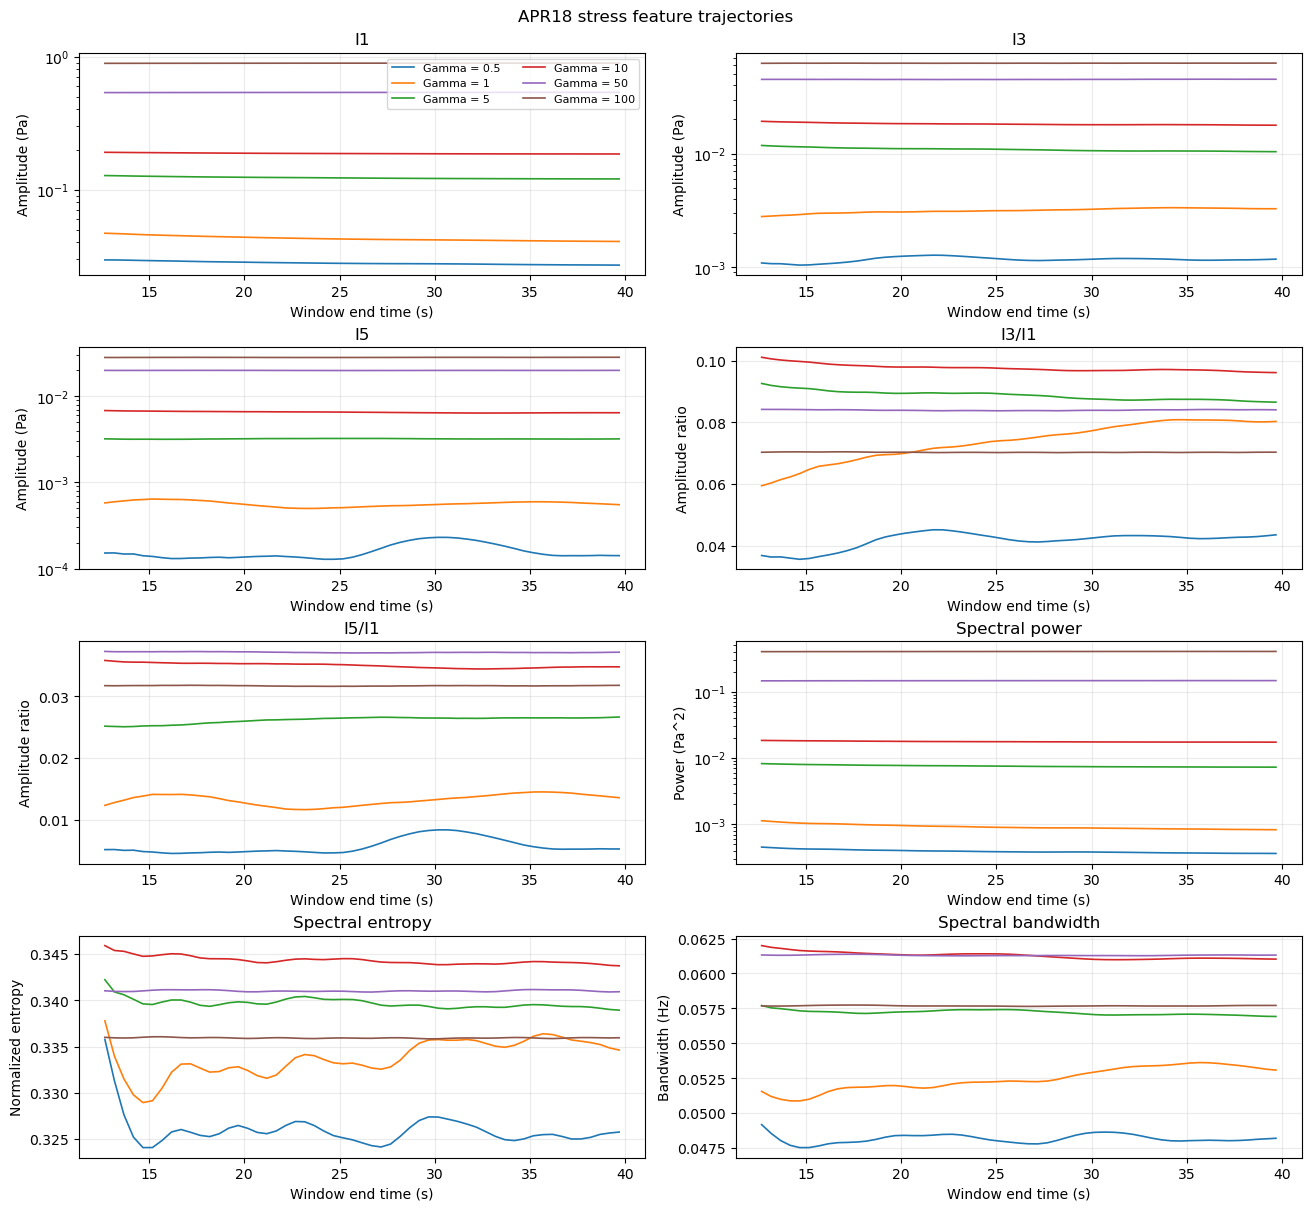

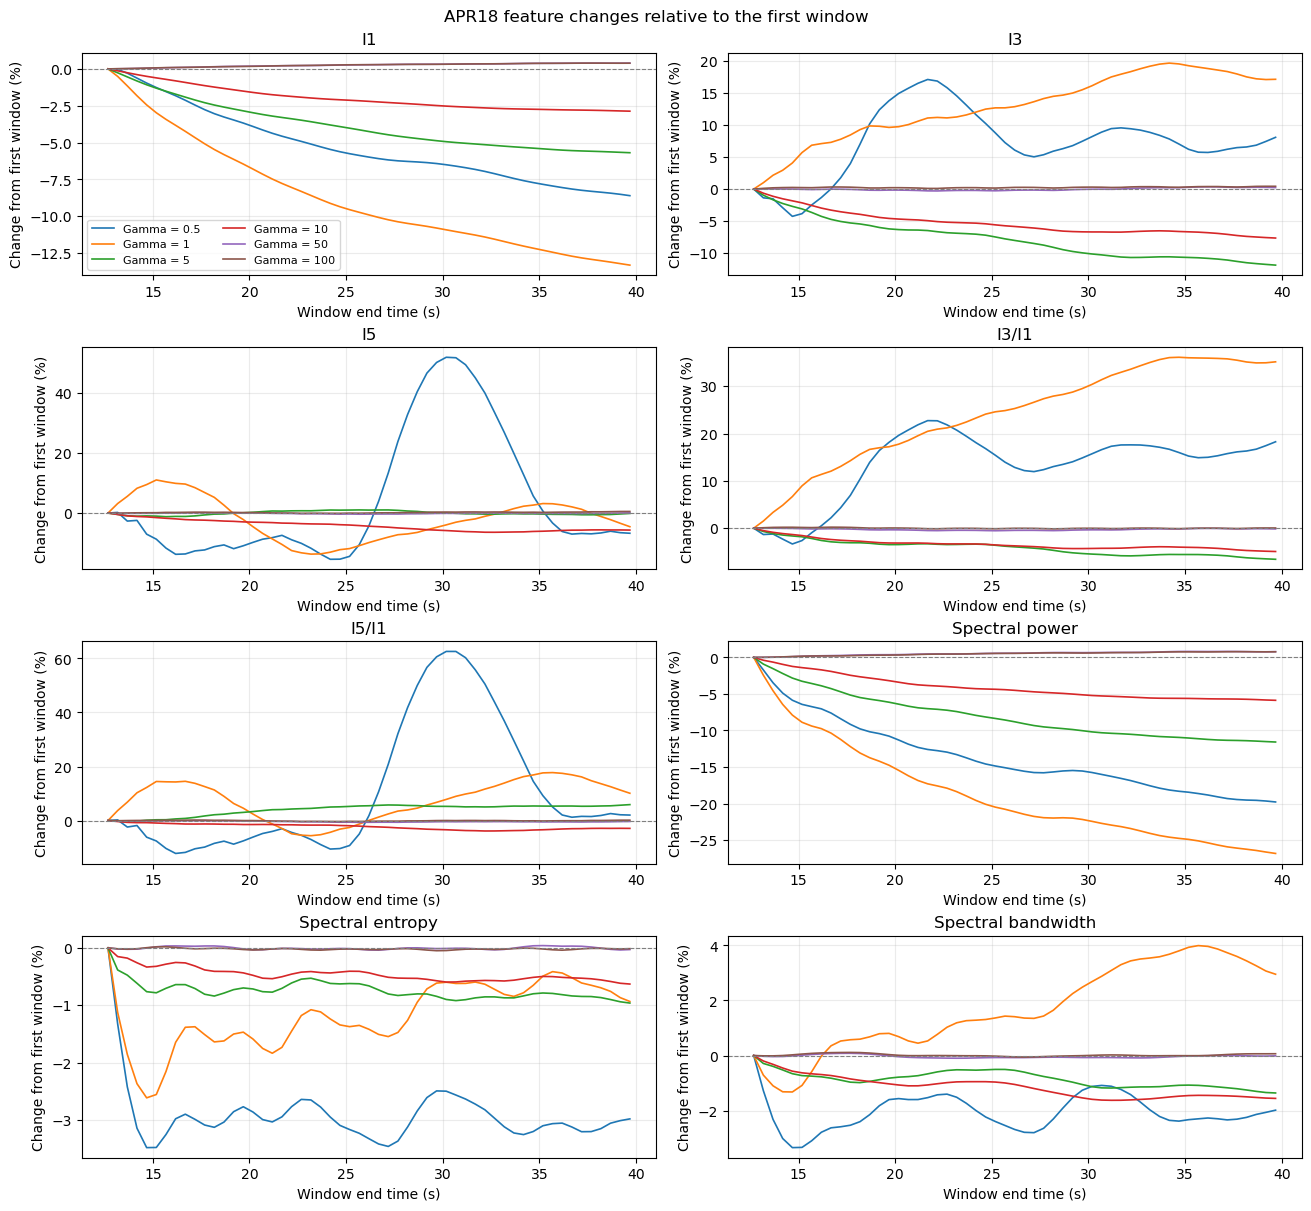

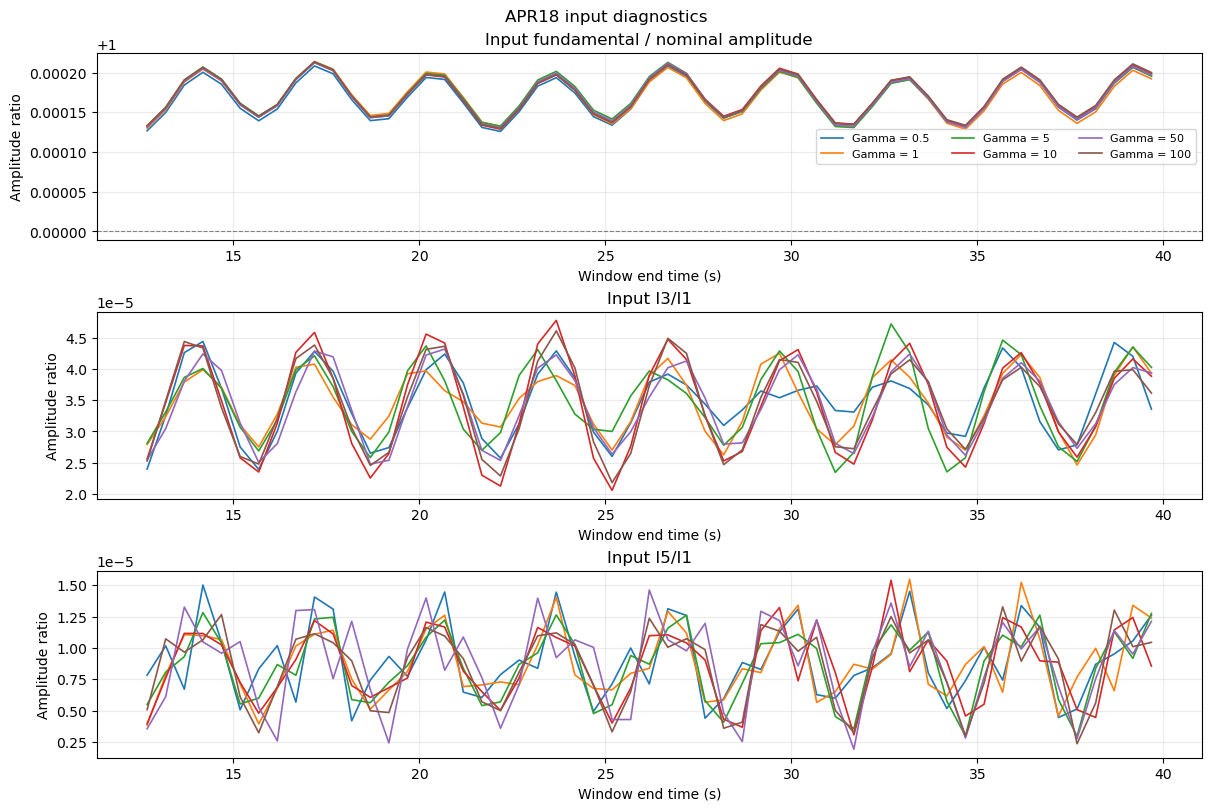

Descriptive feature ranges relative to each median (%):


feature,I1_Pa,I3_Pa,I5_Pa,I3_I1,I5_I1,spectral_power_Pa2,spectral_entropy,spectral_bandwidth_Hz
case,,,,,,,,
omega_1_gamma_0.5,9.15,19.98,72.27,22.52,73.87,23.36,3.59,3.42
omega_1_gamma_1,14.78,17.44,25.26,28.82,21.44,34.00,2.65,5.25
omega_1_gamma_5,5.94,12.92,2.27,6.84,5.97,12.70,0.97,1.37
omega_1_gamma_10,2.93,8.13,6.71,5.12,3.95,6.15,0.63,1.64
omega_1_gamma_50,0.39,0.64,0.45,0.54,0.66,0.81,0.08,0.18
omega_1_gamma_100,0.39,0.43,0.63,0.36,0.54,0.77,0.07,0.17


The first window is a plotting reference, not a verified baseline.
Range statistics are not significance tests.
Overlapping windows are not independent observations.
No alarm threshold or change time is selected from these plots.


In [8]:
# Block 7: Plot feature trajectories and input diagnostics

FEATURE_LABELS = {
    "I1_Pa": ("I1", "Amplitude (Pa)"),
    "I3_Pa": ("I3", "Amplitude (Pa)"),
    "I5_Pa": ("I5", "Amplitude (Pa)"),
    "I3_I1": ("I3/I1", "Amplitude ratio"),
    "I5_I1": ("I5/I1", "Amplitude ratio"),
    "spectral_power_Pa2": ("Spectral power", "Power (Pa^2)"),
    "spectral_entropy": ("Spectral entropy", "Normalized entropy"),
    "spectral_bandwidth_Hz": (
        "Spectral bandwidth",
        "Bandwidth (Hz)",
    ),
}

case_names = list(apr18_feature_tables)

CASE_COLORS = {
    case_name: plt.get_cmap("tab10")(index)
    for index, case_name in enumerate(case_names)
}


def plot_apr18_features(relative_to_first=False):
    figure, axes = plt.subplots(
        4,
        2,
        figsize=(13, 12),
        constrained_layout=True,
    )

    for axis, feature_name in zip(
        axes.flat,
        FEATURE_COLUMNS,
    ):
        title, unit_label = FEATURE_LABELS[feature_name]

        for case_name in case_names:
            table = apr18_feature_tables[case_name]
            record = apr18_prepared_records[case_name]

            values = table[feature_name].to_numpy(dtype=float)

            if relative_to_first:
                first_value = values[0]

                if (
                    not np.isfinite(first_value)
                    or abs(first_value) <= np.finfo(float).eps
                ):
                    raise ValueError(
                        f"Invalid plotting reference: "
                        f"{case_name}, {feature_name}"
                    )

                plotted_values = (
                    100.0 * (values / first_value - 1.0)
                )
            else:
                plotted_values = values

            axis.plot(
                table["window_end_s"],
                plotted_values,
                color=CASE_COLORS[case_name],
                linewidth=1.2,
                label=f"Gamma = {record['gamma_nominal']:g}",
            )

        axis.set_title(title)
        axis.set_xlabel("Window end time (s)")
        axis.grid(alpha=0.25)

        if relative_to_first:
            axis.axhline(
                0.0,
                color="gray",
                linestyle="--",
                linewidth=0.8,
            )
            axis.set_ylabel("Change from first window (%)")
        else:
            axis.set_ylabel(unit_label)

            if feature_name in [
                "I1_Pa",
                "I3_Pa",
                "I5_Pa",
                "spectral_power_Pa2",
            ]:
                axis.set_yscale("log")

    axes[0, 0].legend(fontsize=8, ncol=2)

    figure.suptitle(
        "APR18 feature changes relative to the first window"
        if relative_to_first
        else "APR18 stress feature trajectories"
    )

    return figure


apr18_absolute_feature_figure = plot_apr18_features(
    relative_to_first=False
)
plt.show()

apr18_relative_feature_figure = plot_apr18_features(
    relative_to_first=True
)
plt.show()


# Inspect input amplitude and input harmonic ratios.
input_plot_settings = [
    (
        "input_I1_over_nominal",
        "Input fundamental / nominal amplitude",
        "Amplitude ratio",
    ),
    (
        "input_I3_I1",
        "Input I3/I1",
        "Amplitude ratio",
    ),
    (
        "input_I5_I1",
        "Input I5/I1",
        "Amplitude ratio",
    ),
]

input_figure, input_axes = plt.subplots(
    3,
    1,
    figsize=(12, 8),
    constrained_layout=True,
)

for axis, (column_name, title, ylabel) in zip(
    input_axes,
    input_plot_settings,
):
    for case_name in case_names:
        table = apr18_input_quality_tables[case_name]
        record = apr18_prepared_records[case_name]

        axis.plot(
            table["window_end_s"],
            table[column_name],
            color=CASE_COLORS[case_name],
            linewidth=1.2,
            label=f"Gamma = {record['gamma_nominal']:g}",
        )

    axis.set_title(title)
    axis.set_xlabel("Window end time (s)")
    axis.set_ylabel(ylabel)
    axis.grid(alpha=0.25)

input_axes[0].axhline(
    1.0,
    color="gray",
    linestyle="--",
    linewidth=0.8,
)

input_axes[0].legend(fontsize=8, ncol=3)
input_figure.suptitle("APR18 input diagnostics")
plt.show()


# Summarize descriptive variation across the complete feature trajectories.
variation_rows = []

for case_name, table in apr18_feature_tables.items():
    for feature_name in FEATURE_COLUMNS:
        values = table[feature_name].to_numpy(dtype=float)
        median_value = float(np.median(values))

        variation_rows.append(
            {
                "case": case_name,
                "feature": feature_name,
                "median": median_value,
                "min": float(np.min(values)),
                "max": float(np.max(values)),
                "range_over_median_percent": (
                    100.0
                    * (np.max(values) - np.min(values))
                    / abs(median_value)
                    if abs(median_value) > np.finfo(float).eps
                    else np.nan
                ),
            }
        )

apr18_feature_variation_summary = pd.DataFrame(
    variation_rows
)

print("Descriptive feature ranges relative to each median (%):")
display(
    apr18_feature_variation_summary.pivot(
        index="case",
        columns="feature",
        values="range_over_median_percent",
    )
    .reindex(index=case_names, columns=FEATURE_COLUMNS)
    .round(2)
)

print("The first window is a plotting reference, not a verified baseline.")
print("Range statistics are not significance tests.")
print("Overlapping windows are not independent observations.")
print("No alarm threshold or change time is selected from these plots.")

In [9]:
# Block 8: Assess reference coverage and input variation

REFERENCE_END_CANDIDATES_S = [20.0, 24.0, 26.0]


def count_nonoverlapping_windows(window_table):
    selected_count = 0
    previous_end_s = -np.inf

    ordered_table = window_table.sort_values(
        "window_start_s"
    )

    for row in ordered_table.itertuples(index=False):
        if row.window_start_s >= previous_end_s - 1e-9:
            selected_count += 1
            previous_end_s = row.window_end_s

    return selected_count


reference_coverage_rows = []
reference_statistic_rows = []

for case_name, feature_table in apr18_feature_tables.items():
    reference_start_s = float(
        apr18_prepared_records[case_name]["data"][
            "time_s"
        ].iloc[0]
    )

    for reference_end_s in REFERENCE_END_CANDIDATES_S:
        reference_mask = (
            (
                feature_table["window_start_s"]
                >= reference_start_s - 1e-9
            )
            & (
                feature_table["window_end_s"]
                <= reference_end_s + 1e-9
            )
        )

        # Use monitoring windows wholly after the reference interval.
        monitoring_mask = (
            feature_table["window_start_s"]
            >= reference_end_s - 1e-9
        )

        reference_table = feature_table.loc[
            reference_mask
        ]
        monitoring_table = feature_table.loc[
            monitoring_mask
        ]

        reference_coverage_rows.append(
            {
                "case": case_name,
                "reference_end_s": reference_end_s,
                "n_reference_outputs": len(reference_table),
                "n_nonoverlapping_reference_windows": (
                    count_nonoverlapping_windows(
                        reference_table
                    )
                ),
                "n_monitoring_outputs": len(monitoring_table),
                "first_monitoring_window_end_s": (
                    monitoring_table["window_end_s"].iloc[0]
                    if len(monitoring_table) else np.nan
                ),
                "monitoring_output_span_s": (
                    monitoring_table["window_end_s"].iloc[-1]
                    - monitoring_table["window_end_s"].iloc[0]
                    if len(monitoring_table) else np.nan
                ),
            }
        )

        for feature_name in FEATURE_COLUMNS:
            values = reference_table[
                feature_name
            ].to_numpy(dtype=float)

            if len(values) < 2:
                continue

            median_value = float(np.median(values))
            mad = float(
                np.median(np.abs(values - median_value))
            )
            robust_scale = 1.4826 * mad

            split_index = len(values) // 2
            first_half_median = float(
                np.median(values[:split_index])
            )
            second_half_median = float(
                np.median(values[split_index:])
            )

            reference_statistic_rows.append(
                {
                    "case": case_name,
                    "reference_end_s": reference_end_s,
                    "feature": feature_name,
                    "reference_median": median_value,
                    "reference_robust_scale": robust_scale,
                    "half_median_difference_percent": (
                        100.0
                        * (
                            second_half_median
                            - first_half_median
                        )
                        / abs(median_value)
                        if abs(median_value)
                        > np.finfo(float).eps
                        else np.nan
                    ),
                }
            )

apr18_reference_coverage = pd.DataFrame(
    reference_coverage_rows
)

apr18_reference_statistics = pd.DataFrame(
    reference_statistic_rows
)

print("Reference and monitoring coverage:")
print("Coverage is identical across the six records.")
display(
    apr18_reference_coverage.loc[
        apr18_reference_coverage["case"] == case_names[0]
    ].round(3)
)

print("\nReference half-to-half median differences (%):")
print("Example reference endpoint: 20 s")
display(
    apr18_reference_statistics.loc[
        np.isclose(
            apr18_reference_statistics["reference_end_s"],
            20.0,
        )
    ]
    .pivot(
        index="case",
        columns="feature",
        values="half_median_difference_percent",
    )
    .reindex(index=case_names, columns=FEATURE_COLUMNS)
    .round(2)
)


input_summary_rows = []

for case_name, table in apr18_input_quality_tables.items():
    normalized_i1 = table[
        "input_I1_over_nominal"
    ].to_numpy()

    input_summary_rows.append(
        {
            "case": case_name,
            "median_input_I1_over_nominal": (
                float(np.median(normalized_i1))
            ),
            "input_I1_range_percent_of_nominal": (
                100.0 * float(np.ptp(normalized_i1))
            ),
            "max_input_I3_I1": (
                float(table["input_I3_I1"].max())
            ),
            "max_input_I5_I1": (
                float(table["input_I5_I1"].max())
            ),
        }
    )

apr18_input_variation_summary = pd.DataFrame(
    input_summary_rows
)

print("\nInput variation summary:")
display(apr18_input_variation_summary.round(6))

print("Reference intervals are exploratory candidates.")
print("Nonoverlapping windows are not necessarily independent.")
print("Half-to-half differences are descriptive, not stationarity tests.")
print("No reference interval or alarm time has been selected.")

Reference and monitoring coverage:
Coverage is identical across the six records.


,case,reference_end_s,n_reference_outputs,n_nonoverlapping_reference_windows,n_monitoring_outputs,first_monitoring_window_end_s,monitoring_output_span_s
0,omega_1_gamma_0.5,20.0,15,1,15,32.68,7.0
1,omega_1_gamma_0.5,24.0,23,1,7,36.68,3.0
2,omega_1_gamma_0.5,26.0,27,2,3,38.68,1.0



Reference half-to-half median differences (%):
Example reference endpoint: 20 s


feature,I1_Pa,I3_Pa,I5_Pa,I3_I1,I5_I1,spectral_power_Pa2,spectral_entropy,spectral_bandwidth_Hz
case,,,,,,,,
omega_1_gamma_0.5,-2.32,7.98,-10.58,9.94,-7.44,-4.93,0.16,0.56
omega_1_gamma_1,-3.59,5.54,-2.08,9.05,1.50,-6.88,0.66,1.67
omega_1_gamma_5,-1.58,-3.26,0.46,-1.67,1.91,-3.25,-0.10,-0.36
omega_1_gamma_10,-0.80,-2.41,-1.31,-1.60,-0.53,-1.62,-0.14,-0.43
omega_1_gamma_50,0.11,-0.08,0.12,-0.19,0.02,0.26,0.03,0.08
omega_1_gamma_100,0.09,0.04,0.17,-0.02,0.07,0.18,-0.01,0.10



Input variation summary:


,case,median_input_I1_over_nominal,input_I1_range_percent_of_nominal,max_input_I3_I1,max_input_I5_I1
0,omega_1_gamma_0.5,1.000166,0.008248,0.000044,0.000015
1,omega_1_gamma_1,1.000169,0.008521,0.000044,0.000015
2,omega_1_gamma_5,1.000168,0.008269,0.000047,0.000013
3,omega_1_gamma_10,1.000170,0.008406,0.000048,0.000015
4,omega_1_gamma_50,1.000168,0.008179,0.000043,0.000015
5,omega_1_gamma_100,1.000171,0.008384,0.000046,0.000013


Reference intervals are exploratory candidates.
Nonoverlapping windows are not necessarily independent.
Half-to-half differences are descriptive, not stationarity tests.
No reference interval or alarm time has been selected.


In [10]:
# Block 9: Detect sustained two-sided reference departures

REFERENCE_END_S = 20.0
Z_THRESHOLD = 5.0
PERSISTENCE_DURATION_S = 1.0
ALARM_RULE_NAME = "two_sided_exploration"


def find_apr18_persistent_events(
    times_s,
    scores,
    monitoring_mask,
    threshold,
    persistence_s,
    expected_hop_s=0.5,
):
    times = np.asarray(times_s, dtype=float)
    signed_scores = np.asarray(scores, dtype=float)
    monitoring = np.asarray(monitoring_mask, dtype=bool)

    if (
        times.ndim != 1
        or times.shape != signed_scores.shape
        or times.shape != monitoring.shape
    ):
        raise ValueError("Detection arrays must be matching 1D arrays.")

    if len(times) == 0:
        raise ValueError("Detection timestamps must be non-empty.")

    if not np.all(np.isfinite(times)) or np.any(np.diff(times) <= 0):
        raise ValueError("Detection timestamps must be finite and increasing.")

    if threshold <= 0 or persistence_s < 0 or expected_hop_s <= 0:
        raise ValueError("Invalid alarm parameters.")

    events = []
    run_start_index = None
    run_direction = 0
    run_confirmed = False

    for index in range(len(times)):
        eligible = (
            monitoring[index]
            and np.isfinite(signed_scores[index])
            and abs(signed_scores[index]) >= threshold
        )

        if not eligible:
            run_start_index = None
            run_direction = 0
            run_confirmed = False
            continue

        direction = int(np.sign(signed_scores[index]))

        continuous_step = (
            index > 0
            and np.isclose(
                times[index] - times[index - 1],
                expected_hop_s,
                rtol=0,
                atol=1e-8,
            )
        )

        if (
            run_start_index is None
            or direction != run_direction
            or not continuous_step
        ):
            run_start_index = index
            run_direction = direction
            run_confirmed = False

        elapsed_s = times[index] - times[run_start_index]

        if (
            not run_confirmed
            and elapsed_s + 1e-9 >= persistence_s
        ):
            events.append({
                "qualified_run_start_s": float(times[run_start_index]),
                "alarm_time_s": float(times[index]),
                "confirmation_index": int(index),
            })
            run_confirmed = True

    return events


apr18_scored_tables = {}
alarm_summary_rows = []
alarm_event_rows = []

for case_name, table in apr18_feature_tables.items():
    scored_table = table.copy()
    times_s = scored_table["window_end_s"].to_numpy(dtype=float)

    reference_mask = times_s <= REFERENCE_END_S + 1e-9
    monitoring_mask = times_s > REFERENCE_END_S + 1e-9

    scored_table["reference_window"] = reference_mask
    scored_table["monitoring_window"] = monitoring_mask

    reference_table = scored_table.loc[reference_mask]
    monitoring_table = scored_table.loc[monitoring_mask]

    if len(reference_table) < 2:
        raise ValueError(f"Too few reference outputs: {case_name}")

    if monitoring_table.empty:
        raise ValueError(f"No monitoring outputs: {case_name}")

    first_monitoring_end_s = float(
        monitoring_table["window_end_s"].iloc[0]
    )

    actual_hop_s = apr18_stft_settings[case_name]["hop_duration_s"]

    for feature_name in FEATURE_COLUMNS:
        reference_values = reference_table[
            feature_name
        ].to_numpy(dtype=float)

        if not np.all(np.isfinite(reference_values)):
            raise ValueError(
                f"Invalid reference values: {case_name}, {feature_name}"
            )

        reference_median = float(np.median(reference_values))
        reference_mad = float(
            np.median(np.abs(reference_values - reference_median))
        )
        reference_scale = 1.4826 * reference_mad

        scale_is_defined = (
            np.isfinite(reference_scale)
            and reference_scale > 0
        )

        values = scored_table[feature_name].to_numpy(dtype=float)

        z_values = (
            (values - reference_median) / reference_scale
            if scale_is_defined
            else np.full(len(values), np.nan)
        )

        scored_table[f"{feature_name}_z"] = z_values

        crossing_indices = np.flatnonzero(
            monitoring_mask
            & np.isfinite(z_values)
            & (np.abs(z_values) >= Z_THRESHOLD)
        )

        events = find_apr18_persistent_events(
            times_s=times_s,
            scores=z_values,
            monitoring_mask=monitoring_mask,
            threshold=Z_THRESHOLD,
            persistence_s=PERSISTENCE_DURATION_S,
            expected_hop_s=actual_hop_s,
        )

        for event in events:
            alarm_z = float(z_values[event["confirmation_index"]])

            alarm_event_rows.append({
                "case": case_name,
                "feature": feature_name,
                "rule": ALARM_RULE_NAME,
                "qualified_run_start_s": event["qualified_run_start_s"],
                "alarm_time_s": event["alarm_time_s"],
                "alarm_signed_z": alarm_z,
                "departure_direction": (
                    "increase" if alarm_z > 0 else "decrease"
                ),
            })

        first_event = events[0] if events else None

        status = (
            "undefined_reference_scale"
            if not scale_is_defined
            else "exploratory_alarm"
            if first_event is not None
            else "no_alarm_in_monitoring_interval"
        )

        alarm_summary_rows.append({
            "case": case_name,
            "feature": feature_name,
            "rule": ALARM_RULE_NAME,
            "reference_end_s": REFERENCE_END_S,
            "n_reference_outputs": len(reference_table),
            "n_nonoverlapping_reference_windows": (
                count_nonoverlapping_windows(reference_table)
            ),
            "n_monitoring_outputs": len(monitoring_table),
            "first_monitoring_end_s": first_monitoring_end_s,
            "reference_median": reference_median,
            "reference_scale": reference_scale,
            "first_crossing_s": (
                float(times_s[crossing_indices[0]])
                if len(crossing_indices) else np.nan
            ),
            "first_qualified_run_start_s": (
                first_event["qualified_run_start_s"]
                if first_event else np.nan
            ),
            "first_alarm_s": (
                first_event["alarm_time_s"]
                if first_event else np.nan
            ),
            "n_confirmed_events": len(events),
            "status": status,
            "z_threshold": Z_THRESHOLD,
            "persistence_s": PERSISTENCE_DURATION_S,
            "baseline_reliability": "not_established",
        })

    apr18_scored_tables[case_name] = scored_table

apr18_alarm_summary = pd.DataFrame(alarm_summary_rows)

apr18_alarm_events = pd.DataFrame(
    alarm_event_rows,
    columns=[
        "case",
        "feature",
        "rule",
        "qualified_run_start_s",
        "alarm_time_s",
        "alarm_signed_z",
        "departure_direction",
    ],
)

apr18_alarm_time_table = (
    apr18_alarm_summary.pivot(
        index="case",
        columns="feature",
        values="first_alarm_s",
    )
    .reindex(index=case_names, columns=FEATURE_COLUMNS)
)

print("First confirmed two-sided alarm times (s):")
display(apr18_alarm_time_table.round(2))

print("\nCrossing, run-start and confirmation details:")
display(
    apr18_alarm_summary[
        [
            "case",
            "feature",
            "first_monitoring_end_s",
            "first_crossing_s",
            "first_qualified_run_start_s",
            "first_alarm_s",
            "status",
        ]
    ].round(3)
)

print("\nConfirmed events and departure directions:")
display(apr18_alarm_events.round(3))

print(
    "\nMonitoring includes windows ending after the reference endpoint."
)
print(
    "Persistence requires consecutive exceedances on the same side."
)
print(
    "Alarm times indicate confirmed reference departures, "
    "not verified physical change onsets."
)
print(
    "Reference stability and baseline reliability are not established."
)
print(
    "NaN indicates no confirmed alarm or an undefined reference scale."
)

First confirmed two-sided alarm times (s):


feature,I1_Pa,I3_Pa,I5_Pa,I3_I1,I5_I1,spectral_power_Pa2,spectral_entropy,spectral_bandwidth_Hz
case,,,,,,,,
omega_1_gamma_0.5,NaN,NaN,28.18,NaN,28.18,NaN,NaN,NaN
omega_1_gamma_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
omega_1_gamma_5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
omega_1_gamma_10,NaN,NaN,NaN,NaN,29.18,NaN,NaN,NaN
omega_1_gamma_50,NaN,36.18,NaN,NaN,22.18,NaN,NaN,NaN
omega_1_gamma_100,NaN,NaN,NaN,NaN,NaN,38.18,NaN,NaN



Crossing, run-start and confirmation details:


,case,feature,first_monitoring_end_s,first_crossing_s,first_qualified_run_start_s,first_alarm_s,status
0,omega_1_gamma_0.5,I1_Pa,20.18,NaN,NaN,NaN,no_alarm_in_monitoring_interval
1,omega_1_gamma_0.5,I3_Pa,20.18,NaN,NaN,NaN,no_alarm_in_monitoring_interval
2,omega_1_gamma_0.5,I5_Pa,20.18,27.18,27.18,28.18,exploratory_alarm
3,omega_1_gamma_0.5,I3_I1,20.18,NaN,NaN,NaN,no_alarm_in_monitoring_interval
4,omega_1_gamma_0.5,I5_I1,20.18,27.18,27.18,28.18,exploratory_alarm
5,omega_1_gamma_0.5,spectral_power_Pa2,20.18,NaN,NaN,NaN,no_alarm_in_monitoring_interval
6,omega_1_gamma_0.5,spectral_entropy,20.18,NaN,NaN,NaN,no_alarm_in_monitoring_interval
7,omega_1_gamma_0.5,spectral_bandwidth_Hz,20.18,NaN,NaN,NaN,no_alarm_in_monitoring_interval
8,omega_1_gamma_1,I1_Pa,20.18,NaN,NaN,NaN,no_alarm_in_monitoring_interval
9,omega_1_gamma_1,I3_Pa,20.18,NaN,NaN,NaN,no_alarm_in_monitoring_interval



Confirmed events and departure directions:


,case,feature,rule,qualified_run_start_s,alarm_time_s,alarm_signed_z,departure_direction
0,omega_1_gamma_0.5,I5_Pa,two_sided_exploration,27.18,28.18,13.437,increase
1,omega_1_gamma_0.5,I5_I1,two_sided_exploration,27.18,28.18,12.368,increase
2,omega_1_gamma_10,I5_I1,two_sided_exploration,28.18,29.18,-6.070,decrease
3,omega_1_gamma_50,I3_Pa,two_sided_exploration,35.18,36.18,6.539,increase
4,omega_1_gamma_50,I3_Pa,two_sided_exploration,38.18,39.18,5.312,increase
5,omega_1_gamma_50,I5_I1,two_sided_exploration,21.18,22.18,-8.495,decrease
6,omega_1_gamma_100,spectral_power_Pa2,two_sided_exploration,37.18,38.18,5.060,increase



Monitoring includes windows ending after the reference endpoint.
Persistence requires consecutive exceedances on the same side.
Alarm times indicate confirmed reference departures, not verified physical change onsets.
Reference stability and baseline reliability are not established.
NaN indicates no confirmed alarm or an undefined reference scale.


Alarm effect-size audit:


,case,feature,alarm_time_s,alarm_signed_z,reference_median,reference_scale,alarm_feature_value,signed_difference,relative_difference_percent
0,omega_1_gamma_0.5,I5_Pa,28.18,13.437385,0.000135,0.000005,0.000201,0.000066,49.204072
1,omega_1_gamma_0.5,I5_I1,28.18,12.368164,0.004733,0.000205,0.007266,0.002533,53.511927
2,omega_1_gamma_10,I5_I1,29.18,-6.070017,0.035432,0.000121,0.034695,-0.000737,-2.080464
3,omega_1_gamma_50,I3_Pa,36.18,6.538607,0.045119,0.000026,0.045292,0.000173,0.383839
4,omega_1_gamma_50,I3_Pa,39.18,5.312326,0.045119,0.000026,0.045259,0.000141,0.311852
5,omega_1_gamma_50,I5_I1,22.18,-8.495349,0.037261,0.000011,0.037166,-0.000095,-0.255697
6,omega_1_gamma_100,spectral_power_Pa2,38.18,5.059525,0.399044,0.000457,0.401356,0.002312,0.579382



Timing and monitoring-boundary audit:


,case,feature,qualified_run_start_s,alarm_time_s,alarm_window_start_s,alarm_window_end_s,starts_at_monitoring_boundary,alarm_window_overlaps_reference_interval
0,omega_1_gamma_0.5,I5_Pa,27.18,28.18,15.62,28.18,False,True
1,omega_1_gamma_0.5,I5_I1,27.18,28.18,15.62,28.18,False,True
2,omega_1_gamma_10,I5_I1,28.18,29.18,16.62,29.18,False,True
3,omega_1_gamma_50,I3_Pa,35.18,36.18,23.62,36.18,False,False
4,omega_1_gamma_50,I3_Pa,38.18,39.18,26.62,39.18,False,False
5,omega_1_gamma_50,I5_I1,21.18,22.18,9.62,22.18,False,True
6,omega_1_gamma_100,spectral_power_Pa2,37.18,38.18,25.62,38.18,False,False


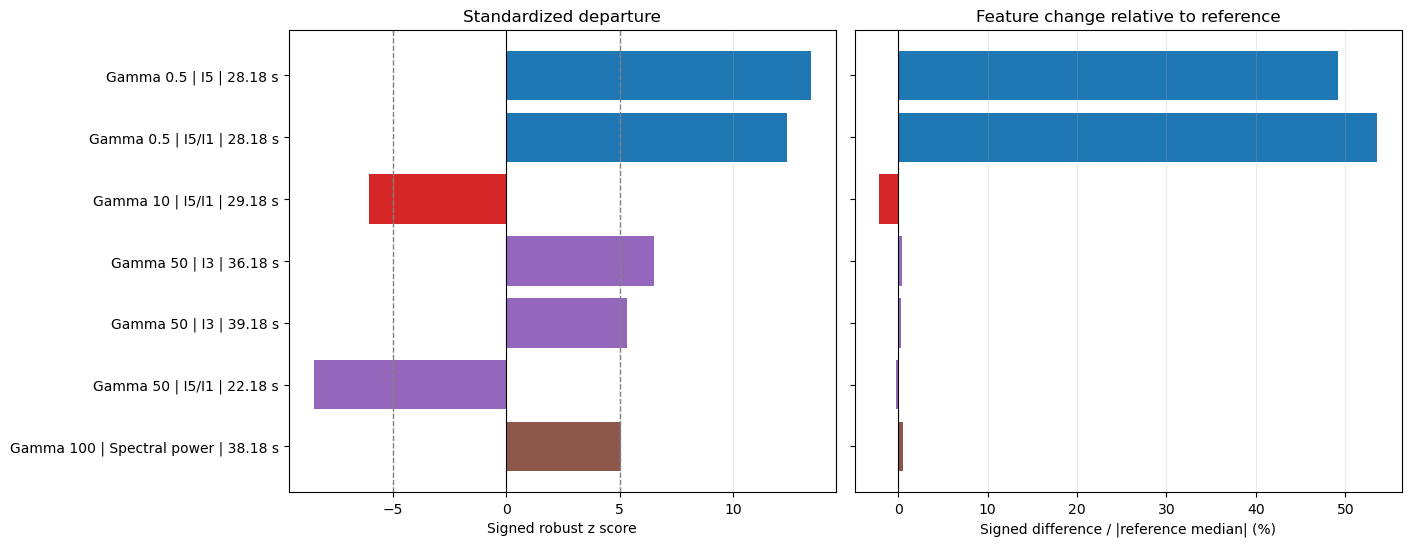


A large z score can arise from a small reference scale.
Relative differences describe feature changes; they do not establish clinical or material significance.
A run starting at the monitoring boundary does not locate the onset of the departure.
A window overlapping the reference interval is permitted by the current monitoring protocol.
Multiple feature alarms may be correlated and are not independent confirmations.


In [11]:
# Block 10: Audit alarm effect sizes and monitoring boundaries

audit_rows = []

reference_lookup = apr18_alarm_summary.set_index(
    ["case", "feature"]
)

for event in apr18_alarm_events.itertuples(index=False):
    case_name = event.case
    feature_name = event.feature

    scored_table = apr18_scored_tables[case_name]
    reference_row = reference_lookup.loc[
        (case_name, feature_name)
    ]

    confirmation_mask = np.isclose(
        scored_table["window_end_s"].to_numpy(dtype=float),
        event.alarm_time_s,
        rtol=0,
        atol=1e-8,
    )

    if confirmation_mask.sum() != 1:
        raise ValueError(
            "Each alarm must match exactly one feature output."
        )

    alarm_row = scored_table.loc[confirmation_mask].iloc[0]

    reference_median = float(reference_row["reference_median"])
    reference_scale = float(reference_row["reference_scale"])
    alarm_value = float(alarm_row[feature_name])

    signed_difference = alarm_value - reference_median

    relative_difference_percent = (
        100.0 * signed_difference / abs(reference_median)
        if abs(reference_median) > np.finfo(float).eps
        else np.nan
    )

    first_monitoring_end_s = float(
        reference_row["first_monitoring_end_s"]
    )

    run_starts_at_boundary = bool(
        np.isclose(
            event.qualified_run_start_s,
            first_monitoring_end_s,
            rtol=0,
            atol=1e-8,
        )
    )

    reconstructed_z = signed_difference / reference_scale

    if not np.isclose(
        reconstructed_z,
        event.alarm_signed_z,
        rtol=1e-9,
        atol=1e-9,
    ):
        raise AssertionError("Alarm score reconstruction failed.")

    audit_rows.append({
        "case": case_name,
        "gamma": apr18_prepared_records[case_name]["gamma_nominal"],
        "feature": feature_name,
        "qualified_run_start_s": event.qualified_run_start_s,
        "alarm_time_s": event.alarm_time_s,
        "departure_direction": event.departure_direction,
        "alarm_signed_z": event.alarm_signed_z,
        "reference_median": reference_median,
        "reference_scale": reference_scale,
        "alarm_feature_value": alarm_value,
        "signed_difference": signed_difference,
        "relative_difference_percent": relative_difference_percent,
        "alarm_window_start_s": float(alarm_row["window_start_s"]),
        "alarm_window_end_s": float(alarm_row["window_end_s"]),
        "first_monitoring_end_s": first_monitoring_end_s,
        "starts_at_monitoring_boundary": run_starts_at_boundary,
        "alarm_window_overlaps_reference_interval": bool(
            alarm_row["window_start_s"] < REFERENCE_END_S
        ),
    })

audit_columns = [
    "case", "gamma", "feature",
    "qualified_run_start_s", "alarm_time_s",
    "departure_direction", "alarm_signed_z",
    "reference_median", "reference_scale",
    "alarm_feature_value", "signed_difference",
    "relative_difference_percent",
    "alarm_window_start_s", "alarm_window_end_s",
    "first_monitoring_end_s",
    "starts_at_monitoring_boundary",
    "alarm_window_overlaps_reference_interval",
]

apr18_alarm_audit = pd.DataFrame(
    audit_rows,
    columns=audit_columns,
)

print("Alarm effect-size audit:")
display(
    apr18_alarm_audit[
        [
            "case",
            "feature",
            "alarm_time_s",
            "alarm_signed_z",
            "reference_median",
            "reference_scale",
            "alarm_feature_value",
            "signed_difference",
            "relative_difference_percent",
        ]
    ]
)

print("\nTiming and monitoring-boundary audit:")
display(
    apr18_alarm_audit[
        [
            "case",
            "feature",
            "qualified_run_start_s",
            "alarm_time_s",
            "alarm_window_start_s",
            "alarm_window_end_s",
            "starts_at_monitoring_boundary",
            "alarm_window_overlaps_reference_interval",
        ]
    ].round(3)
)

alarm_audit_figure = None

if not apr18_alarm_audit.empty:
    plot_table = apr18_alarm_audit.reset_index(drop=True)
    positions = np.arange(len(plot_table))

    labels = [
        f"Gamma {row.gamma:g} | "
        f"{FEATURE_LABELS[row.feature][0]} | "
        f"{row.alarm_time_s:.2f} s"
        for row in plot_table.itertuples(index=False)
    ]

    colors = [
        CASE_COLORS[case]
        for case in plot_table["case"]
    ]

    alarm_audit_figure, axes = plt.subplots(
        1, 2,
        figsize=(14, max(4.5, 0.55 * len(plot_table) + 1.5)),
        sharey=True,
        constrained_layout=True,
    )

    axes[0].barh(
        positions,
        plot_table["alarm_signed_z"],
        color=colors,
    )

    for threshold in [-Z_THRESHOLD, Z_THRESHOLD]:
        axes[0].axvline(
            threshold,
            color="gray",
            linestyle="--",
            linewidth=1,
        )

    axes[0].set_title("Standardized departure")
    axes[0].set_xlabel("Signed robust z score")
    axes[0].set_yticks(positions)
    axes[0].set_yticklabels(labels)
    axes[0].invert_yaxis()

    axes[1].barh(
        positions,
        plot_table["relative_difference_percent"],
        color=colors,
    )
    axes[1].set_title("Feature change relative to reference")
    axes[1].set_xlabel("Signed difference / |reference median| (%)")

    for ax in axes:
        ax.axvline(0, color="black", linewidth=0.8)
        ax.grid(axis="x", alpha=0.25)

    plt.show()

print(
    "\nA large z score can arise from a small reference scale."
)
print(
    "Relative differences describe feature changes; "
    "they do not establish clinical or material significance."
)
print(
    "A run starting at the monitoring boundary "
    "does not locate the onset of the departure."
)
print(
    "A window overlapping the reference interval "
    "is permitted by the current monitoring protocol."
)
print(
    "Multiple feature alarms may be correlated "
    "and are not independent confirmations."
)

In [12]:
# Block 11: Reference sensitivity with a fixed monitoring start

SENSITIVITY_REFERENCE_ENDS_S = [16.0, 18.0, 20.0]
MONITORING_START_S = 20.0

sensitivity_rows = []

for case_name, feature_table in apr18_feature_tables.items():
    times_s = feature_table["window_end_s"].to_numpy(dtype=float)

    monitoring_mask = times_s > MONITORING_START_S + 1e-9
    monitoring_times = times_s[monitoring_mask]

    first_monitoring_end_s = (
        float(monitoring_times[0])
        if len(monitoring_times)
        else np.nan
    )

    expected_hop_s = float(
        apr18_stft_settings[case_name]["hop_duration_s"]
    )

    for reference_end_s in SENSITIVITY_REFERENCE_ENDS_S:
        reference_mask = times_s <= reference_end_s + 1e-9
        reference_windows = feature_table.loc[reference_mask]

        for feature in FEATURE_COLUMNS:
            reference_values = feature_table.loc[
                reference_mask, feature
            ].to_numpy(dtype=float)

            reference_values = reference_values[
                np.isfinite(reference_values)
            ]

            reference_median = (
                float(np.median(reference_values))
                if len(reference_values)
                else np.nan
            )

            reference_scale = (
                float(
                    1.4826
                    * np.median(
                        np.abs(reference_values - reference_median)
                    )
                )
                if len(reference_values)
                else np.nan
            )

            events = []
            signed_z = np.full(len(times_s), np.nan)

            if len(reference_values) < 2:
                status = "insufficient_reference_values"

            elif (
                not np.isfinite(reference_scale)
                or reference_scale <= 0
            ):
                status = "undefined_reference_scale"

            elif not len(monitoring_times):
                status = "no_monitoring_windows"

            else:
                values = feature_table[feature].to_numpy(dtype=float)
                signed_z = (
                    values - reference_median
                ) / reference_scale

                events = find_apr18_persistent_events(
                    times_s,
                    signed_z,
                    monitoring_mask,
                    Z_THRESHOLD,
                    PERSISTENCE_DURATION_S,
                    expected_hop_s,
                )

                status = (
                    "exploratory_alarm"
                    if events
                    else "no_alarm_in_monitoring_interval"
                )

            first_event = events[0] if events else None

            first_alarm_s = (
                float(first_event["alarm_time_s"])
                if first_event
                else np.nan
            )

            run_start_s = (
                float(first_event["qualified_run_start_s"])
                if first_event
                else np.nan
            )

            if first_event:
                confirmation_index = int(
                    first_event["confirmation_index"]
                )
                alarm_signed_z = float(
                    signed_z[confirmation_index]
                )
                departure_direction = (
                    "increase"
                    if alarm_signed_z > 0
                    else "decrease"
                )
            else:
                alarm_signed_z = np.nan
                departure_direction = None

            sensitivity_rows.append({
                "case": case_name,
                "feature": feature,
                "reference_end_s": reference_end_s,
                "monitoring_start_s": MONITORING_START_S,
                "rule": ALARM_RULE_NAME,
                "reference_median": reference_median,
                "reference_scale": reference_scale,
                "n_reference_outputs": int(reference_mask.sum()),
                "n_finite_reference_values": len(reference_values),
                "n_nonoverlapping_reference_windows": (
                    count_nonoverlapping_windows(reference_windows)
                ),
                "n_monitoring_outputs": int(monitoring_mask.sum()),
                "first_monitoring_window_end_s": (
                    first_monitoring_end_s
                ),
                "first_qualified_run_start_s": run_start_s,
                "first_alarm_s": first_alarm_s,
                "alarm_signed_z": alarm_signed_z,
                "departure_direction": departure_direction,
                "n_confirmed_events": len(events),
                "run_starts_at_monitoring_boundary": bool(
                    first_event
                    and np.isclose(
                        run_start_s,
                        first_monitoring_end_s,
                        atol=1e-8,
                        rtol=0,
                    )
                ),
                "status": status,
            })

apr18_reference_sensitivity = pd.DataFrame(sensitivity_rows)

alarm_comparison = apr18_reference_sensitivity.pivot(
    index=["case", "feature"],
    columns="reference_end_s",
    values="first_alarm_s",
).reindex(columns=SENSITIVITY_REFERENCE_ENDS_S)

status_comparison = apr18_reference_sensitivity.pivot(
    index=["case", "feature"],
    columns="reference_end_s",
    values="status",
).reindex(columns=SENSITIVITY_REFERENCE_ENDS_S)

direction_comparison = apr18_reference_sensitivity.pivot(
    index=["case", "feature"],
    columns="reference_end_s",
    values="departure_direction",
).reindex(columns=SENSITIVITY_REFERENCE_ENDS_S)

# Verify that the 20 s reference reproduces Block 9.
main_alarm_times = apr18_alarm_summary.set_index(
    ["case", "feature"]
)["first_alarm_s"]

sensitivity_alarm_times = (
    apr18_reference_sensitivity.loc[
        np.isclose(
            apr18_reference_sensitivity["reference_end_s"],
            REFERENCE_END_S,
        )
    ]
    .set_index(["case", "feature"])["first_alarm_s"]
    .reindex(main_alarm_times.index)
)

np.testing.assert_allclose(
    sensitivity_alarm_times.to_numpy(dtype=float),
    main_alarm_times.to_numpy(dtype=float),
    atol=1e-8,
    rtol=0,
    equal_nan=True,
)

# Describe consistency across the tested reference intervals.
stability_rows = []

for (case_name, feature), group in (
    apr18_reference_sensitivity.groupby(
        ["case", "feature"], sort=False
    )
):
    alarm_rows = group.loc[
        group["status"] == "exploratory_alarm"
    ]

    all_references_alarm = len(alarm_rows) == len(
        SENSITIVITY_REFERENCE_ENDS_S
    )

    same_direction = bool(
        all_references_alarm
        and alarm_rows["departure_direction"].nunique() == 1
    )

    stability_rows.append({
        "case": case_name,
        "feature": feature,
        "n_reference_settings": len(group),
        "n_settings_with_alarm": len(alarm_rows),
        "n_settings_with_invalid_reference": int(
            group["status"].isin([
                "insufficient_reference_values",
                "undefined_reference_scale",
            ]).sum()
        ),
        "alarm_in_all_reference_settings": all_references_alarm,
        "same_direction_in_all_settings": same_direction,
        "first_alarm_range_s": (
            float(
                alarm_rows["first_alarm_s"].max()
                - alarm_rows["first_alarm_s"].min()
            )
            if same_direction
            else np.nan
        ),
        "any_run_starts_at_monitoring_boundary": bool(
            alarm_rows["run_starts_at_monitoring_boundary"].any()
        ),
    })

apr18_reference_stability = pd.DataFrame(stability_rows)

active_pairs = alarm_comparison.notna().any(axis=1)

print("First confirmed alarms under different reference endpoints:")
print("Monitoring starts after 20 s for every reference setting.")
display(alarm_comparison.loc[active_pairs].round(2))

print("\nAlarm directions:")
display(direction_comparison.loc[active_pairs])

print("\nStatus for the displayed feature pairs:")
display(status_comparison.loc[active_pairs])

print("\nReference sensitivity summary:")
display(
    apr18_reference_stability.loc[
        apr18_reference_stability["n_settings_with_alarm"] > 0
    ].round(3)
)

coverage_columns = [
    "reference_end_s",
    "monitoring_start_s",
    "n_reference_outputs",
    "n_nonoverlapping_reference_windows",
    "n_monitoring_outputs",
    "first_monitoring_window_end_s",
]

print("\nReference and monitoring coverage:")
display(
    apr18_reference_sensitivity[coverage_columns]
    .drop_duplicates()
    .sort_values("reference_end_s")
    .reset_index(drop=True)
    .round(2)
)

print("\nThe 20 s reference reproduces Block 9.")
print("NaN alarm times require inspection of the status table.")
print("Consistency across references is not ground-truth validation.")
print("Reference outputs overlap and are not independent replicates.")
print("This analysis does not select an optimal reference interval.")

First confirmed alarms under different reference endpoints:
Monitoring starts after 20 s for every reference setting.


reference_end_s                           16.0   18.0   20.0
case              feature                                   
omega_1_gamma_0.5 I1_Pa                  24.18  35.68    NaN
                  I3_I1                  21.18  21.18    NaN
                  I3_Pa                  21.18  21.18    NaN
                  I5_I1                  28.18  28.68  28.18
                  I5_Pa                  28.68  29.18  28.18
                  spectral_power_Pa2     32.68  34.68    NaN
omega_1_gamma_1   I1_Pa                  28.68  36.68    NaN
                  I3_I1                  31.18    NaN    NaN
                  I3_Pa                  32.18    NaN    NaN
                  I5_I1                    NaN  22.68    NaN
                  I5_Pa                  23.18  21.18    NaN
                  spectral_bandwidth_Hz  23.18  35.68    NaN
                  spectral_power_Pa2     35.18  39.68    NaN
omega_1_gamma_10  I1_Pa                  25.18    NaN    NaN
                  I3_I1                  29.68    NaN    NaN
                  I3_Pa                  28.68    NaN    NaN
                  I5_I1                  26.18  29.18  29.18
                  I5_Pa                  25.68  31.68    NaN
                  spectral_power_Pa2     25.68  31.18    NaN
omega_1_gamma_100 I1_Pa                  23.68  31.18    NaN
                  I3_I1                    NaN  22.18    NaN
                  I3_Pa                  36.68    NaN    NaN
                  I5_I1                  23.18    NaN    NaN
                  spectral_power_Pa2     25.18  25.18  38.18
omega_1_gamma_5   I1_Pa                  28.18    NaN    NaN
                  I3_I1                  28.18    NaN    NaN
                  I3_Pa                  28.68    NaN    NaN
                  I5_I1                  21.18  22.18    NaN
                  I5_Pa                  21.18  21.68    NaN
                  spectral_power_Pa2     31.18  37.18    NaN
omega_1_gamma_50  I1_Pa                  21.18  34.68    NaN
                  I3_I1                  21.18    NaN    NaN
                  I3_Pa                  21.18  21.18  36.18
                  I5_I1                  22.18  22.18  22.18
                  spectral_power_Pa2     22.18    NaN    NaN


Alarm directions:


reference_end_s                              16.0      18.0      20.0
case              feature                                            
omega_1_gamma_0.5 I1_Pa                  decrease  decrease       NaN
                  I3_I1                  increase  increase       NaN
                  I3_Pa                  increase  increase       NaN
                  I5_I1                  increase  increase  increase
                  I5_Pa                  increase  increase  increase
                  spectral_power_Pa2     decrease  decrease       NaN
omega_1_gamma_1   I1_Pa                  decrease  decrease       NaN
                  I3_I1                  increase       NaN       NaN
                  I3_Pa                  increase       NaN       NaN
                  I5_I1                       NaN  decrease       NaN
                  I5_Pa                  decrease  decrease       NaN
                  spectral_bandwidth_Hz  increase  increase       NaN
                  spectral_power_Pa2     decrease  decrease       NaN
omega_1_gamma_10  I1_Pa                  decrease       NaN       NaN
                  I3_I1                  decrease       NaN       NaN
                  I3_Pa                  decrease       NaN       NaN
                  I5_I1                  decrease  decrease  decrease
                  I5_Pa                  decrease  decrease       NaN
                  spectral_power_Pa2     decrease  decrease       NaN
omega_1_gamma_100 I1_Pa                  increase  increase       NaN
                  I3_I1                       NaN  decrease       NaN
                  I3_Pa                  increase       NaN       NaN
                  I5_I1                  decrease       NaN       NaN
                  spectral_power_Pa2     increase  increase  increase
omega_1_gamma_5   I1_Pa                  decrease       NaN       NaN
                  I3_I1                  decrease       NaN       NaN
                  I3_Pa                  decrease       NaN       NaN
                  I5_I1                  increase  increase       NaN
                  I5_Pa                  increase  increase       NaN
                  spectral_power_Pa2     decrease  decrease       NaN
omega_1_gamma_50  I1_Pa                  increase  increase       NaN
                  I3_I1                  decrease       NaN       NaN
                  I3_Pa                  decrease  decrease  increase
                  I5_I1                  decrease  decrease  decrease
                  spectral_power_Pa2     increase       NaN       NaN


Status for the displayed feature pairs:


...


Reference sensitivity summary:


,case,feature,n_reference_settings,n_settings_with_alarm,n_settings_with_invalid_reference,alarm_in_all_reference_settings,same_direction_in_all_settings,first_alarm_range_s,any_run_starts_at_monitoring_boundary
0,omega_1_gamma_0.5,I1_Pa,3,2,0,False,False,NaN,False
1,omega_1_gamma_0.5,I3_Pa,3,2,0,False,False,NaN,True
2,omega_1_gamma_0.5,I5_Pa,3,3,0,True,True,1.0,False
3,omega_1_gamma_0.5,I3_I1,3,2,0,False,False,NaN,True
4,omega_1_gamma_0.5,I5_I1,3,3,0,True,True,0.5,False
5,omega_1_gamma_0.5,spectral_power_Pa2,3,2,0,False,False,NaN,False
8,omega_1_gamma_1,I1_Pa,3,2,0,False,False,NaN,False
9,omega_1_gamma_1,I3_Pa,3,1,0,False,False,NaN,False
10,omega_1_gamma_1,I5_Pa,3,2,0,False,False,NaN,True
11,omega_1_gamma_1,I3_I1,3,1,0,False,False,NaN,False



Reference and monitoring coverage:


,reference_end_s,monitoring_start_s,n_reference_outputs,n_nonoverlapping_reference_windows,n_monitoring_outputs,first_monitoring_window_end_s
0,16.0,20.0,7,1,40,20.18
1,18.0,20.0,11,1,40,20.18
2,20.0,20.0,15,1,40,20.18



The 20 s reference reproduces Block 9.
NaN alarm times require inspection of the status table.
Consistency across references is not ground-truth validation.
Reference outputs overlap and are not independent replicates.
This analysis does not select an optimal reference interval.


In [13]:
# Block 12: Export revised APR18 results and interpretation

import json
import hashlib
from pathlib import Path
from datetime import datetime, timezone

export_timestamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

EXPORT_DIR = (
    Path("./results")
    / f"APR18_analysis_revised_{export_timestamp}"
)

EXPORT_DIR.mkdir(parents=True, exist_ok=False)

feature_dir = EXPORT_DIR / "features"
input_dir = EXPORT_DIR / "input_quality"
score_dir = EXPORT_DIR / "scores"
figure_dir = EXPORT_DIR / "figures"

for folder in [feature_dir, input_dir, score_dir, figure_dir]:
    folder.mkdir()

# Save window-level features, input diagnostics, and main scores.
for case_name, table in apr18_feature_tables.items():
    table.to_csv(
        feature_dir / f"{case_name}_features.csv",
        index=False,
    )

for case_name, table in apr18_input_quality_tables.items():
    table.to_csv(
        input_dir / f"{case_name}_input_quality.csv",
        index=False,
    )

for case_name, table in apr18_scored_tables.items():
    table.to_csv(
        score_dir / f"{case_name}_scores.csv",
        index=False,
    )

# Use the current fixed-monitoring coverage from Block 11.
coverage_columns = [
    "case",
    "reference_end_s",
    "monitoring_start_s",
    "n_reference_outputs",
    "n_nonoverlapping_reference_windows",
    "n_monitoring_outputs",
    "first_monitoring_window_end_s",
]

apr18_current_reference_coverage = (
    apr18_reference_sensitivity[coverage_columns]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Save all tested reference statistics, including finite-value counts.
reference_columns = [
    "case",
    "feature",
    "reference_end_s",
    "reference_median",
    "reference_scale",
    "n_reference_outputs",
    "n_finite_reference_values",
    "n_nonoverlapping_reference_windows",
]

apr18_current_reference_statistics = (
    apr18_reference_sensitivity[reference_columns]
    .copy()
)

export_tables = {
    "data_summary": apr18_data_summary,
    "preparation_summary": apr18_preparation_summary,
    "window_settings": apr18_window_settings_summary,
    "feature_validation": apr18_feature_validation_summary,
    "feature_medians": apr18_feature_medians,
    "feature_variation": apr18_feature_variation_summary,
    "input_variation": apr18_input_variation_summary,
    "reference_coverage": apr18_current_reference_coverage,
    "reference_statistics": apr18_current_reference_statistics,
    "alarm_summary": apr18_alarm_summary,
    "alarm_events": apr18_alarm_events,
    "alarm_audit": apr18_alarm_audit,
    "reference_sensitivity": apr18_reference_sensitivity,
    "reference_stability": apr18_reference_stability,
}

for name, table in export_tables.items():
    table.to_csv(
        EXPORT_DIR / f"{name}.csv",
        index=False,
    )

comparison_tables = {
    "main_alarm_times": apr18_alarm_time_table,
    "reference_sensitivity_alarm_times": alarm_comparison,
    "reference_sensitivity_directions": direction_comparison,
    "reference_sensitivity_status": status_comparison,
}

for name, table in comparison_tables.items():
    table.to_csv(
        EXPORT_DIR / f"{name}.csv",
        index=True,
    )

source_path = Path(DATA_PATH)
source_sha256 = (
    hashlib.sha256(source_path.read_bytes()).hexdigest()
    if source_path.is_file()
    else None
)

settings = {
    "analysis_version": "revised_blocks_9_to_12",
    "export_timestamp_utc": export_timestamp,
    "source_file": str(DATA_PATH),
    "source_sha256": source_sha256,
    "source_sheet": SHEET_NAME,
    "ground_truth_available": False,
    "sampling_hz": float(TARGET_FS_HZ),
    "startup_guard_s": float(STARTUP_GUARD_S),
    "window_cycles": float(WINDOW_CYCLES),
    "hop_duration_s": float(HOP_DURATION_S),
    "window_function": "periodic Hann",
    "harmonic_orders": [1, 3, 5],
    "harmonic_amplitude_definition": (
        "One-sided peak amplitude estimated by windowed "
        "projection at nominal harmonic frequencies"
    ),
    "spectral_band_harmonics": [
        float(value) for value in SPECTRAL_BAND_HARMONICS
    ],
    "features": list(FEATURE_COLUMNS),
    "main_reference_end_s": float(REFERENCE_END_S),
    "monitoring_start_s": float(MONITORING_START_S),
    "reference_selection": (
        "Complete feature windows with window_end_s "
        "<= reference_end_s"
    ),
    "monitoring_selection": (
        "Feature windows with window_end_s > 20 s; "
        "overlap with the reference interval is permitted"
    ),
    "alarm_rule": ALARM_RULE_NAME,
    "threshold_comparison": "abs(signed_z) >= z_threshold",
    "same_direction_required_during_persistence": True,
    "z_threshold": float(Z_THRESHOLD),
    "persistence_duration_s": float(PERSISTENCE_DURATION_S),
    "reference_location": "Median",
    "reference_scale": "1.4826 * median absolute deviation",
    "invalid_reference_scale_handling": (
        "No alarm evaluation for nonfinite or nonpositive scale"
    ),
    "reference_sensitivity_endpoints_s": [
        float(value)
        for value in SENSITIVITY_REFERENCE_ENDS_S
    ],
    "sensitivity_monitoring_start_fixed": True,
    "alarm_timestamp": (
        "Trailing-window end at persistence confirmation"
    ),
    "qualified_run_start": (
        "First output in the qualifying same-direction "
        "threshold-exceedance run"
    ),
    "reference_reliability": "Not established",
    "interpretation": "Exploratory reference departures",
    "strict_online_implementation_validated": False,
}

with (EXPORT_DIR / "analysis_settings.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(
        settings,
        file,
        indent=2,
        allow_nan=False,
    )

figures_to_export = {
    "absolute_features": apr18_absolute_feature_figure,
    "relative_features": apr18_relative_feature_figure,
    "input_quality": input_figure,
    "fft_inspection": fft_figure,
}

if alarm_audit_figure is not None:
    figures_to_export["alarm_effect_size_audit"] = (
        alarm_audit_figure
    )

for name, figure in figures_to_export.items():
    figure.savefig(
        figure_dir / f"{name}.png",
        dpi=200,
        bbox_inches="tight",
    )
    figure.savefig(
        figure_dir / f"{name}.pdf",
        bbox_inches="tight",
    )

interpretation_notes = """APR18 REAL-DATA ANALYSIS

Purpose
Extract eight time-varying stress features and identify sustained
departures from exploratory reference intervals.

Feature definitions
I1, I3 and I5 are harmonic peak amplitudes, not harmonic powers.
I3/I1 and I5/I1 are relative harmonic amplitude ratios.
Spectral power is integrated one-sided PSD within the selected band.
Spectral entropy uses normalized band power and log-bin normalization.
Spectral bandwidth is the power-weighted frequency standard deviation.

Main alarm protocol
Reference: feature windows ending at or before 20 s.
Monitoring: feature windows ending after 20 s.
Monitoring windows may overlap the reference interval.
Threshold: absolute signed robust z score greater than or equal to 5.
Persistence: at least 1 s with consecutive same-direction exceedances.
Outputs are approximately 0.5 s apart and overlap heavily.
Alarm times are trailing-window ends at persistence confirmation.

Reference sensitivity
Reference endpoints of 16, 18 and 20 s are compared.
Monitoring starts after 20 s for every setting.
The 20 s setting reproduces the main alarm analysis.
Reference consistency is descriptive and does not establish accuracy.
All tested references contain only one nonoverlapping feature window.

Observed findings
At gamma 0.5, I5 increases and confirms at 28.68, 29.18 and 28.18 s
for reference endpoints of 16, 18 and 20 s, respectively.
I5/I1 increases and confirms at 28.18, 28.68 and 28.18 s.
These related features show relatively consistent timing across
the tested references and share the same fifth-harmonic component.

At gamma 10, I5/I1 decreases in all three settings, with first
confirmation times of 26.18, 29.18 and 29.18 s.

At gamma 50, I5/I1 decreases and confirms at 22.18 s in all settings.
Under the main reference, its relative departure is about -0.256%.
I3 has reference-dependent alarm timing and direction.

At gamma 100, spectral power increases in all settings, but first
confirmation changes from 25.18 s to 38.18 s across references.

Other alarms may appear or disappear when the reference changes.
These observations apply to this dataset and the tested protocol.

Interpretation limits
A large z score can result from a very small reference scale.
Relative feature changes do not establish material significance.
Reference intervals are not known to represent a stable material state.
Multiple related feature alarms are not independent confirmations.
An alarm run beginning at the monitoring boundary does not locate
the onset of the underlying departure.
Stable imposed strain does not establish the cause of stress changes.
No ground truth is available for accuracy or detection-delay evaluation.
No alarm does not demonstrate that the material remained unchanged.
No optimal reference interval or validated physical change time is selected.

Scope
This export covers the original APR18 analysis in Blocks 1 to 12.
Supplementary perturbation experiments in Blocks 13 to 21 are separate.
"""

(EXPORT_DIR / "interpretation_notes.txt").write_text(
    interpretation_notes,
    encoding="utf-8",
)

# Record checksums for the exported files.
export_checksums = {}

for path in sorted(EXPORT_DIR.rglob("*")):
    if path.is_file():
        export_checksums[str(path.relative_to(EXPORT_DIR))] = (
            hashlib.sha256(path.read_bytes()).hexdigest()
        )

with (EXPORT_DIR / "export_checksums.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(export_checksums, file, indent=2)

print("Revised APR18 analysis export completed.")
print(f"Output folder: {EXPORT_DIR.resolve()}")
print(f"Summary tables: {len(export_tables)}")
print(f"Comparison tables: {len(comparison_tables)}")
print(f"Figures: {len(figures_to_export)} PNG/PDF pairs")
print("Monitoring and persistence rules match revised Blocks 9 to 11.")
print("Alarm times remain exploratory reference-departure times.")

Revised APR18 analysis export completed.
Output folder: /Users/g.y/Desktop/Project team 35/code/apr18_semisynthetic_laos_v2/results/APR18_analysis_revised_20261010T144509_447536Z
Summary tables: 14
Comparison tables: 4
Figures: 5 PNG/PDF pairs
Monitoring and persistence rules match revised Blocks 9 to 11.
Alarm times remain exploratory reference-departure times.


In [14]:
# Block 13: Define controlled perturbation experiments on APR18

import numpy as np
import pandas as pd

required_objects = [
    "apr18_prepared_records",
    "apr18_stft_settings",
    "extract_apr18_window_features",
    "apr18_feature_tables",
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Run the preceding preparation and feature extraction blocks first. "
        f"Missing objects: {missing_objects}"
    )

# These settings are fixed before inspecting perturbation results.
PERTURBATION_ONSET_S = 20.0
NOISE_BURST_DURATION_S = 5.0

GAIN_FRACTIONS = [0.05, 0.10, 0.20]
ADDITIVE_RMS_FRACTIONS = [0.05, 0.10, 0.20]

NOISE_SEEDS = list(range(20261010, 20261020))

apr18_perturbation_config = {
    "onset_s": PERTURBATION_ONSET_S,
    "noise_burst_duration_s": NOISE_BURST_DURATION_S,
    "gain_fractions": GAIN_FRACTIONS,
    "additive_rms_fractions": ADDITIVE_RMS_FRACTIONS,
    "noise_seeds": NOISE_SEEDS,
    "third_harmonic_phase_rad": 0.0,
    "scale_reference": "Centered stress RMS before perturbation onset",
    "window_settings": "Reuse the original APR18 STFT settings",
}

plan_rows = []

for case_name, record in apr18_prepared_records.items():
    time_s = record["data"]["time_s"].to_numpy(dtype=float)
    settings = apr18_stft_settings[case_name]

    record_end_s = time_s[-1] + 1.0 / settings["sampling_hz"]

    if not time_s[0] < PERTURBATION_ONSET_S < record_end_s:
        raise ValueError(
            f"{case_name}: perturbation onset is outside the record."
        )

    if PERTURBATION_ONSET_S + NOISE_BURST_DURATION_S > record_end_s:
        raise ValueError(
            f"{case_name}: the noise burst exceeds the record duration."
        )

    if (
        PERTURBATION_ONSET_S + settings["window_duration_s"]
        > record_end_s
    ):
        raise ValueError(
            f"{case_name}: no complete post-onset window is available."
        )

    def add_plan_row(
        experiment_id,
        perturbation_type,
        strength_fraction,
        strength_definition,
        duration_s,
        seed,
    ):
        plan_rows.append({
            "case": case_name,
            "experiment_id": experiment_id,
            "perturbation_type": perturbation_type,
            "strength_fraction": strength_fraction,
            "strength_definition": strength_definition,
            "onset_s": (
                np.nan
                if perturbation_type == "original"
                else PERTURBATION_ONSET_S
            ),
            "duration_s": duration_s,
            "noise_seed": seed,
            "window_duration_s": settings["window_duration_s"],
            "hop_duration_s": settings["hop_duration_s"],
        })

    add_plan_row(
        "original",
        "original",
        0.0,
        "No added perturbation",
        np.nan,
        None,
    )

    for fraction in GAIN_FRACTIONS:
        add_plan_row(
            f"gain_{fraction:.2f}",
            "gain_step",
            fraction,
            "Fractional increase in measured stress amplitude",
            record_end_s - PERTURBATION_ONSET_S,
            None,
        )

    for fraction in ADDITIVE_RMS_FRACTIONS:
        add_plan_row(
            f"third_harmonic_{fraction:.2f}",
            "third_harmonic_step",
            fraction,
            "Added sinusoid RMS / pre-onset centered stress RMS",
            record_end_s - PERTURBATION_ONSET_S,
            None,
        )

        for seed in NOISE_SEEDS:
            add_plan_row(
                f"noise_{fraction:.2f}_seed_{seed}",
                "noise_burst",
                fraction,
                "Added noise RMS / pre-onset centered stress RMS",
                NOISE_BURST_DURATION_S,
                seed,
            )

apr18_perturbation_plan = pd.DataFrame(plan_rows)

apr18_perturbation_plan["noise_seed"] = (
    apr18_perturbation_plan["noise_seed"].astype("Int64")
)

apr18_perturbation_plan_summary = (
    apr18_perturbation_plan
    .groupby("perturbation_type", sort=False)
    .agg(
        n_cases=("case", "nunique"),
        n_signal_versions=("experiment_id", "size"),
    )
    .reset_index()
)

print("Controlled perturbation experiment plan")
print(f"Perturbation onset: {PERTURBATION_ONSET_S:.1f} s")
print(f"Noise burst duration: {NOISE_BURST_DURATION_S:.1f} s")
print(f"Total signal versions: {len(apr18_perturbation_plan)}")
print("Original APR18 records remain unchanged.")

display(apr18_perturbation_plan_summary)
display(apr18_perturbation_plan.head(12))

Controlled perturbation experiment plan
Perturbation onset: 20.0 s
Noise burst duration: 5.0 s
Total signal versions: 222
Original APR18 records remain unchanged.


,perturbation_type,n_cases,n_signal_versions
0,original,6,6
1,gain_step,6,18
2,third_harmonic_step,6,18
3,noise_burst,6,180


,case,experiment_id,perturbation_type,strength_fraction,strength_definition,onset_s,duration_s,noise_seed,window_duration_s,hop_duration_s
0,omega_1_gamma_0.5,original,original,0.00,No added perturbation,NaN,NaN,<NA>,12.56,0.5
1,omega_1_gamma_0.5,gain_0.05,gain_step,0.05,Fractional increase in measured stress amplitude,20.0,20.0,<NA>,12.56,0.5
2,omega_1_gamma_0.5,gain_0.10,gain_step,0.10,Fractional increase in measured stress amplitude,20.0,20.0,<NA>,12.56,0.5
3,omega_1_gamma_0.5,gain_0.20,gain_step,0.20,Fractional increase in measured stress amplitude,20.0,20.0,<NA>,12.56,0.5
4,omega_1_gamma_0.5,third_harmonic_0.05,third_harmonic_step,0.05,Added sinusoid RMS / pre-onset centered stress...,20.0,20.0,<NA>,12.56,0.5
5,omega_1_gamma_0.5,noise_0.05_seed_20261010,noise_burst,0.05,Added noise RMS / pre-onset centered stress RMS,20.0,5.0,20261010,12.56,0.5
6,omega_1_gamma_0.5,noise_0.05_seed_20261011,noise_burst,0.05,Added noise RMS / pre-onset centered stress RMS,20.0,5.0,20261011,12.56,0.5
7,omega_1_gamma_0.5,noise_0.05_seed_20261012,noise_burst,0.05,Added noise RMS / pre-onset centered stress RMS,20.0,5.0,20261012,12.56,0.5
8,omega_1_gamma_0.5,noise_0.05_seed_20261013,noise_burst,0.05,Added noise RMS / pre-onset centered stress RMS,20.0,5.0,20261013,12.56,0.5
9,omega_1_gamma_0.5,noise_0.05_seed_20261014,noise_burst,0.05,Added noise RMS / pre-onset centered stress RMS,20.0,5.0,20261014,12.56,0.5


Generated 222 signal versions.
All pre-onset and outside-interval checks passed.
All additive RMS scaling checks passed.


,perturbation_type,n_versions,max_pre_onset_difference_Pa,max_outside_interval_difference_Pa
0,original,6,0.0,0.0
1,gain_step,18,0.0,0.0
2,third_harmonic_step,18,0.0,0.0
3,noise_burst,180,0.0,0.0


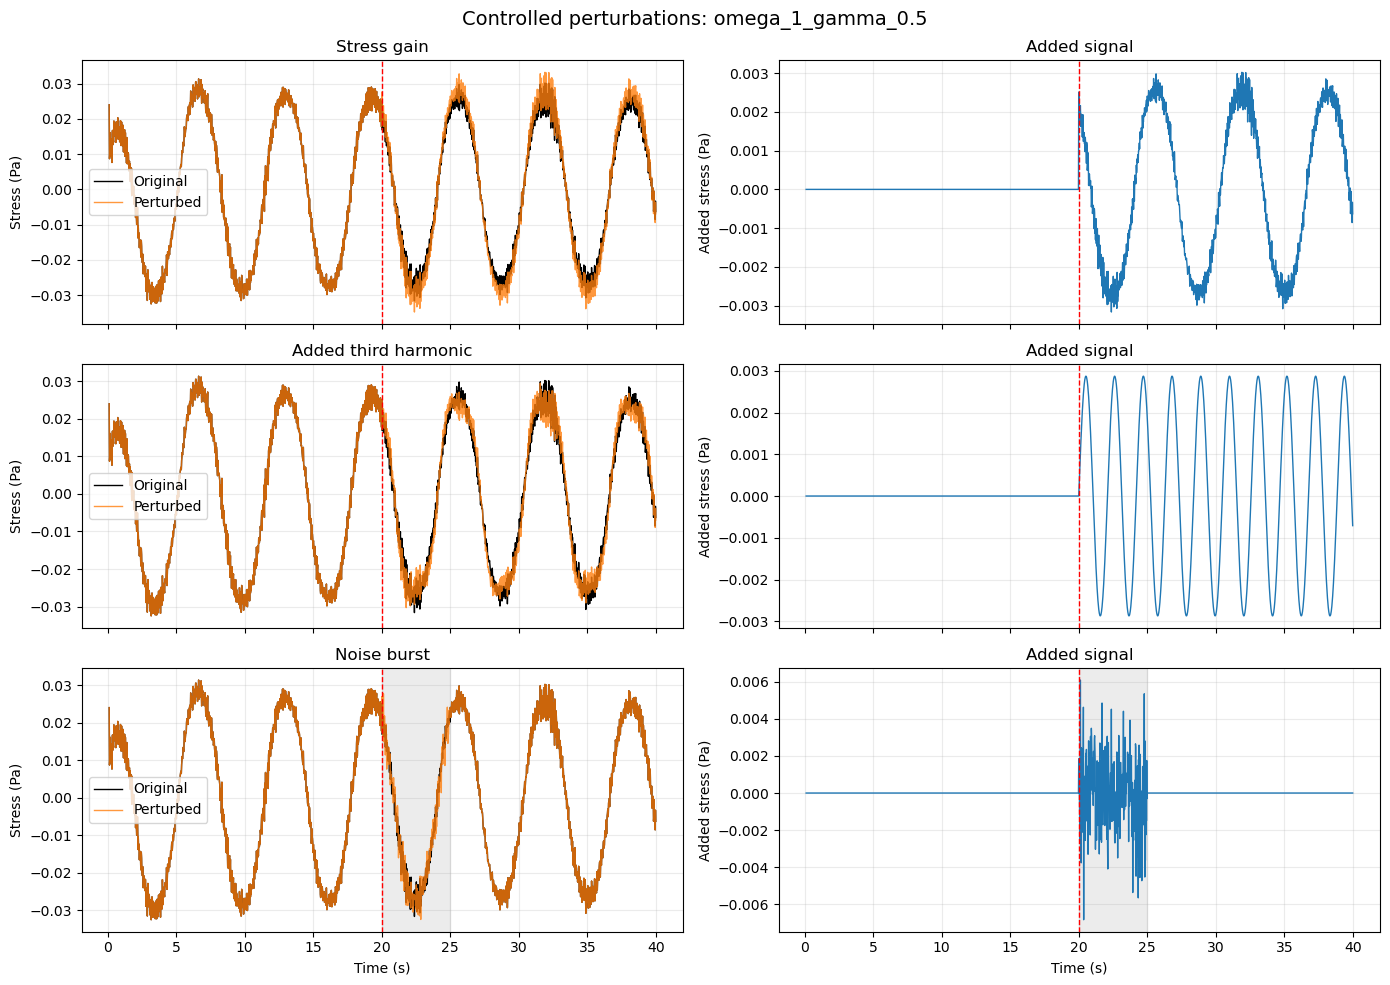

,case,experiment_id,perturbation_type,strength_fraction,reference_stress_rms_Pa,target_added_rms_Pa,actual_added_rms_Pa,actual_added_rms_over_reference,n_active_samples,first_active_sample_s,pre_onset_max_difference_Pa,outside_active_max_difference_Pa
0,omega_1_gamma_0.5,gain_0.10,gain_step,0.1,0.020245,NaN,0.001902,0.093945,1000,20.0,0.0,0.0
1,omega_1_gamma_0.5,third_harmonic_0.10,third_harmonic_step,0.1,0.020245,0.002024,0.002024,0.100000,1000,20.0,0.0,0.0
2,omega_1_gamma_0.5,noise_0.10_seed_20261010,noise_burst,0.1,0.020245,0.002024,0.002024,0.100000,250,20.0,0.0,0.0


In [15]:
# Block 14: Generate and verify perturbed APR18 signals

import matplotlib.pyplot as plt

apr18_perturbed_records = {}
injection_audit_rows = []

for _, experiment in apr18_perturbation_plan.iterrows():
    case_name = experiment["case"]
    experiment_id = experiment["experiment_id"]
    perturbation_type = experiment["perturbation_type"]
    strength = float(experiment["strength_fraction"])

    source_record = apr18_prepared_records[case_name]
    source_data = source_record["data"]

    time_s = source_data["time_s"].to_numpy(dtype=float)
    original_stress = source_data["stress_Pa"].to_numpy(dtype=float)

    onset_s = apr18_perturbation_config["onset_s"]
    pre_onset_mask = time_s < onset_s

    reference_stress = original_stress[pre_onset_mask]
    reference_centered = reference_stress - reference_stress.mean()
    reference_rms = np.sqrt(np.mean(reference_centered**2))

    if not np.isfinite(reference_rms) or reference_rms <= 0:
        raise ValueError(
            f"{case_name}: invalid pre-onset stress RMS."
        )

    perturbation = np.zeros_like(original_stress)
    active_mask = np.zeros(time_s.size, dtype=bool)
    target_added_rms = np.nan

    if perturbation_type == "gain_step":
        active_mask = time_s >= onset_s
        perturbation[active_mask] = (
            strength * original_stress[active_mask]
        )

    elif perturbation_type == "third_harmonic_step":
        active_mask = time_s >= onset_s

        fundamental_hz = (
            apr18_stft_settings[case_name]["fundamental_hz"]
        )
        phase_rad = (
            apr18_perturbation_config["third_harmonic_phase_rad"]
        )

        active_time = time_s[active_mask] - onset_s
        sinusoid = np.sin(
            2.0 * np.pi * 3.0 * fundamental_hz * active_time
            + phase_rad
        )

        target_added_rms = strength * reference_rms
        sinusoid_rms = np.sqrt(np.mean(sinusoid**2))

        perturbation[active_mask] = (
            sinusoid * target_added_rms / sinusoid_rms
        )

    elif perturbation_type == "noise_burst":
        end_s = (
            onset_s
            + apr18_perturbation_config["noise_burst_duration_s"]
        )
        active_mask = (time_s >= onset_s) & (time_s < end_s)

        rng = np.random.default_rng(int(experiment["noise_seed"]))
        noise = rng.normal(size=int(active_mask.sum()))
        noise = noise - noise.mean()

        target_added_rms = strength * reference_rms
        noise_rms = np.sqrt(np.mean(noise**2))

        perturbation[active_mask] = (
            noise * target_added_rms / noise_rms
        )

    elif perturbation_type != "original":
        raise ValueError(
            f"Unknown perturbation type: {perturbation_type}"
        )

    perturbed_stress = original_stress + perturbation

    pre_onset_max_difference = np.max(
        np.abs(
            perturbed_stress[pre_onset_mask]
            - original_stress[pre_onset_mask]
        )
    )

    outside_active_max_difference = np.max(
        np.abs(
            perturbed_stress[~active_mask]
            - original_stress[~active_mask]
        )
    )

    if pre_onset_max_difference != 0:
        raise AssertionError(
            f"{case_name}, {experiment_id}: pre-onset data changed."
        )

    if outside_active_max_difference != 0:
        raise AssertionError(
            f"{case_name}, {experiment_id}: perturbation escaped its interval."
        )

    actual_added_rms = (
        np.sqrt(np.mean(perturbation[active_mask]**2))
        if active_mask.any()
        else 0.0
    )

    if np.isfinite(target_added_rms):
        if not np.isclose(
            actual_added_rms,
            target_added_rms,
            rtol=1e-10,
            atol=0.0,
        ):
            raise AssertionError(
                f"{case_name}, {experiment_id}: RMS scaling failed."
            )

    new_data = source_data.copy(deep=True)
    new_data["stress_Pa"] = perturbed_stress

    apr18_perturbed_records[(case_name, experiment_id)] = {
        "data": new_data,
        "perturbation_Pa": perturbation.copy(),
        "metadata": experiment.to_dict(),
        "reference_stress_rms_Pa": reference_rms,
    }

    injection_audit_rows.append({
        "case": case_name,
        "experiment_id": experiment_id,
        "perturbation_type": perturbation_type,
        "strength_fraction": strength,
        "reference_stress_rms_Pa": reference_rms,
        "target_added_rms_Pa": target_added_rms,
        "actual_added_rms_Pa": actual_added_rms,
        "actual_added_rms_over_reference": (
            actual_added_rms / reference_rms
        ),
        "n_active_samples": int(active_mask.sum()),
        "first_active_sample_s": (
            time_s[active_mask][0]
            if active_mask.any()
            else np.nan
        ),
        "pre_onset_max_difference_Pa": pre_onset_max_difference,
        "outside_active_max_difference_Pa": (
            outside_active_max_difference
        ),
    })

apr18_injection_audit = pd.DataFrame(injection_audit_rows)

print(
    f"Generated {len(apr18_perturbed_records)} signal versions."
)
print("All pre-onset and outside-interval checks passed.")
print("All additive RMS scaling checks passed.")

display(
    apr18_injection_audit
    .groupby("perturbation_type", sort=False)
    .agg(
        n_versions=("experiment_id", "size"),
        max_pre_onset_difference_Pa=(
            "pre_onset_max_difference_Pa", "max"
        ),
        max_outside_interval_difference_Pa=(
            "outside_active_max_difference_Pa", "max"
        ),
    )
    .reset_index()
)

# Show one condition at the middle perturbation strength.
example_case = next(iter(apr18_prepared_records))
example_strength = ADDITIVE_RMS_FRACTIONS[1]

example_experiments = [
    (
        f"gain_{GAIN_FRACTIONS[1]:.2f}",
        "Stress gain",
    ),
    (
        f"third_harmonic_{example_strength:.2f}",
        "Added third harmonic",
    ),
    (
        f"noise_{example_strength:.2f}_seed_{NOISE_SEEDS[0]}",
        "Noise burst",
    ),
]

original_data = apr18_prepared_records[example_case]["data"]
time_s = original_data["time_s"].to_numpy(dtype=float)
original_stress = original_data["stress_Pa"].to_numpy(dtype=float)

apr18_injection_figure, axes = plt.subplots(
    3, 2, figsize=(14, 10), sharex=True
)

for row_index, (experiment_id, title) in enumerate(
    example_experiments
):
    generated = apr18_perturbed_records[
        (example_case, experiment_id)
    ]

    axes[row_index, 0].plot(
        time_s, original_stress,
        color="black", linewidth=1.0, label="Original"
    )
    axes[row_index, 0].plot(
        time_s,
        generated["data"]["stress_Pa"],
        color="tab:orange",
        linewidth=1.0,
        alpha=0.8,
        label="Perturbed",
    )
    axes[row_index, 0].set_title(title)
    axes[row_index, 0].set_ylabel("Stress (Pa)")
    axes[row_index, 0].legend()

    axes[row_index, 1].plot(
        time_s,
        generated["perturbation_Pa"],
        color="tab:blue",
        linewidth=1.0,
    )
    axes[row_index, 1].set_title("Added signal")
    axes[row_index, 1].set_ylabel("Added stress (Pa)")

    for ax in axes[row_index]:
        ax.axvline(
            PERTURBATION_ONSET_S,
            color="red",
            linestyle="--",
            linewidth=1.0,
        )
        ax.grid(alpha=0.25)

        if generated["metadata"]["perturbation_type"] == "noise_burst":
            ax.axvspan(
                PERTURBATION_ONSET_S,
                PERTURBATION_ONSET_S + NOISE_BURST_DURATION_S,
                color="grey",
                alpha=0.15,
            )

for ax in axes[-1]:
    ax.set_xlabel("Time (s)")

apr18_injection_figure.suptitle(
    f"Controlled perturbations: {example_case}",
    fontsize=14,
)
apr18_injection_figure.tight_layout()
plt.show()

display(
    apr18_injection_audit.loc[
        (apr18_injection_audit["case"] == example_case)
        & (
            apr18_injection_audit["experiment_id"].isin(
                [item[0] for item in example_experiments]
            )
        )
    ].reset_index(drop=True)
)

Feature extraction completed for 222 signal versions.
Original feature reproduction checks passed.
All complete pre-onset windows remain unchanged.


,perturbation_type,n_signal_versions,min_windows,max_windows,total_nonfinite_values,max_parseval_relative_error
0,original,6,55,55,0,6.915218e-16
1,gain_step,18,55,55,0,8.369114e-16
2,third_harmonic_step,18,55,55,0,7.963833e-16
3,noise_burst,180,55,55,0,9.787929e-16


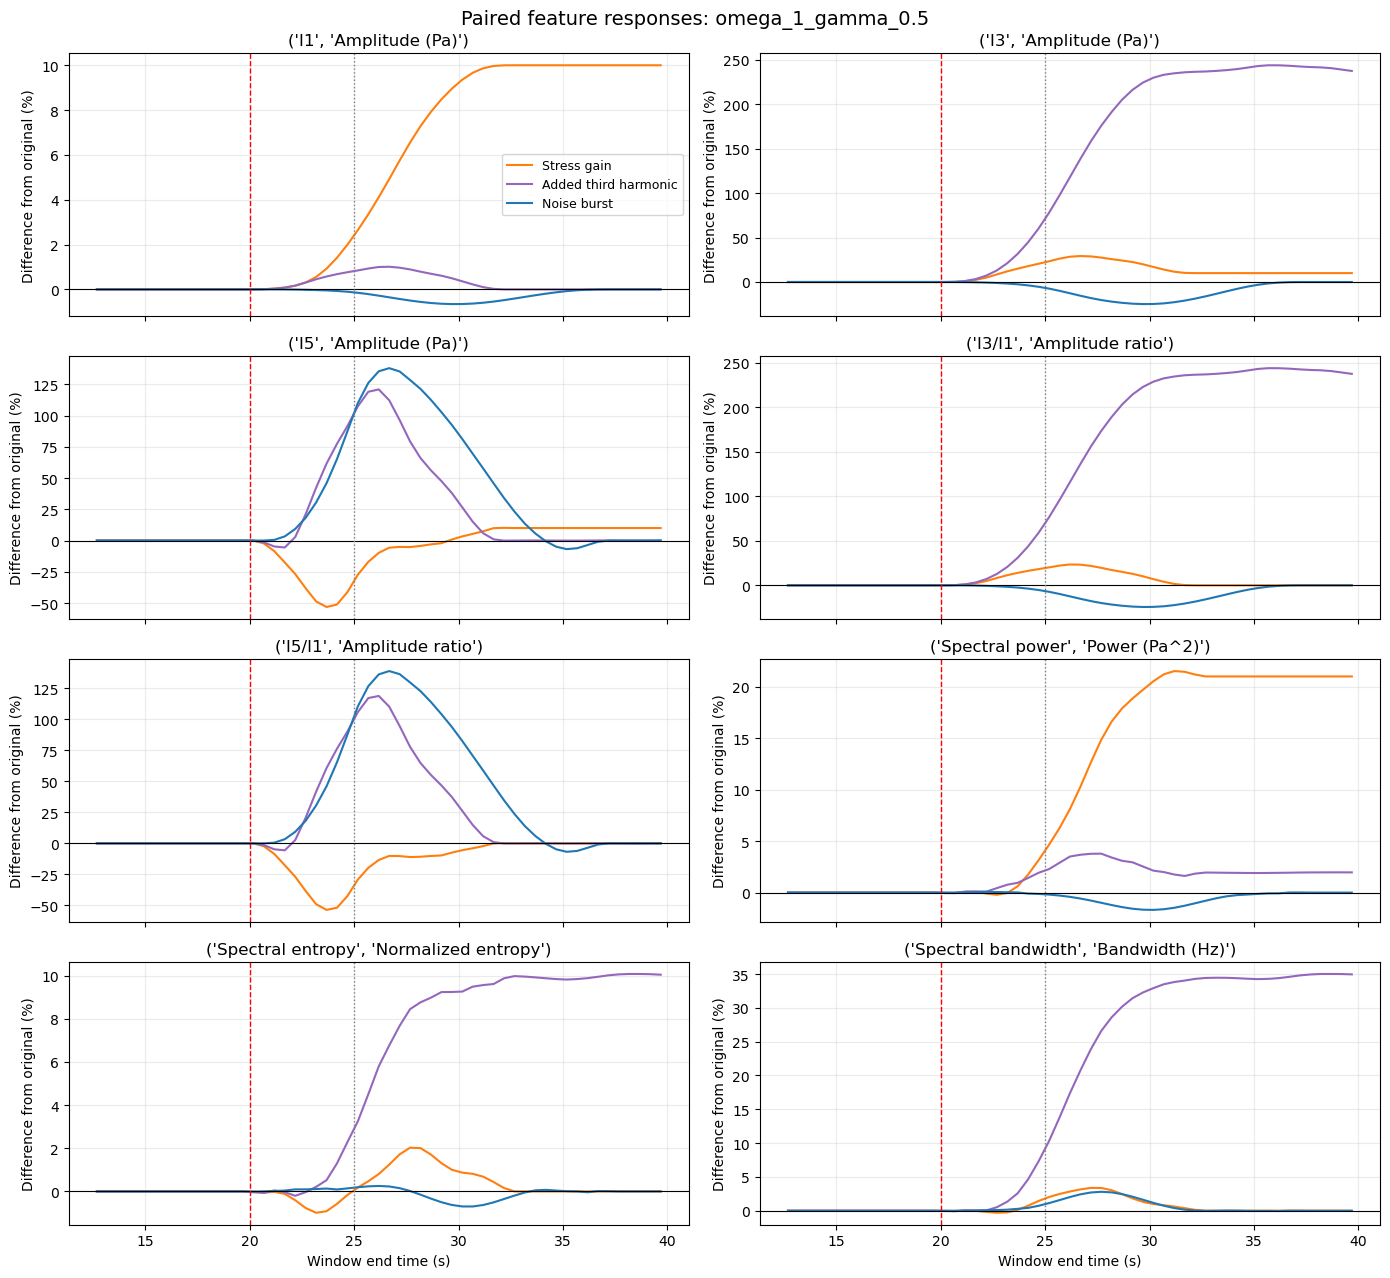

In [16]:
# Block 15: Extract features and compute paired differences

apr18_perturbation_feature_tables = {}
apr18_paired_feature_tables = {}
feature_check_rows = []

time_columns = [
    "window_start_s",
    "window_center_s",
    "window_end_s",
]

for key, generated in apr18_perturbed_records.items():
    case_name, experiment_id = key

    settings = apr18_stft_settings[case_name]
    data = generated["data"]

    time_s = data["time_s"].to_numpy(dtype=float)
    stress = data["stress_Pa"].to_numpy(dtype=float)

    n_window = settings["n_window"]
    n_hop = settings["n_hop"]
    sampling_hz = settings["sampling_hz"]

    feature_rows = []

    for start_index in range(
        0, len(stress) - n_window + 1, n_hop
    ):
        stop_index = start_index + n_window

        window_start_s = time_s[start_index]
        window_end_s = (
            time_s[stop_index - 1] + 1.0 / sampling_hz
        )

        features = extract_apr18_window_features(
            signal_values=stress[start_index:stop_index],
            sampling_hz=sampling_hz,
            fundamental_hz=settings["fundamental_hz"],
            spectral_band_hz=settings["spectral_band_hz"],
        )

        feature_rows.append({
            "window_start_s": window_start_s,
            "window_center_s": (
                window_start_s + window_end_s
            ) / 2.0,
            "window_end_s": window_end_s,
            **features,
        })

    feature_table = pd.DataFrame(feature_rows)

    original_table = (
        apr18_feature_tables[case_name]
        .reset_index(drop=True)
    )

    if len(feature_table) != len(original_table):
        raise AssertionError(
            f"{key}: window counts do not match."
        )

    if not np.allclose(
        feature_table[time_columns].to_numpy(),
        original_table[time_columns].to_numpy(),
        rtol=0.0,
        atol=1e-9,
    ):
        raise AssertionError(
            f"{key}: window times do not match."
        )

    perturbed_values = feature_table[
        FEATURE_COLUMNS
    ].to_numpy(dtype=float)

    original_values = original_table[
        FEATURE_COLUMNS
    ].to_numpy(dtype=float)

    if not np.isfinite(perturbed_values).all():
        raise ValueError(
            f"{key}: non-finite feature values were found."
        )

    pre_onset_windows = (
        feature_table["window_end_s"].to_numpy()
        <= PERTURBATION_ONSET_S + 1e-9
    )

    if not np.allclose(
        perturbed_values[pre_onset_windows],
        original_values[pre_onset_windows],
        rtol=1e-10,
        atol=1e-12,
    ):
        raise AssertionError(
            f"{key}: pre-onset features changed."
        )

    if experiment_id == "original":
        if not np.allclose(
            perturbed_values,
            original_values,
            rtol=1e-10,
            atol=1e-12,
        ):
            raise AssertionError(
                f"{case_name}: original feature reproduction failed."
            )

    paired_table = feature_table[time_columns].copy()

    for feature in FEATURE_COLUMNS:
        original = original_table[feature].to_numpy(dtype=float)
        perturbed = feature_table[feature].to_numpy(dtype=float)

        difference = perturbed - original
        relative_difference = np.full_like(
            difference, np.nan, dtype=float
        )

        valid_denominator = (
            np.abs(original) > np.finfo(float).eps
        )

        np.divide(
            100.0 * difference,
            original,
            out=relative_difference,
            where=valid_denominator,
        )

        paired_table[f"{feature}_difference"] = difference
        paired_table[f"{feature}_difference_percent"] = (
            relative_difference
        )

    apr18_perturbation_feature_tables[key] = feature_table
    apr18_paired_feature_tables[key] = paired_table

    feature_check_rows.append({
        "case": case_name,
        "experiment_id": experiment_id,
        "perturbation_type": (
            generated["metadata"]["perturbation_type"]
        ),
        "n_windows": len(feature_table),
        "n_complete_pre_onset_windows": (
            int(pre_onset_windows.sum())
        ),
        "n_nonfinite_feature_values": (
            int((~np.isfinite(perturbed_values)).sum())
        ),
        "max_parseval_relative_error": (
            feature_table["parseval_relative_error"].max()
        ),
    })

apr18_perturbation_feature_checks = pd.DataFrame(
    feature_check_rows
)

print(
    "Feature extraction completed for "
    f"{len(apr18_perturbation_feature_tables)} signal versions."
)
print("Original feature reproduction checks passed.")
print("All complete pre-onset windows remain unchanged.")

display(
    apr18_perturbation_feature_checks
    .groupby("perturbation_type", sort=False)
    .agg(
        n_signal_versions=("experiment_id", "size"),
        min_windows=("n_windows", "min"),
        max_windows=("n_windows", "max"),
        total_nonfinite_values=(
            "n_nonfinite_feature_values", "sum"
        ),
        max_parseval_relative_error=(
            "max_parseval_relative_error", "max"
        ),
    )
    .reset_index()
)

# Plot paired feature responses for the Block 14 examples.
apr18_paired_response_figure, axes = plt.subplots(
    4, 2, figsize=(14, 13), sharex=True
)

response_colors = [
    "tab:orange",
    "tab:purple",
    "tab:blue",
]

for ax, feature in zip(axes.flat, FEATURE_COLUMNS):
    for (experiment_id, label), color in zip(
        example_experiments, response_colors
    ):
        paired = apr18_paired_feature_tables[
            (example_case, experiment_id)
        ]

        ax.plot(
            paired["window_end_s"],
            paired[f"{feature}_difference_percent"],
            label=label,
            color=color,
            linewidth=1.5,
        )

    ax.axhline(0.0, color="black", linewidth=0.8)
    ax.axvline(
        PERTURBATION_ONSET_S,
        color="red",
        linestyle="--",
        linewidth=1.0,
    )
    ax.axvline(
        PERTURBATION_ONSET_S + NOISE_BURST_DURATION_S,
        color="grey",
        linestyle=":",
        linewidth=1.0,
    )

    ax.set_title(FEATURE_LABELS.get(feature, feature))
    ax.set_ylabel("Difference from original (%)")
    ax.grid(alpha=0.25)

axes[0, 0].legend(fontsize=9)

for ax in axes[-1]:
    ax.set_xlabel("Window end time (s)")

apr18_paired_response_figure.suptitle(
    f"Paired feature responses: {example_case}",
    fontsize=14,
)
apr18_paired_response_figure.tight_layout()
plt.show()

In [17]:
# Block 16: Quantify paired feature responses

response_metric_rows = []

for key, paired_table in apr18_paired_feature_tables.items():
    case_name, experiment_id = key
    metadata = apr18_perturbed_records[key]["metadata"]

    perturbation_type = metadata["perturbation_type"]

    if perturbation_type == "original":
        continue

    onset_s = float(metadata["onset_s"])
    window_start = paired_table["window_start_s"].to_numpy()
    window_end = paired_table["window_end_s"].to_numpy()

    # Include transition windows when measuring the peak response.
    post_onset_mask = window_end > onset_s + 1e-9

    # These windows contain only samples from the post-onset interval.
    fully_post_onset_mask = window_start >= onset_s - 1e-9

    if perturbation_type == "noise_burst":
        noise_end_s = onset_s + float(metadata["duration_s"])
        recovery_mask = window_start >= noise_end_s - 1e-9
    else:
        recovery_mask = np.zeros(len(paired_table), dtype=bool)

    for feature in FEATURE_COLUMNS:
        relative_change = paired_table[
            f"{feature}_difference_percent"
        ].to_numpy(dtype=float)

        absolute_change = paired_table[
            f"{feature}_difference"
        ].to_numpy(dtype=float)

        valid_peak_mask = (
            post_onset_mask & np.isfinite(relative_change)
        )
        candidate_indices = np.flatnonzero(valid_peak_mask)

        if candidate_indices.size:
            peak_index = candidate_indices[
                np.argmax(
                    np.abs(relative_change[candidate_indices])
                )
            ]
            peak_signed_percent = relative_change[peak_index]
            peak_absolute_difference = absolute_change[peak_index]
            peak_time_s = window_end[peak_index]
        else:
            peak_signed_percent = np.nan
            peak_absolute_difference = np.nan
            peak_time_s = np.nan

        # A sustained post-onset summary is used only for step perturbations.
        if perturbation_type != "noise_burst":
            sustained_values = relative_change[
                fully_post_onset_mask
                & np.isfinite(relative_change)
            ]
            sustained_median_percent = (
                np.median(sustained_values)
                if sustained_values.size
                else np.nan
            )
        else:
            sustained_median_percent = np.nan

        recovery_values = relative_change[
            recovery_mask & np.isfinite(relative_change)
        ]
        recovery_max_abs_percent = (
            np.max(np.abs(recovery_values))
            if recovery_values.size
            else np.nan
        )

        response_metric_rows.append({
            "case": case_name,
            "experiment_id": experiment_id,
            "perturbation_type": perturbation_type,
            "strength_fraction": float(
                metadata["strength_fraction"]
            ),
            "noise_seed": metadata["noise_seed"],
            "feature": feature,
            "peak_signed_difference_percent": peak_signed_percent,
            "peak_abs_difference_percent": (
                abs(peak_signed_percent)
            ),
            "absolute_difference_at_peak": (
                peak_absolute_difference
            ),
            "peak_response_time_s": peak_time_s,
            "peak_response_lag_s": peak_time_s - onset_s,
            "fully_post_onset_median_difference_percent": (
                sustained_median_percent
            ),
            "recovery_max_abs_difference_percent": (
                recovery_max_abs_percent
            ),
            "n_fully_post_onset_windows": (
                int(fully_post_onset_mask.sum())
            ),
            "n_recovery_windows": int(recovery_mask.sum()),
        })

apr18_response_metrics = pd.DataFrame(response_metric_rows)

# Verify expected scaling for windows entirely after the gain step.
gain_scaling_rows = []

for key, paired_table in apr18_paired_feature_tables.items():
    metadata = apr18_perturbed_records[key]["metadata"]

    if metadata["perturbation_type"] != "gain_step":
        continue

    gain = float(metadata["strength_fraction"])
    complete_mask = (
        paired_table["window_start_s"]
        >= float(metadata["onset_s"]) - 1e-9
    )

    for feature in FEATURE_COLUMNS:
        if feature in ["I1_Pa", "I3_Pa", "I5_Pa"]:
            expected_percent = 100.0 * gain
        elif feature == "spectral_power_Pa2":
            expected_percent = 100.0 * ((1.0 + gain)**2 - 1.0)
        else:
            expected_percent = 0.0

        measured_percent = paired_table.loc[
            complete_mask,
            f"{feature}_difference_percent",
        ].to_numpy(dtype=float)

        if not np.allclose(
            measured_percent,
            expected_percent,
            rtol=1e-8,
            atol=1e-8,
        ):
            raise AssertionError(
                f"{key}, {feature}: gain scaling check failed."
            )

        gain_scaling_rows.append({
            "case": key[0],
            "experiment_id": key[1],
            "feature": feature,
            "expected_difference_percent": expected_percent,
            "measured_median_difference_percent": (
                np.median(measured_percent)
            ),
        })

apr18_gain_scaling_checks = pd.DataFrame(gain_scaling_rows)

print(
    f"Calculated {len(apr18_response_metrics)} feature response summaries."
)
print("All fully post-onset gain scaling checks passed.")

# Show the same three examples used in Blocks 14 and 15.
example_ids = [item[0] for item in example_experiments]

apr18_example_response_metrics = (
    apr18_response_metrics.loc[
        (apr18_response_metrics["case"] == example_case)
        & apr18_response_metrics["experiment_id"].isin(example_ids),
        [
            "perturbation_type",
            "feature",
            "peak_signed_difference_percent",
            "absolute_difference_at_peak",
            "peak_response_time_s",
            "fully_post_onset_median_difference_percent",
            "recovery_max_abs_difference_percent",
        ],
    ]
    .reset_index(drop=True)
)

display(apr18_example_response_metrics.round(6))

# Summarize repeated noise runs within each condition first.
apr18_response_by_case = (
    apr18_response_metrics
    .groupby(
        ["case", "perturbation_type", "strength_fraction", "feature"],
        sort=False,
    )
    .agg(
        n_signal_versions=("experiment_id", "size"),
        median_peak_abs_difference_percent=(
            "peak_abs_difference_percent", "median"
        ),
        min_peak_abs_difference_percent=(
            "peak_abs_difference_percent", "min"
        ),
        max_peak_abs_difference_percent=(
            "peak_abs_difference_percent", "max"
        ),
        median_sustained_difference_percent=(
            "fully_post_onset_median_difference_percent", "median"
        ),
        max_recovery_abs_difference_percent=(
            "recovery_max_abs_difference_percent", "max"
        ),
    )
    .reset_index()
)

display(
    apr18_response_by_case.loc[
        (apr18_response_by_case["case"] == example_case)
        & np.isclose(
            apr18_response_by_case["strength_fraction"], 0.10
        )
    ].round(6).reset_index(drop=True)
)


Calculated 1728 feature response summaries.
All fully post-onset gain scaling checks passed.


,perturbation_type,feature,peak_signed_difference_percent,absolute_difference_at_peak,peak_response_time_s,fully_post_onset_median_difference_percent,recovery_max_abs_difference_percent
0,gain_step,I1_Pa,10.000000,0.002715,36.68,10.000000,NaN
1,gain_step,I3_Pa,29.212339,0.000334,26.68,10.000000,NaN
2,gain_step,I5_Pa,-53.189184,-0.000070,23.68,10.000000,NaN
3,gain_step,I3_I1,23.371126,0.009697,26.18,0.000000,NaN
4,gain_step,I5_I1,-53.617848,-0.002503,23.68,0.000000,NaN
5,gain_step,spectral_power_Pa2,21.523085,0.000082,31.18,21.000000,NaN
6,gain_step,spectral_entropy,2.026436,0.006575,27.68,0.000000,NaN
7,gain_step,spectral_bandwidth_Hz,3.378260,0.001615,27.18,-0.000000,NaN
8,third_harmonic_step,I1_Pa,1.009183,0.000280,26.68,0.000075,NaN
9,third_harmonic_step,I3_Pa,243.823910,0.002803,35.68,241.199617,NaN


,case,perturbation_type,strength_fraction,feature,n_signal_versions,median_peak_abs_difference_percent,min_peak_abs_difference_percent,max_peak_abs_difference_percent,median_sustained_difference_percent,max_recovery_abs_difference_percent
0,omega_1_gamma_0.5,gain_step,0.1,I1_Pa,1,10.000000,10.000000,10.000000,10.000000,NaN
1,omega_1_gamma_0.5,gain_step,0.1,I3_Pa,1,29.212339,29.212339,29.212339,10.000000,NaN
2,omega_1_gamma_0.5,gain_step,0.1,I5_Pa,1,53.189184,53.189184,53.189184,10.000000,NaN
3,omega_1_gamma_0.5,gain_step,0.1,I3_I1,1,23.371126,23.371126,23.371126,0.000000,NaN
4,omega_1_gamma_0.5,gain_step,0.1,I5_I1,1,53.617848,53.617848,53.617848,0.000000,NaN
5,omega_1_gamma_0.5,gain_step,0.1,spectral_power_Pa2,1,21.523085,21.523085,21.523085,21.000000,NaN
6,omega_1_gamma_0.5,gain_step,0.1,spectral_entropy,1,2.026436,2.026436,2.026436,0.000000,NaN
7,omega_1_gamma_0.5,gain_step,0.1,spectral_bandwidth_Hz,1,3.378260,3.378260,3.378260,-0.000000,NaN
8,omega_1_gamma_0.5,third_harmonic_step,0.1,I1_Pa,1,1.009183,1.009183,1.009183,0.000075,NaN
9,omega_1_gamma_0.5,third_harmonic_step,0.1,I3_Pa,1,243.823910,243.823910,243.823910,241.199617,NaN


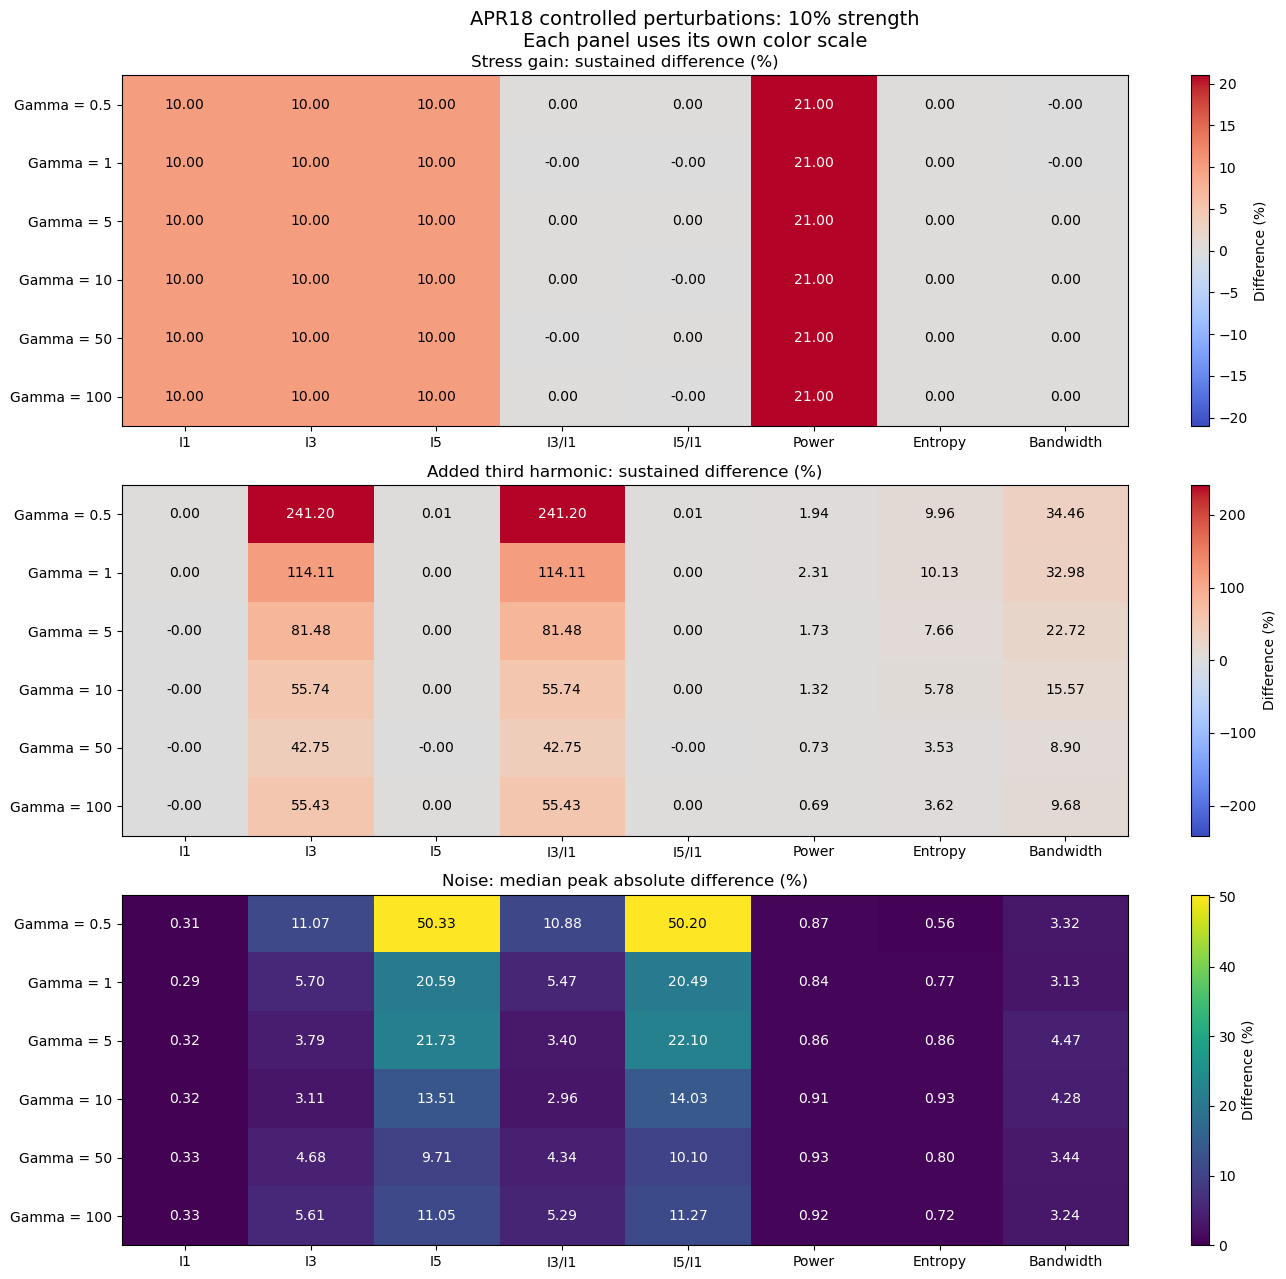

Maximum post-noise recovery difference across all experiments: 0%
Results saved to: /Users/g.y/Desktop/Project team 35/code/apr18_semisynthetic_laos_v2/results/APR18_perturbation_analysis_20261011_014719_318392


In [18]:
# Block 17: Compare conditions and export perturbation results

from pathlib import Path
from datetime import datetime
import json

SUMMARY_STRENGTH = 0.10

feature_display_names = [
    "I1", "I3", "I5", "I3/I1", "I5/I1",
    "Power", "Entropy", "Bandwidth",
]

case_order = list(apr18_prepared_records)

case_display_names = [
    f"Gamma = {apr18_prepared_records[case]['gamma_nominal']:g}"
    for case in case_order
]

panel_definitions = [
    (
        "gain_step",
        "median_sustained_difference_percent",
        "Stress gain: sustained difference (%)",
        True,
    ),
    (
        "third_harmonic_step",
        "median_sustained_difference_percent",
        "Added third harmonic: sustained difference (%)",
        True,
    ),
    (
        "noise_burst",
        "median_peak_abs_difference_percent",
        "Noise: median peak absolute difference (%)",
        False,
    ),
]

apr18_condition_comparison_figure, axes = plt.subplots(
    3, 1, figsize=(14, 13)
)

for ax, (
    perturbation_type,
    metric,
    title,
    signed_metric,
) in zip(axes, panel_definitions):

    selected = apr18_response_by_case.loc[
        (
            apr18_response_by_case["perturbation_type"]
            == perturbation_type
        )
        & np.isclose(
            apr18_response_by_case["strength_fraction"],
            SUMMARY_STRENGTH,
        )
    ]

    matrix = (
        selected.pivot(
            index="case",
            columns="feature",
            values=metric,
        )
        .reindex(index=case_order, columns=FEATURE_COLUMNS)
        .to_numpy(dtype=float)
    )

    if not np.isfinite(matrix).all():
        raise ValueError(
            f"{perturbation_type}: comparison values are incomplete."
        )

    color_limit = max(float(np.max(np.abs(matrix))), 1e-12)

    heatmap = ax.imshow(
        matrix,
        aspect="auto",
        cmap="coolwarm" if signed_metric else "viridis",
        vmin=-color_limit if signed_metric else 0.0,
        vmax=color_limit,
    )

    for row_index in range(matrix.shape[0]):
        for column_index in range(matrix.shape[1]):
            value = matrix[row_index, column_index]

            if signed_metric:
                text_color = (
                    "white"
                    if abs(value) > 0.65 * color_limit
                    else "black"
                )
            else:
                text_color = (
                    "white"
                    if value < 0.45 * color_limit
                    else "black"
                )

            ax.text(
                column_index,
                row_index,
                f"{value:.2f}",
                ha="center",
                va="center",
                color=text_color,
                fontsize=10,
            )

    ax.set_xticks(range(len(FEATURE_COLUMNS)))
    ax.set_xticklabels(feature_display_names)
    ax.set_yticks(range(len(case_order)))
    ax.set_yticklabels(case_display_names)
    ax.set_title(title)

    apr18_condition_comparison_figure.colorbar(
        heatmap, ax=ax, label="Difference (%)"
    )

apr18_condition_comparison_figure.suptitle(
    "APR18 controlled perturbations: 10% strength\n"
    "Each panel uses its own color scale",
    fontsize=14,
)
apr18_condition_comparison_figure.tight_layout()
plt.show()

# Check recovery across all noise conditions, strengths, and seeds.
noise_metrics = apr18_response_metrics.loc[
    apr18_response_metrics["perturbation_type"] == "noise_burst"
]

max_noise_recovery_difference = noise_metrics[
    "recovery_max_abs_difference_percent"
].max()

print(
    "Maximum post-noise recovery difference across all experiments: "
    f"{max_noise_recovery_difference:.6g}%"
)

# Export separately from the original APR18 analysis.
export_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
apr18_perturbation_output_dir = (
    Path("results")
    / f"APR18_perturbation_analysis_{export_timestamp}"
)
apr18_perturbation_output_dir.mkdir(
    parents=True, exist_ok=False
)

tables_to_export = {
    "experiment_plan": apr18_perturbation_plan,
    "injection_audit": apr18_injection_audit,
    "feature_checks": apr18_perturbation_feature_checks,
    "response_metrics": apr18_response_metrics,
    "response_by_case": apr18_response_by_case,
    "gain_scaling_checks": apr18_gain_scaling_checks,
}

for filename, table in tables_to_export.items():
    table.to_csv(
        apr18_perturbation_output_dir / f"{filename}.csv",
        index=False,
    )

# Export full feature trajectories and paired differences.
for filename, table_collection in [
    ("feature_trajectories", apr18_perturbation_feature_tables),
    ("paired_feature_differences", apr18_paired_feature_tables),
]:
    export_parts = []

    for (case_name, experiment_id), table in table_collection.items():
        part = table.copy()
        part.insert(0, "experiment_id", experiment_id)
        part.insert(0, "case", case_name)
        export_parts.append(part)

    pd.concat(export_parts, ignore_index=True).to_csv(
        apr18_perturbation_output_dir / f"{filename}.csv",
        index=False,
    )

figures_to_export = {
    "injected_signal_examples": apr18_injection_figure,
    "paired_feature_response_examples": apr18_paired_response_figure,
    "condition_comparison": apr18_condition_comparison_figure,
}

for filename, figure in figures_to_export.items():
    figure.savefig(
        apr18_perturbation_output_dir / f"{filename}.png",
        dpi=300,
        bbox_inches="tight",
    )

export_config = {
    **apr18_perturbation_config,
    "feature_columns": FEATURE_COLUMNS,
    "stft_settings_by_case": apr18_stft_settings,
    "summary_plot_strength": SUMMARY_STRENGTH,
    "sinusoid_time_origin": "Perturbation onset",
    "additive_scaling": (
        "Exact RMS normalization over the active sample interval"
    ),
    "noise_generation": (
        "Gaussian draws, centered and RMS-normalized within the burst"
    ),
    "noise_seed_pairing": (
        "Seeds are reused across conditions and strengths"
    ),
    "interpretation": (
        "Paired feature sensitivity analysis; "
        "not a validated change-time detector"
    ),
}

def convert_numpy_json(value):
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    raise TypeError(
        f"Cannot serialize object of type {type(value).__name__}"
    )

with open(
    apr18_perturbation_output_dir / "experiment_config.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        export_config,
        file,
        indent=2,
        default=convert_numpy_json,
        allow_nan=False,
    )

notes = [
    "The original APR18 dataset has no verified change-time ground truth.",
    "The known times refer only to the added perturbations.",
    "Paired differences use the original feature at the same window.",
    "Peak response time is not a predicted change time.",
    "Relative differences can be large for small original features.",
    "Noise seeds are simulation repeats, not independent donors.",
    "Spectral power, entropy, and bandwidth use the configured frequency band.",
    "Exact post-noise recovery follows from unchanged samples after the burst.",
    "No alarm threshold or detection performance is evaluated in these blocks.",
]

(
    apr18_perturbation_output_dir / "interpretation_notes.txt"
).write_text("\n".join(notes), encoding="utf-8")

print(f"Results saved to: {apr18_perturbation_output_dir.resolve()}")

In [19]:
# Block 18: Define alarm rules and inspect reference coverage

APR18_TEST_REFERENCE_END_S = 20.0
APR18_TEST_Z_THRESHOLD = 5.0
APR18_TEST_PERSISTENCE_S = 1.0

apr18_perturbation_alarm_config = {
    "reference_end_s": APR18_TEST_REFERENCE_END_S,
    "z_threshold": APR18_TEST_Z_THRESHOLD,
    "persistence_s": APR18_TEST_PERSISTENCE_S,
    "direction_rule": "Two-sided for all eight features",
    "reference_rule": "Complete windows ending at or before reference end",
    "monitoring_rule": "All window outputs after reference end",
    "time_stamp": "Exclusive window end time",
    "reference_scale": "1.4826 times median absolute deviation",
    "zero_scale_rule": "Undefined score; no artificial scale replacement",
    "parameter_status": "Exploratory fixed settings",
}

def count_disjoint_reference_windows(window_table):
    ordered = window_table.sort_values("window_start_s")

    count = 0
    previous_end_s = -np.inf

    for row in ordered.itertuples(index=False):
        if row.window_start_s >= previous_end_s - 1e-9:
            count += 1
            previous_end_s = row.window_end_s

    return count

apr18_perturbation_reference_stats = {}
reference_stat_rows = []
reference_coverage_rows = []

for case_name in apr18_prepared_records:
    original_table = (
        apr18_perturbation_feature_tables[(case_name, "original")]
        .reset_index(drop=True)
    )

    reference_mask = (
        original_table["window_end_s"]
        <= APR18_TEST_REFERENCE_END_S + 1e-9
    )
    monitoring_mask = (
        original_table["window_end_s"]
        > APR18_TEST_REFERENCE_END_S + 1e-9
    )

    reference_table = original_table.loc[reference_mask]
    monitoring_table = original_table.loc[monitoring_mask]

    if reference_table.empty or monitoring_table.empty:
        raise ValueError(
            f"{case_name}: reference or monitoring windows are unavailable."
        )

    # Confirm that every version has the same pre-monitoring features.
    original_reference_values = reference_table[
        FEATURE_COLUMNS
    ].to_numpy(dtype=float)

    for key, feature_table in apr18_perturbation_feature_tables.items():
        if key[0] != case_name:
            continue

        version_reference_values = feature_table.loc[
            reference_mask, FEATURE_COLUMNS
        ].to_numpy(dtype=float)

        if not np.allclose(
            version_reference_values,
            original_reference_values,
            rtol=1e-10,
            atol=1e-12,
        ):
            raise AssertionError(
                f"{key}: reference features differ from the original."
            )

    first_monitoring_end_s = monitoring_table[
        "window_end_s"
    ].iloc[0]

    n_disjoint = count_disjoint_reference_windows(reference_table)

    reference_coverage_rows.append({
        "case": case_name,
        "window_duration_s": (
            apr18_stft_settings[case_name]["window_duration_s"]
        ),
        "n_reference_outputs": len(reference_table),
        "n_disjoint_reference_windows": n_disjoint,
        "n_monitoring_outputs": len(monitoring_table),
        "first_monitoring_window_start_s": (
            monitoring_table["window_start_s"].iloc[0]
        ),
        "first_monitoring_window_end_s": first_monitoring_end_s,
        "last_monitoring_window_end_s": (
            monitoring_table["window_end_s"].iloc[-1]
        ),
        "earliest_possible_confirmation_s": (
            first_monitoring_end_s + APR18_TEST_PERSISTENCE_S
        ),
        "reference_reliability": "Not established",
    })

    for feature in FEATURE_COLUMNS:
        values = reference_table[feature].to_numpy(dtype=float)

        reference_median = np.median(values)
        reference_mad = np.median(
            np.abs(values - reference_median)
        )
        reference_scale = 1.4826 * reference_mad

        scale_valid = (
            np.isfinite(reference_scale)
            and reference_scale > 0.0
        )

        stats = {
            "reference_median": reference_median,
            "reference_mad": reference_mad,
            "reference_scale": reference_scale,
            "scale_valid": bool(scale_valid),
        }

        apr18_perturbation_reference_stats[
            (case_name, feature)
        ] = stats

        reference_stat_rows.append({
            "case": case_name,
            "feature": feature,
            **stats,
            "lower_alarm_boundary": (
                reference_median
                - APR18_TEST_Z_THRESHOLD * reference_scale
                if scale_valid else np.nan
            ),
            "upper_alarm_boundary": (
                reference_median
                + APR18_TEST_Z_THRESHOLD * reference_scale
                if scale_valid else np.nan
            ),
        })

apr18_perturbation_reference_coverage = pd.DataFrame(
    reference_coverage_rows
)

apr18_perturbation_reference_summary = pd.DataFrame(
    reference_stat_rows
)

print("Exploratory alarm settings")
print(f"Reference end: {APR18_TEST_REFERENCE_END_S:.1f} s")
print(f"Two-sided threshold: |z| >= {APR18_TEST_Z_THRESHOLD:.1f}")
print(
    "Required continuous exceedance duration: "
    f"{APR18_TEST_PERSISTENCE_S:.1f} s"
)
print("All signal versions have matching reference features.")

display(apr18_perturbation_reference_coverage)

display(
    apr18_perturbation_reference_summary.loc[
        apr18_perturbation_reference_summary["case"]
        == example_case
    ].reset_index(drop=True)
)

invalid_scales = apr18_perturbation_reference_summary.loc[
    ~apr18_perturbation_reference_summary["scale_valid"]
]

print(f"Number of undefined reference scales: {len(invalid_scales)}")

if not invalid_scales.empty:
    display(invalid_scales)

Exploratory alarm settings
Reference end: 20.0 s
Two-sided threshold: |z| >= 5.0
Required continuous exceedance duration: 1.0 s
All signal versions have matching reference features.


,case,window_duration_s,n_reference_outputs,n_disjoint_reference_windows,n_monitoring_outputs,first_monitoring_window_start_s,first_monitoring_window_end_s,last_monitoring_window_end_s,earliest_possible_confirmation_s,reference_reliability
0,omega_1_gamma_0.5,12.56,15,1,40,7.62,20.18,39.68,21.18,Not established
1,omega_1_gamma_1,12.56,15,1,40,7.62,20.18,39.68,21.18,Not established
2,omega_1_gamma_5,12.56,15,1,40,7.62,20.18,39.68,21.18,Not established
3,omega_1_gamma_10,12.56,15,1,40,7.62,20.18,39.68,21.18,Not established
4,omega_1_gamma_50,12.56,15,1,40,7.62,20.18,39.68,21.18,Not established
5,omega_1_gamma_100,12.56,15,1,40,7.62,20.18,39.68,21.18,Not established


,case,feature,reference_median,reference_mad,reference_scale,scale_valid,lower_alarm_boundary,upper_alarm_boundary
0,omega_1_gamma_0.5,I1_Pa,0.029022,0.000354,0.000524,True,0.026401,0.031643
1,omega_1_gamma_0.5,I3_Pa,0.001087,0.000032,0.000047,True,0.000852,0.001322
2,omega_1_gamma_0.5,I5_Pa,0.000135,0.000003,0.000005,True,0.000110,0.000160
3,omega_1_gamma_0.5,I3_I1,0.036954,0.001147,0.001701,True,0.028450,0.045457
4,omega_1_gamma_0.5,I5_I1,0.004733,0.000138,0.000205,True,0.003709,0.005757
5,omega_1_gamma_0.5,spectral_power_Pa2,0.000424,0.000010,0.000015,True,0.000351,0.000497
6,omega_1_gamma_0.5,spectral_entropy,0.325749,0.000520,0.000771,True,0.321895,0.329603
7,omega_1_gamma_0.5,spectral_bandwidth_Hz,0.047946,0.000237,0.000351,True,0.046189,0.049703


Number of undefined reference scales: 0


In [20]:
# Block 19: Run exploratory alarms on all signal versions

def find_controlled_alarm_events(
    times_s,
    signed_scores,
    monitoring_mask,
    threshold,
    persistence_s,
    expected_hop_s,
):
    times_s = np.asarray(times_s, dtype=float)
    signed_scores = np.asarray(signed_scores, dtype=float)
    monitoring_mask = np.asarray(monitoring_mask, dtype=bool)

    events = []
    run_start_index = None
    confirmation_index = None
    last_run_index = None
    run_direction = 0

    def save_confirmed_run():
        if confirmation_index is not None:
            events.append({
                "qualified_run_start_s": times_s[run_start_index],
                "alarm_time_s": times_s[confirmation_index],
                "last_exceedance_s": times_s[last_run_index],
                "direction": (
                    "increase" if run_direction == 1 else "decrease"
                ),
                "signed_z_at_confirmation": (
                    signed_scores[confirmation_index]
                ),
                "run_start_index": int(run_start_index),
                "confirmation_index": int(confirmation_index),
                "run_reaches_record_end": (
                    last_run_index == len(times_s) - 1
                ),
            })

    for index in range(len(times_s)):
        eligible = (
            monitoring_mask[index]
            and np.isfinite(signed_scores[index])
            and abs(signed_scores[index]) >= threshold
        )

        direction = (
            int(np.sign(signed_scores[index]))
            if eligible else 0
        )

        continues_run = (
            eligible
            and run_start_index is not None
            and direction == run_direction
            and index == last_run_index + 1
            and np.isclose(
                times_s[index] - times_s[last_run_index],
                expected_hop_s,
                rtol=0.0,
                atol=1e-8,
            )
        )

        if not continues_run:
            save_confirmed_run()

            run_start_index = None
            confirmation_index = None
            last_run_index = None
            run_direction = 0

            if eligible:
                run_start_index = index
                run_direction = direction

        if eligible:
            last_run_index = index

            if (
                confirmation_index is None
                and times_s[index] - times_s[run_start_index]
                >= persistence_s - 1e-9
            ):
                confirmation_index = index

    save_confirmed_run()
    return events


apr18_perturbation_scored_tables = {}
alarm_summary_rows = []
alarm_event_rows = []

for key, feature_table in apr18_perturbation_feature_tables.items():
    case_name, experiment_id = key
    metadata = apr18_perturbed_records[key]["metadata"]

    scored_table = feature_table.copy()
    times_s = scored_table["window_end_s"].to_numpy(dtype=float)

    monitoring_mask = (
        times_s > APR18_TEST_REFERENCE_END_S + 1e-9
    )
    scored_table["monitoring_window"] = monitoring_mask

    first_monitoring_index = np.flatnonzero(monitoring_mask)[0]

    for feature in FEATURE_COLUMNS:
        stats = apr18_perturbation_reference_stats[
            (case_name, feature)
        ]

        values = scored_table[feature].to_numpy(dtype=float)
        scores = np.full_like(values, np.nan)

        if stats["scale_valid"]:
            scores = (
                values - stats["reference_median"]
            ) / stats["reference_scale"]

        scored_table[f"{feature}_signed_z"] = scores

        exceedance_mask = (
            monitoring_mask
            & np.isfinite(scores)
            & (np.abs(scores) >= APR18_TEST_Z_THRESHOLD)
        )

        exceedance_indices = np.flatnonzero(exceedance_mask)
        first_exceedance_s = (
            times_s[exceedance_indices[0]]
            if exceedance_indices.size else np.nan
        )

        events = find_controlled_alarm_events(
            times_s=times_s,
            signed_scores=scores,
            monitoring_mask=monitoring_mask,
            threshold=APR18_TEST_Z_THRESHOLD,
            persistence_s=APR18_TEST_PERSISTENCE_S,
            expected_hop_s=(
                apr18_stft_settings[case_name]["hop_duration_s"]
            ),
        )

        first_event = events[0] if events else None

        alarm_summary_rows.append({
            "case": case_name,
            "experiment_id": experiment_id,
            "perturbation_type": metadata["perturbation_type"],
            "strength_fraction": metadata["strength_fraction"],
            "noise_seed": metadata["noise_seed"],
            "feature": feature,
            "first_exceedance_s": first_exceedance_s,
            "first_qualified_run_start_s": (
                first_event["qualified_run_start_s"]
                if first_event else np.nan
            ),
            "first_alarm_s": (
                first_event["alarm_time_s"]
                if first_event else np.nan
            ),
            "first_alarm_direction": (
                first_event["direction"]
                if first_event else None
            ),
            "first_run_starts_at_monitoring_boundary": (
                first_event["run_start_index"]
                == first_monitoring_index
                if first_event else False
            ),
            "n_confirmed_events": len(events),
            "status": (
                "undefined_reference_scale"
                if not stats["scale_valid"]
                else "alarm"
                if events
                else "no_confirmed_alarm"
            ),
        })

        for event_number, event in enumerate(events, start=1):
            alarm_event_rows.append({
                "case": case_name,
                "experiment_id": experiment_id,
                "perturbation_type": metadata["perturbation_type"],
                "strength_fraction": metadata["strength_fraction"],
                "noise_seed": metadata["noise_seed"],
                "feature": feature,
                "event_number": event_number,
                **event,
            })

    apr18_perturbation_scored_tables[key] = scored_table

apr18_perturbation_alarm_summary = pd.DataFrame(
    alarm_summary_rows
)

alarm_event_columns = [
    "case", "experiment_id", "perturbation_type",
    "strength_fraction", "noise_seed", "feature", "event_number",
    "qualified_run_start_s", "alarm_time_s", "last_exceedance_s",
    "direction", "signed_z_at_confirmation",
    "run_start_index", "confirmation_index", "run_reaches_record_end",
]

apr18_perturbation_alarm_events = pd.DataFrame(
    alarm_event_rows,
    columns=alarm_event_columns,
)

print(
    "Completed "
    f"{len(apr18_perturbation_alarm_summary)} feature-level alarm evaluations."
)
print(
    "Confirmed events: "
    f"{len(apr18_perturbation_alarm_events)}"
)

display(
    apr18_perturbation_alarm_summary
    .groupby(["perturbation_type", "status"], sort=False)
    .size()
    .rename("n_feature_evaluations")
    .reset_index()
)

# Compare the original and the three previously plotted examples.
comparison_ids = ["original"] + [
    item[0] for item in example_experiments
]

example_alarm_results = (
    apr18_perturbation_alarm_summary.loc[
        (
            apr18_perturbation_alarm_summary["case"]
            == example_case
        )
        & apr18_perturbation_alarm_summary[
            "experiment_id"
        ].isin(comparison_ids)
    ]
    .copy()
)

apr18_example_alarm_time_comparison = (
    example_alarm_results.pivot(
        index="feature",
        columns="experiment_id",
        values="first_alarm_s",
    )
    .reindex(index=FEATURE_COLUMNS, columns=comparison_ids)
)

print(f"First confirmed alarm times (s): {example_case}")
display(apr18_example_alarm_time_comparison.round(2))

print("Alarm direction and timing details")
display(
    example_alarm_results[
        [
            "experiment_id",
            "feature",
            "first_exceedance_s",
            "first_qualified_run_start_s",
            "first_alarm_s",
            "first_alarm_direction",
            "first_run_starts_at_monitoring_boundary",
            "n_confirmed_events",
            "status",
        ]
    ].reset_index(drop=True)
)

# Verify agreement with the revised original APR18 analysis.

original_test_results = (
    apr18_perturbation_alarm_summary.loc[
        apr18_perturbation_alarm_summary["experiment_id"]
        == "original"
    ]
    .set_index(["case", "feature"])
    .sort_index()
)

main_results = (
    apr18_alarm_summary
    .set_index(["case", "feature"])
    .sort_index()
)

assert original_test_results.index.is_unique
assert main_results.index.is_unique
assert original_test_results.index.equals(main_results.index)

np.testing.assert_allclose(
    original_test_results["first_alarm_s"].to_numpy(dtype=float),
    main_results["first_alarm_s"].to_numpy(dtype=float),
    atol=1e-8,
    rtol=0,
    equal_nan=True,
)

np.testing.assert_array_equal(
    original_test_results["n_confirmed_events"].to_numpy(),
    main_results["n_confirmed_events"].to_numpy(),
)

print(
    "Original APR18 signals reproduce the revised Block 9: "
    "first alarm times and confirmed event counts agree."
)

Completed 1776 feature-level alarm evaluations.
Confirmed events: 1448


,perturbation_type,status,n_feature_evaluations
0,original,no_confirmed_alarm,42
1,original,alarm,6
2,gain_step,no_confirmed_alarm,32
3,gain_step,alarm,112
4,third_harmonic_step,no_confirmed_alarm,26
5,third_harmonic_step,alarm,118
6,noise_burst,no_confirmed_alarm,600
7,noise_burst,alarm,840


First confirmed alarm times (s): omega_1_gamma_0.5


experiment_id,original,gain_0.10,third_harmonic_0.10,noise_0.10_seed_20261010
feature,,,,
I1_Pa,NaN,NaN,NaN,NaN
I3_Pa,NaN,23.18,23.18,NaN
I5_Pa,28.18,23.18,23.68,23.68
I3_I1,NaN,22.68,22.68,NaN
I5_I1,28.18,23.18,23.68,24.18
spectral_power_Pa2,NaN,NaN,NaN,NaN
spectral_entropy,NaN,28.18,25.18,NaN
spectral_bandwidth_Hz,NaN,NaN,25.18,NaN


Alarm direction and timing details


,experiment_id,feature,first_exceedance_s,first_qualified_run_start_s,first_alarm_s,first_alarm_direction,first_run_starts_at_monitoring_boundary,n_confirmed_events,status
0,original,I1_Pa,NaN,NaN,NaN,NaN,False,0,no_confirmed_alarm
1,original,I3_Pa,NaN,NaN,NaN,NaN,False,0,no_confirmed_alarm
2,original,I5_Pa,27.18,27.18,28.18,increase,False,1,alarm
3,original,I3_I1,NaN,NaN,NaN,NaN,False,0,no_confirmed_alarm
4,original,I5_I1,27.18,27.18,28.18,increase,False,1,alarm
5,original,spectral_power_Pa2,NaN,NaN,NaN,NaN,False,0,no_confirmed_alarm
6,original,spectral_entropy,NaN,NaN,NaN,NaN,False,0,no_confirmed_alarm
7,original,spectral_bandwidth_Hz,NaN,NaN,NaN,NaN,False,0,no_confirmed_alarm
8,gain_0.10,I1_Pa,NaN,NaN,NaN,NaN,False,0,no_confirmed_alarm
9,gain_0.10,I3_Pa,22.18,22.18,23.18,increase,False,1,alarm


Original APR18 signals reproduce the revised Block 9: first alarm times and confirmed event counts agree.


In [21]:
# Block 20: Compare perturbed alarms with the original background

original_alarm_results = (
    apr18_perturbation_alarm_summary.loc[
        apr18_perturbation_alarm_summary["experiment_id"]
        == "original",
        [
            "case",
            "feature",
            "first_alarm_s",
            "first_alarm_direction",
            "status",
        ],
    ]
    .rename(columns={
        "first_alarm_s": "original_first_alarm_s",
        "first_alarm_direction": "original_first_alarm_direction",
        "status": "original_status",
    })
)

perturbed_alarm_results = (
    apr18_perturbation_alarm_summary.loc[
        apr18_perturbation_alarm_summary["experiment_id"]
        != "original"
    ]
    .copy()
)

apr18_alarm_comparison = perturbed_alarm_results.merge(
    original_alarm_results,
    on=["case", "feature"],
    how="left",
    validate="many_to_one",
)

comparison_rows = []

for _, row in apr18_alarm_comparison.iterrows():
    key = (row["case"], row["experiment_id"])
    metadata = apr18_perturbed_records[key]["metadata"]

    onset_s = float(metadata["onset_s"])
    perturbed_time = row["first_alarm_s"]
    original_time = row["original_first_alarm_s"]

    perturbed_has_alarm = pd.notna(perturbed_time)
    original_has_alarm = pd.notna(original_time)

    undefined_reference = (
        row["status"] == "undefined_reference_scale"
        or row["original_status"] == "undefined_reference_scale"
    )

    if undefined_reference:
        comparison = "undefined_reference_scale"
    elif perturbed_has_alarm and not original_has_alarm:
        comparison = "alarm_only_in_perturbed"
    elif original_has_alarm and not perturbed_has_alarm:
        comparison = "alarm_only_in_original"
    elif not perturbed_has_alarm and not original_has_alarm:
        comparison = "neither_has_alarm"
    elif np.isclose(
        perturbed_time, original_time, rtol=0.0, atol=1e-9
    ):
        comparison = "same_first_alarm_time"
    elif perturbed_time < original_time:
        comparison = "earlier_than_original"
    else:
        comparison = "later_than_original"

    record = row.to_dict()

    record.update({
        "injection_onset_s": onset_s,
        "confirmation_lag_from_injection_s": (
            perturbed_time - onset_s
            if perturbed_has_alarm else np.nan
        ),
        "original_minus_perturbed_alarm_s": (
            original_time - perturbed_time
            if perturbed_has_alarm and original_has_alarm
            else np.nan
        ),
        "same_first_alarm_direction": (
            row["first_alarm_direction"]
            == row["original_first_alarm_direction"]
            if perturbed_has_alarm and original_has_alarm
            else pd.NA
        ),
        "first_alarm_comparison": comparison,
    })

    comparison_rows.append(record)

apr18_alarm_comparison = pd.DataFrame(comparison_rows)

# Summarize noise repeats within each condition.
apr18_alarm_comparison_by_case = (
    apr18_alarm_comparison
    .groupby(
        ["case", "perturbation_type", "strength_fraction", "feature"],
        sort=False,
    )
    .agg(
        n_versions=("experiment_id", "size"),
        n_versions_with_alarm=("first_alarm_s", "count"),
        n_alarm_only_in_perturbed=(
            "first_alarm_comparison",
            lambda values: int(
                (values == "alarm_only_in_perturbed").sum()
            ),
        ),
        n_earlier_than_original=(
            "first_alarm_comparison",
            lambda values: int(
                (values == "earlier_than_original").sum()
            ),
        ),
        n_same_first_alarm_time=(
            "first_alarm_comparison",
            lambda values: int(
                (values == "same_first_alarm_time").sum()
            ),
        ),
        median_confirmation_lag_s=(
            "confirmation_lag_from_injection_s", "median"
        ),
        min_confirmation_lag_s=(
            "confirmation_lag_from_injection_s", "min"
        ),
        max_confirmation_lag_s=(
            "confirmation_lag_from_injection_s", "max"
        ),
    )
    .reset_index()
)

print(
    f"Completed {len(apr18_alarm_comparison)} paired alarm comparisons."
)
print(
    "Confirmation lag is descriptive and is calculated only "
    "for versions with a confirmed alarm."
)

display(
    apr18_alarm_comparison
    .groupby(
        ["perturbation_type", "first_alarm_comparison"],
        sort=False,
    )
    .size()
    .rename("n_feature_evaluations")
    .reset_index()
)

# Inspect the previously plotted examples.
example_comparison = apr18_alarm_comparison.loc[
    (apr18_alarm_comparison["case"] == example_case)
    & apr18_alarm_comparison["experiment_id"].isin(example_ids),
    [
        "experiment_id",
        "feature",
        "original_first_alarm_s",
        "first_alarm_s",
        "confirmation_lag_from_injection_s",
        "first_alarm_direction",
        "same_first_alarm_direction",
        "first_alarm_comparison",
    ],
].reset_index(drop=True)

display(example_comparison)

# Inspect all ten noise seeds at 10% strength for the example condition.
display(
    apr18_alarm_comparison_by_case.loc[
        (apr18_alarm_comparison_by_case["case"] == example_case)
        & (
            apr18_alarm_comparison_by_case["perturbation_type"]
            == "noise_burst"
        )
        & np.isclose(
            apr18_alarm_comparison_by_case["strength_fraction"],
            0.10,
        )
    ].reset_index(drop=True)
)

Completed 1728 paired alarm comparisons.
Confirmation lag is descriptive and is calculated only for versions with a confirmed alarm.


,perturbation_type,first_alarm_comparison,n_feature_evaluations
0,gain_step,neither_has_alarm,32
1,gain_step,earlier_than_original,16
2,gain_step,alarm_only_in_perturbed,94
3,third_harmonic_step,neither_has_alarm,26
4,third_harmonic_step,alarm_only_in_perturbed,100
5,third_harmonic_step,earlier_than_original,16
6,noise_burst,neither_has_alarm,599
7,noise_burst,earlier_than_original,141
8,noise_burst,same_first_alarm_time,20
9,noise_burst,alarm_only_in_perturbed,661


,experiment_id,feature,original_first_alarm_s,first_alarm_s,confirmation_lag_from_injection_s,first_alarm_direction,same_first_alarm_direction,first_alarm_comparison
0,gain_0.10,I1_Pa,NaN,NaN,NaN,NaN,<NA>,neither_has_alarm
1,gain_0.10,I3_Pa,NaN,23.18,3.18,increase,<NA>,alarm_only_in_perturbed
2,gain_0.10,I5_Pa,28.18,23.18,3.18,decrease,False,earlier_than_original
3,gain_0.10,I3_I1,NaN,22.68,2.68,increase,<NA>,alarm_only_in_perturbed
4,gain_0.10,I5_I1,28.18,23.18,3.18,decrease,False,earlier_than_original
5,gain_0.10,spectral_power_Pa2,NaN,NaN,NaN,NaN,<NA>,neither_has_alarm
6,gain_0.10,spectral_entropy,NaN,28.18,8.18,increase,<NA>,alarm_only_in_perturbed
7,gain_0.10,spectral_bandwidth_Hz,NaN,NaN,NaN,NaN,<NA>,neither_has_alarm
8,third_harmonic_0.10,I1_Pa,NaN,NaN,NaN,NaN,<NA>,neither_has_alarm
9,third_harmonic_0.10,I3_Pa,NaN,23.18,3.18,increase,<NA>,alarm_only_in_perturbed


,case,perturbation_type,strength_fraction,feature,n_versions,n_versions_with_alarm,n_alarm_only_in_perturbed,n_earlier_than_original,n_same_first_alarm_time,median_confirmation_lag_s,min_confirmation_lag_s,max_confirmation_lag_s
0,omega_1_gamma_0.5,noise_burst,0.1,I1_Pa,10,0,0,0,0,NaN,NaN,NaN
1,omega_1_gamma_0.5,noise_burst,0.1,I3_Pa,10,2,2,0,0,8.18,7.68,8.68
2,omega_1_gamma_0.5,noise_burst,0.1,I5_Pa,10,10,0,10,0,5.18,3.68,6.68
3,omega_1_gamma_0.5,noise_burst,0.1,I3_I1,10,3,3,0,0,5.68,3.18,6.18
4,omega_1_gamma_0.5,noise_burst,0.1,I5_I1,10,10,0,10,0,5.43,3.68,6.68
5,omega_1_gamma_0.5,noise_burst,0.1,spectral_power_Pa2,10,0,0,0,0,NaN,NaN,NaN
6,omega_1_gamma_0.5,noise_burst,0.1,spectral_entropy,10,1,1,0,0,10.18,10.18,10.18
7,omega_1_gamma_0.5,noise_burst,0.1,spectral_bandwidth_Hz,10,5,5,0,0,9.18,8.18,9.68


In [23]:
# Block 21: Parameter sensitivity and alarm result export

sensitivity_settings = [
    {
        "reference_end_s": 20.0,
        "z_threshold": threshold,
        "persistence_s": persistence,
    }
    for threshold in [3.0, 5.0, 8.0]
    for persistence in [0.0, 1.0, 3.0]
]

sensitivity_settings += [
    {
        "reference_end_s": reference_end,
        "z_threshold": 5.0,
        "persistence_s": 1.0,
    }
    for reference_end in [16.0, 18.0]
]

SENSITIVITY_MONITORING_START_S = 20.0

sensitivity_rows = []
sensitivity_reference_rows = []

for setting in sensitivity_settings:
    reference_end_s = setting["reference_end_s"]
    threshold = setting["z_threshold"]
    persistence_s = setting["persistence_s"]

    reference_cache = {}

    for case_name in apr18_prepared_records:
        original_table = apr18_perturbation_feature_tables[
            (case_name, "original")
        ]

        reference_table = original_table.loc[
            original_table["window_end_s"]
            <= reference_end_s + 1e-9
        ]

        if reference_table.empty:
            raise ValueError(
                f"{case_name}: no reference windows at {reference_end_s} s."
            )

        for feature in FEATURE_COLUMNS:
            values = reference_table[feature].to_numpy(dtype=float)
            median = np.median(values)
            scale = 1.4826 * np.median(np.abs(values - median))

            reference_cache[(case_name, feature)] = (median, scale)

        sensitivity_reference_rows.append({
            **setting,
            "case": case_name,
            "n_reference_outputs": len(reference_table),
            "n_disjoint_reference_windows": (
                count_disjoint_reference_windows(reference_table)
            ),
        })

    for key, feature_table in apr18_perturbation_feature_tables.items():
        case_name, experiment_id = key
        metadata = apr18_perturbed_records[key]["metadata"]

        times_s = feature_table["window_end_s"].to_numpy(dtype=float)
        monitoring_mask = (
            times_s > SENSITIVITY_MONITORING_START_S + 1e-9
        )

        for feature in FEATURE_COLUMNS:
            median, scale = reference_cache[(case_name, feature)]
            scale_valid = np.isfinite(scale) and scale > 0.0

            scores = (
                (
                    feature_table[feature].to_numpy(dtype=float)
                    - median
                ) / scale
                if scale_valid
                else np.full(len(feature_table), np.nan)
            )

            events = find_controlled_alarm_events(
                times_s=times_s,
                signed_scores=scores,
                monitoring_mask=monitoring_mask,
                threshold=threshold,
                persistence_s=persistence_s,
                expected_hop_s=(
                    apr18_stft_settings[case_name]["hop_duration_s"]
                ),
            )

            first_alarm_s = (
                events[0]["alarm_time_s"] if events else np.nan
            )

            sensitivity_rows.append({
                **setting,
                "case": case_name,
                "experiment_id": experiment_id,
                "perturbation_type": metadata["perturbation_type"],
                "strength_fraction": metadata["strength_fraction"],
                "noise_seed": metadata["noise_seed"],
                "feature": feature,
                "first_alarm_s": first_alarm_s,
                "n_confirmed_events": len(events),
                "scale_valid": bool(scale_valid),
                "confirmation_lag_s": (
                    first_alarm_s - float(metadata["onset_s"])
                    if events
                    and metadata["perturbation_type"] != "original"
                    else np.nan
                ),
            })

apr18_alarm_sensitivity = pd.DataFrame(sensitivity_rows)
apr18_alarm_sensitivity_reference = pd.DataFrame(
    sensitivity_reference_rows
)

# Check that the original parameter setting reproduces Block 19.
base_setting = apr18_alarm_sensitivity.loc[
    np.isclose(apr18_alarm_sensitivity["reference_end_s"], 20.0)
    & np.isclose(apr18_alarm_sensitivity["z_threshold"], 5.0)
    & np.isclose(apr18_alarm_sensitivity["persistence_s"], 1.0)
]

reproduction_check = base_setting.merge(
    apr18_perturbation_alarm_summary[
        ["case", "experiment_id", "feature", "first_alarm_s"]
    ],
    on=["case", "experiment_id", "feature"],
    suffixes=("_sensitivity", "_block19"),
    validate="one_to_one",
)

if len(reproduction_check) != len(apr18_perturbation_alarm_summary):
    raise AssertionError("Baseline reproduction rows are incomplete.")

if not np.allclose(
    reproduction_check["first_alarm_s_sensitivity"],
    reproduction_check["first_alarm_s_block19"],
    rtol=0.0,
    atol=1e-9,
    equal_nan=True,
):
    raise AssertionError("Block 19 reproduction check failed.")

# Attach the original background alarm for each parameter setting.
setting_keys = [
    "reference_end_s", "z_threshold", "persistence_s",
    "case", "feature",
]

background_results = (
    apr18_alarm_sensitivity.loc[
        apr18_alarm_sensitivity["perturbation_type"] == "original",
        setting_keys + ["first_alarm_s"],
    ]
    .rename(columns={
        "first_alarm_s": "original_first_alarm_s"
    })
)

apr18_alarm_sensitivity = apr18_alarm_sensitivity.merge(
    background_results,
    on=setting_keys,
    how="left",
    validate="many_to_one",
)

has_alarm = apr18_alarm_sensitivity["first_alarm_s"].notna()
background_has_alarm = (
    apr18_alarm_sensitivity["original_first_alarm_s"].notna()
)

apr18_alarm_sensitivity["alarm_only_in_perturbed"] = (
    has_alarm & ~background_has_alarm
    & (
        apr18_alarm_sensitivity["perturbation_type"] != "original"
    )
)

apr18_alarm_sensitivity["earlier_than_original"] = (
    has_alarm & background_has_alarm
    & (
        apr18_alarm_sensitivity["first_alarm_s"]
        < apr18_alarm_sensitivity["original_first_alarm_s"] - 1e-9
    )
)

apr18_alarm_sensitivity_by_case = (
    apr18_alarm_sensitivity
    .groupby(
        [
            "reference_end_s", "z_threshold", "persistence_s",
            "case", "perturbation_type", "strength_fraction", "feature",
        ],
        sort=False,
    )
    .agg(
        n_versions=("experiment_id", "size"),
        n_versions_with_alarm=("first_alarm_s", "count"),
        n_undefined_scales=(
            "scale_valid",
            lambda values: int((~values).sum()),
        ),
        n_alarm_only_in_perturbed=("alarm_only_in_perturbed", "sum"),
        n_earlier_than_original=("earlier_than_original", "sum"),
        median_confirmation_lag_s=("confirmation_lag_s", "median"),
    )
    .reset_index()
)

print(
    f"Completed {len(sensitivity_settings)} parameter settings "
    f"and {len(apr18_alarm_sensitivity)} feature-level evaluations."
)
print("The original parameter setting reproduces Block 19.")

# Keep the displayed tables focused on the example condition.
example_selection = (
    (
        apr18_alarm_sensitivity_by_case["case"]
        == example_case
    )
    & np.isclose(
        apr18_alarm_sensitivity_by_case["strength_fraction"], 0.10
    )
    & apr18_alarm_sensitivity_by_case["feature"].isin(
        ["I3_I1", "I5_I1"]
    )
)

print("Threshold and persistence sensitivity at a 20 s reference end")
display(
    apr18_alarm_sensitivity_by_case.loc[
        example_selection
        & np.isclose(
            apr18_alarm_sensitivity_by_case["reference_end_s"], 20.0
        )
    ].reset_index(drop=True)
)

print("Reference-end sensitivity at threshold 5 and persistence 1 s")
display(
    apr18_alarm_sensitivity_by_case.loc[
        example_selection
        & np.isclose(
            apr18_alarm_sensitivity_by_case["z_threshold"], 5.0
        )
        & np.isclose(
            apr18_alarm_sensitivity_by_case["persistence_s"], 1.0
        )
    ].reset_index(drop=True)
)

# Save alarm evaluation separately from feature-response exports.
alarm_export_dir = (
    apr18_perturbation_output_dir
    / f"alarm_evaluation_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)
alarm_export_dir.mkdir(parents=True, exist_ok=False)

alarm_tables = {
    "reference_coverage": apr18_perturbation_reference_coverage,
    "reference_statistics": apr18_perturbation_reference_summary,
    "alarm_summary": apr18_perturbation_alarm_summary,
    "alarm_events": apr18_perturbation_alarm_events,
    "paired_alarm_comparison": apr18_alarm_comparison,
    "paired_alarm_comparison_by_case": apr18_alarm_comparison_by_case,
    "parameter_sensitivity": apr18_alarm_sensitivity,
    "parameter_sensitivity_by_case": apr18_alarm_sensitivity_by_case,
    "sensitivity_reference_coverage": apr18_alarm_sensitivity_reference,
}

for filename, table in alarm_tables.items():
    table.to_csv(alarm_export_dir / f"{filename}.csv", index=False)

with open(
    alarm_export_dir / "alarm_configuration.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        {
            "main_alarm_settings": apr18_perturbation_alarm_config,
            "sensitivity_settings": sensitivity_settings,
            "fixed_monitoring_start_s": SENSITIVITY_MONITORING_START_S,
            "persistence_rule": "Consecutive exceedances on the same side",
            "limitations": [
                "Reference reliability is not established.",
                "Pre-injection alarms are not evaluated.",
                "APR18 has no verified material change-time labels.",
                "Noise repeats are not independent donor samples.",
                "Lag summaries include confirmed alarms only.",
                "No optimal parameter setting is selected.",
            ],
        },
        file,
        indent=2,
        default=convert_numpy_json,
        allow_nan=False,
    )

print(f"Alarm evaluation results saved to: {alarm_export_dir.resolve()}")

Completed 11 parameter settings and 19536 feature-level evaluations.
The original parameter setting reproduces Block 19.
Threshold and persistence sensitivity at a 20 s reference end


,reference_end_s,z_threshold,persistence_s,case,perturbation_type,strength_fraction,feature,n_versions,n_versions_with_alarm,n_undefined_scales,n_alarm_only_in_perturbed,n_earlier_than_original,median_confirmation_lag_s
0,20.0,3.0,0.0,omega_1_gamma_0.5,gain_step,0.1,I3_I1,1,1,0,0,0,0.18
1,20.0,3.0,0.0,omega_1_gamma_0.5,gain_step,0.1,I5_I1,1,1,0,0,1,1.68
2,20.0,3.0,0.0,omega_1_gamma_0.5,third_harmonic_step,0.1,I3_I1,1,1,0,0,0,0.18
3,20.0,3.0,0.0,omega_1_gamma_0.5,third_harmonic_step,0.1,I5_I1,1,1,0,0,1,2.68
4,20.0,3.0,0.0,omega_1_gamma_0.5,noise_burst,0.1,I3_I1,10,10,0,0,0,0.18
5,20.0,3.0,0.0,omega_1_gamma_0.5,noise_burst,0.1,I5_I1,10,10,0,0,10,3.68
6,20.0,3.0,1.0,omega_1_gamma_0.5,gain_step,0.1,I3_I1,1,1,0,0,0,1.18
7,20.0,3.0,1.0,omega_1_gamma_0.5,gain_step,0.1,I5_I1,1,1,0,0,1,2.68
8,20.0,3.0,1.0,omega_1_gamma_0.5,third_harmonic_step,0.1,I3_I1,1,1,0,0,0,1.18
9,20.0,3.0,1.0,omega_1_gamma_0.5,third_harmonic_step,0.1,I5_I1,1,1,0,0,1,3.68


Reference-end sensitivity at threshold 5 and persistence 1 s


,reference_end_s,z_threshold,persistence_s,case,perturbation_type,strength_fraction,feature,n_versions,n_versions_with_alarm,n_undefined_scales,n_alarm_only_in_perturbed,n_earlier_than_original,median_confirmation_lag_s
0,20.0,5.0,1.0,omega_1_gamma_0.5,gain_step,0.1,I3_I1,1,1,0,1,0,2.68
1,20.0,5.0,1.0,omega_1_gamma_0.5,gain_step,0.1,I5_I1,1,1,0,0,1,3.18
2,20.0,5.0,1.0,omega_1_gamma_0.5,third_harmonic_step,0.1,I3_I1,1,1,0,1,0,2.68
3,20.0,5.0,1.0,omega_1_gamma_0.5,third_harmonic_step,0.1,I5_I1,1,1,0,0,1,3.68
4,20.0,5.0,1.0,omega_1_gamma_0.5,noise_burst,0.1,I3_I1,10,3,0,3,0,5.68
5,20.0,5.0,1.0,omega_1_gamma_0.5,noise_burst,0.1,I5_I1,10,10,0,0,10,5.43
6,16.0,5.0,1.0,omega_1_gamma_0.5,gain_step,0.1,I3_I1,1,1,0,0,0,1.18
7,16.0,5.0,1.0,omega_1_gamma_0.5,gain_step,0.1,I5_I1,1,1,0,0,1,3.18
8,16.0,5.0,1.0,omega_1_gamma_0.5,third_harmonic_step,0.1,I3_I1,1,1,0,0,0,1.18
9,16.0,5.0,1.0,omega_1_gamma_0.5,third_harmonic_step,0.1,I5_I1,1,1,0,0,1,4.18


Alarm evaluation results saved to: /Users/g.y/Desktop/Project team 35/code/apr18_semisynthetic_laos_v2/results/APR18_perturbation_analysis_20261011_014719_318392/alarm_evaluation_20261011_015824_484546
